# CatDSGE for India

A small open economy DSGE model with a capital-destruction shock, calibrated to Indian data.

In [1]:
import dataclasses
import logging
import multiprocessing
import warnings

from concurrent.futures import ProcessPoolExecutor
from itertools import product
from pathlib import Path

import arviz as az
import graphviz
import jax
import matplotlib.pyplot as plt
import numpy as np
import nutpie as ntp
import pandas as pd
import preliz as pz
import pymc as pm
import pymc_extras as pmx
import pytensor.tensor as pt
import xarray as xr

from IPython.display import display
from matplotlib.colors import TwoSlopeNorm
from pytensor.graph.replace import graph_replace
from pytensor.graph.traversal import explicit_graph_inputs
from scipy.optimize import least_squares
from scipy.stats import gaussian_kde
from tqdm.auto import tqdm

import gEconpy as ge

from gEconpy.plotting import plot_acf, plot_eigenvalues, plot_posterior_with_prior

from climate_risk.data_functions.india_panel import load_india_quarterly_panel
from climate_risk.dsge.model_files import GCN_DIR
from climate_risk.plotting import PALETTE, configure_plot_style

configure_plot_style(add_grid=True)
logging.getLogger("gEconpy").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="Provided data contains missing values")

ge.rcParams["build.verbose"] = False
# The wage-setting identity's terms reach 1e8, so float rounding leaves its exact steady state outside the default
# relative tolerance of 1e-10.
ge.rcParams["steady_state.rtol"] = 1e-8

cache_dir = Path.cwd().parents[3] / "data"
fit_dir = Path("fits")

In [2]:
model = ge.model_from_gcn(GCN_DIR / "catdsge_v4.gcn")

## 1. Great ratios

Targets are averages over 2012Q1 to 2024Q4 from the mixed-frequency dataset built in `01_india_data.ipynb`, and government debt is the IMF World Economic Outlook's general government gross debt averaged over fiscal years 2012 to 2024. The model is quarterly. Shock persistences carry over from the annual calibration as fourth roots, and depreciation includes trend growth so that the stationary model reproduces the investment rate of a growing economy.

In [3]:
panel = load_india_quarterly_panel(cache_dir)
panel.index = panel.index.to_period("Q")
calibration_window = panel.loc["2012Q1":"2024Q4"]
# The panel places each fiscal year's debt on the first quarter of the next calendar year.
debt_by_quarter = panel["government_debt"].dropna()
government_debt = pd.Series(debt_by_quarter.to_numpy(), index=debt_by_quarter.index.year - 1)

real_totals = calibration_window[["gdp", "consumption", "investment", "government", "exports", "imports"]].sum()
data_targets = pd.Series({"consumption / GDP": calibration_window["nominal_consumption_share"].mean(),
                          "investment / GDP": calibration_window["nominal_investment_share"].mean(),
                          "government / GDP": real_totals["government"] / real_totals["gdp"],
                          "exports / GDP": real_totals["exports"] / real_totals["gdp"],
                          "imports / GDP": real_totals["imports"] / real_totals["gdp"],
                          "labor share (PWT)": calibration_window["labour_share_pwt"].mean(),
                          "labor share (ILO)": calibration_window["labour_share_ilo"].mean(),
                          "government debt / annual GDP": government_debt.loc[2012:2024].mean()},
                         name="India, 2012 to 2024")
data_targets.to_frame().style.format("{:.3f}")

,"India, 2012 to 2024"
consumption / GDP,0.586
investment / GDP,0.303
government / GDP,0.100
exports / GDP,0.217
imports / GDP,0.241
labor share (PWT),0.517
labor share (ILO),0.599
government debt / annual GDP,0.763


Rigidities and policy coefficients follow the estimates in section 2. Trade markups equal the domestic 14%, exports are untaxed, and the tariff is India's weighted mean applied rate of about 6%. The capital income tax is zero, where the fit pushes it anyway, and $\beta = 0.995$ implies a real rate of 2% a year.

In [4]:
QUARTERS_PER_YEAR = 4

annual_parameters = model.parameters()
shock_persistence = {name: value ** (1 / QUARTERS_PER_YEAR)
                     for name, value in annual_parameters.items()
                     if name.startswith("rho_") and name != "rho_i"}
trend_growth = np.log(calibration_window["gdp"]).diff().mean()
elasticity_of_substitution = 1 + 1 / 0.14

quarterly_base = {**shock_persistence,
                  "beta": 0.995,
                  "delta": 0.025 + trend_growth,
                  "pi_bar": 1.047 ** (1 / QUARTERS_PER_YEAR),
                  "psi_H": elasticity_of_substitution,
                  "psi_M": elasticity_of_substitution,
                  "psi_X": elasticity_of_substitution,
                  "tau_M": 0.06,
                  "tau_X": 0.0,
                  "tau_K": 0.0,
                  "phi_H": 0.3,
                  "chi": 2.0,
                  "gamma_I": 5.0,
                  "theta_H": 0.63,
                  "theta_M": 0.63,
                  "theta_X": 0.63,
                  "theta_w": 0.75,
                  "gamma_H": 0.2,
                  "gamma_M": 0.2,
                  "gamma_X": 0.2,
                  "gamma_w": 0.5,
                  "phi_pi": 1.5,
                  "phi_y": 0.125,
                  "rho_i": 0.85,
                  "phi_B": QUARTERS_PER_YEAR * -0.10}

pd.Series(quarterly_base, name="quarterly value").to_frame().style.format("{:.3f}")

,quarterly value
rho_A,0.915
rho_G,0.974
rho_Y_star,0.841
rho_beta,0.915
rho_i_star,0.946
rho_p_M_star,0.915
rho_pi_star,0.960
rho_q,0.915
rho_tau_L,0.960
rho_tau_M,0.974


In [5]:
def model_ratios(**parameter_updates):
    """Steady-state expenditure and income shares of GDP at the given parameters."""
    steady_state = model.steady_state(verbose=False,
                                      progressbar=False,
                                      **parameter_updates)
    gdp = steady_state["GDP_ss"]
    world_price_imports = (steady_state["q_ss"]
                           * steady_state["p_M_star_ss"]
                           * steady_state["nu_M_ss"]
                           * steady_state["M_ss"])
    return pd.Series({"consumption / GDP": steady_state["C_ss"] / gdp,
                      "investment / GDP": steady_state["I_ss"] / gdp,
                      "government / GDP": steady_state["G_ss"] / gdp,
                      "exports / GDP": steady_state["p_X_ss"] * steady_state["X_ss"] / gdp,
                      "imports / GDP": world_price_imports / gdp,
                      "labor share": steady_state["w_ss"] * steady_state["L_ss"] / gdp,
                      "government debt / annual GDP": steady_state["B_ss"] / (QUARTERS_PER_YEAR * gdp)})


comparable_targets = data_targets.rename({"labor share (PWT)": "labor share"})
debt_target_guess = QUARTERS_PER_YEAR * data_targets["government debt / annual GDP"]
pd.DataFrame({"model, quarterly base": model_ratios(**quarterly_base, b_target=debt_target_guess),
              "data": comparable_targets}).reindex(comparable_targets.index).style.format("{:.3f}", na_rep="")

,"model, quarterly base",data
consumption / GDP,0.531,0.586
investment / GDP,0.188,0.303
government / GDP,0.278,0.100
exports / GDP,0.252,0.217
imports / GDP,0.797,0.241
labor share,0.493,0.517
labor share (ILO),,0.599
government debt / annual GDP,1.179,0.763


Five parameters are chosen by least squares to match six ratios: the government spending share $\psi_G$, the home bias of the final-good bundle $\alpha_Y$, the scale of foreign demand $\phi_{Y^*}$, the capital share $\alpha$, and the debt target of the lump-sum tax rule $b^{\text{target}}$. Consumption is left untargeted.

In [6]:
CALIBRATION_TARGETS = {"government / GDP": data_targets["government / GDP"],
                       "imports / GDP": data_targets["imports / GDP"],
                       "exports / GDP": data_targets["exports / GDP"],
                       "investment / GDP": data_targets["investment / GDP"],
                       "labor share": data_targets["labor share (PWT)"],
                       "government debt / annual GDP": data_targets["government debt / annual GDP"]}
CALIBRATED_PARAMETERS = {"psi_G": (0.01, 0.5),
                         "alpha_Y": (0.05, 0.99),
                         "phi_Y_star": (0.01, 5.0),
                         "alpha": (0.1, 0.7),
                         "b_target": (1.0, 6.0)}
MISSING_STEADY_STATE_PENALTY = 10.0


def target_gap(values):
    updates = dict(zip(CALIBRATED_PARAMETERS, values, strict=True))
    try:
        ratios = model_ratios(**quarterly_base, **updates)
    except Exception:
        return np.full(len(CALIBRATION_TARGETS), MISSING_STEADY_STATE_PENALTY)
    gaps = np.array([ratios[name] - target for name, target in CALIBRATION_TARGETS.items()])
    return np.where(np.isfinite(gaps), gaps, MISSING_STEADY_STATE_PENALTY)

In [7]:
lower, upper = zip(*CALIBRATED_PARAMETERS.values(), strict=True)
starting_guesses = {**annual_parameters, "b_target": debt_target_guess}
starting_values = np.clip([starting_guesses[name] for name in CALIBRATED_PARAMETERS], lower, upper)
fit = least_squares(target_gap,
                    x0=starting_values,
                    bounds=(lower, upper))
calibrated = dict(zip(CALIBRATED_PARAMETERS, fit.x, strict=True))

pd.Series(calibrated, name="calibrated").to_frame().style.format("{:.4f}")

,calibrated
psi_G,0.0974
alpha_Y,0.7305
phi_Y_star,1.4396
alpha,0.3882
b_target,2.9840


In [8]:
calibrated_ratios = model_ratios(**quarterly_base, **calibrated)
calibration_check = pd.DataFrame({"model": calibrated_ratios,
                                  "target": pd.Series(CALIBRATION_TARGETS)}).reindex(calibrated_ratios.index)
calibration_check.loc["consumption / GDP", "target"] = data_targets["consumption / GDP"]
calibration_check.assign(gap=calibration_check["model"] - calibration_check["target"]).style.format("{:.3f}")

,model,target,gap
consumption / GDP,0.619,0.586,0.033
investment / GDP,0.279,0.303,-0.023
government / GDP,0.100,0.100,-0.000
exports / GDP,0.214,0.217,-0.002
imports / GDP,0.237,0.241,-0.004
labor share,0.496,0.517,-0.021
government debt / annual GDP,0.763,0.763,-0.000


In [9]:
india_parameters = {**quarterly_base, **calibrated}
ge.check_steady_state(model, **india_parameters)

ge.check_bk_condition(model,
                      return_value="bool",
                      **india_parameters)

Steady state successfully found!
The following variables had negative steady-state values and will not be log-linearized:['B_star_t', 'T_lump_t', 'U_t', 'U_C_t']


True

## 2. Estimates for India

Posterior estimates from the two Bayesian DSGE models of India published since 2020, against the values used here. Sharma and Behera (2022, *Journal of Asian Economics*) report 10th to 90th percentiles, and Sachdeva and Ahmad (2024, *Economic Modelling*) report 90% credible intervals, for their active-monetary, passive-fiscal regime. Both models are quarterly. Hollow markers are values the authors fixed, and dotted intervals are estimates whose posterior sits on a prior with standard deviation 0.1 or less.

In [10]:
SOURCES = ["Sharma and Behera (2022)", "Sachdeva and Ahmad (2024)"]
PARAMETER_LABELS = {"phi_H": r"habit $\phi_H$",
                    "chi": r"inverse Frisch $\chi$",
                    "alpha": r"capital share $\alpha$",
                    "theta_H": r"price Calvo $\theta_H$",
                    "gamma_H": r"price indexation $\gamma_H$",
                    "theta_w": r"wage Calvo $\theta_w$",
                    "phi_pi": r"Taylor inflation $\phi_\pi$",
                    "phi_y": r"Taylor output $\phi_y$",
                    "rho_i": r"rate smoothing $\rho_i$"}

literature = pd.DataFrame([("phi_H", SOURCES[0], 0.13, 0.04, 0.22, "estimated"),
                           ("phi_H", SOURCES[1], 0.47, 0.33, 0.63, "estimated"),
                           ("chi", SOURCES[0], 2.70, 1.08, 4.28, "estimated"),
                           ("chi", SOURCES[1], 1.01, 0.84, 1.16, "prior-dominated"),
                           ("alpha", SOURCES[0], 0.36, 0.27, 0.45, "estimated"),
                           ("alpha", SOURCES[1], 0.33, np.nan, np.nan, "fixed"),
                           ("theta_H", SOURCES[0], 0.63, 0.55, 0.71, "estimated"),
                           ("theta_H", SOURCES[1], 0.75, np.nan, np.nan, "fixed"),
                           ("gamma_H", SOURCES[0], 0.20, 0.08, 0.32, "estimated"),
                           ("gamma_H", SOURCES[1], 0.10, np.nan, np.nan, "fixed"),
                           ("theta_w", SOURCES[0], 0.00, np.nan, np.nan, "fixed"),
                           ("theta_w", SOURCES[1], 0.75, np.nan, np.nan, "fixed"),
                           ("phi_pi", SOURCES[0], 1.55, 1.42, 1.67, "prior-dominated"),
                           ("phi_pi", SOURCES[1], 1.44, 1.02, 1.72, "estimated"),
                           ("phi_y", SOURCES[0], 0.68, 0.46, 0.90, "estimated"),
                           ("phi_y", SOURCES[1], -0.01, -0.01, 0.00, "estimated"),
                           ("rho_i", SOURCES[0], 0.81, 0.77, 0.85, "estimated"),
                           ("rho_i", SOURCES[1], 0.92, 0.90, 0.94, "estimated")],
                          columns=["parameter", "source", "value", "lower", "upper", "status"])

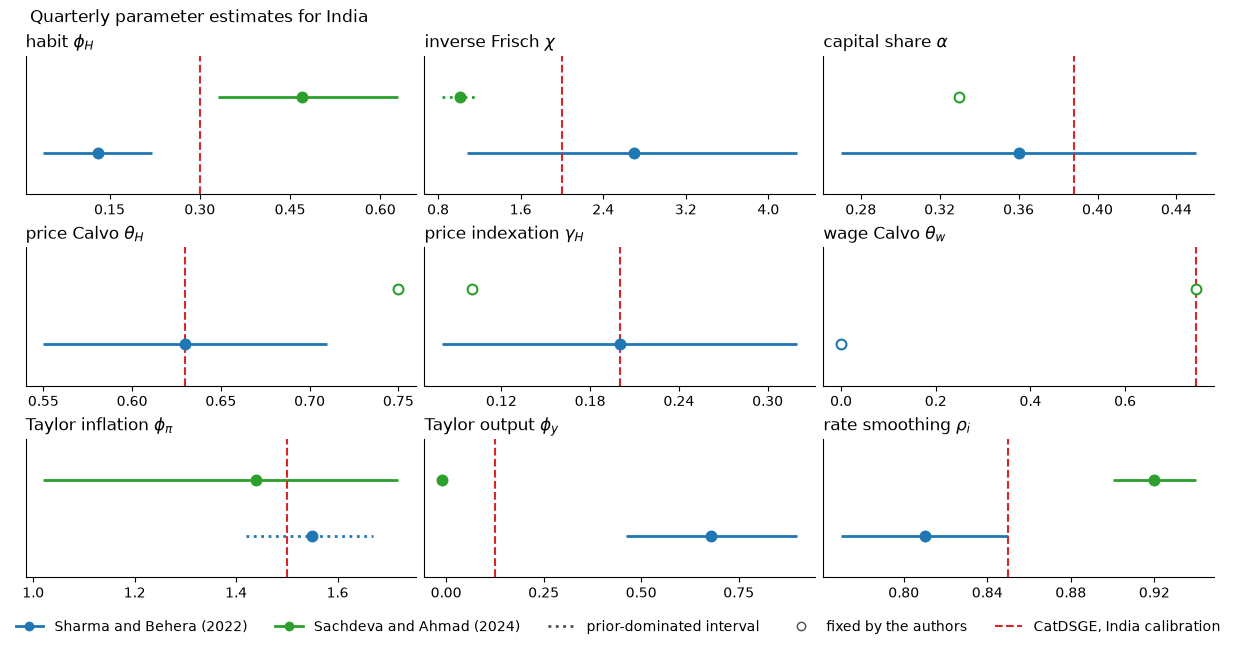

In [11]:
SOURCE_COLORS = dict(zip(SOURCES, [PALETTE["primary"], "tab:green"], strict=True))
CATDSGE_COLOR = PALETTE["secondary"]


def plot_estimate(ax, row, y_position):
    color = SOURCE_COLORS[row.source]
    if np.isfinite(row.lower):
        ax.hlines(y=y_position,
                  xmin=row.lower,
                  xmax=row.upper,
                  color=color,
                  ls=":" if row.status == "prior-dominated" else "-",
                  lw=2.0)
    ax.scatter(x=row.value,
               y=y_position,
               s=50,
               color="white" if row.status == "fixed" else color,
               edgecolor=color,
               linewidth=1.5,
               zorder=3)


fig, axes = plt.subplots(nrows=3,
                         ncols=3,
                         figsize=(12, 6),
                         layout="constrained")
for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items(), strict=True):
    estimates = literature[literature["parameter"] == parameter]
    for y_position, row in enumerate(estimates.itertuples()):
        plot_estimate(ax=ax, row=row, y_position=y_position)

    ax.axvline(x=india_parameters[parameter],
               color=CATDSGE_COLOR,
               ls="--",
               lw=1.5)
    ax.set_title(label, loc="left")
    ax.set(yticks=[], ylim=(-0.75, 1.75))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.grid(visible=False, axis="y")

source_handles = [plt.Line2D([], [], color=color, marker="o", lw=2.0, label=source)
                  for source, color in SOURCE_COLORS.items()]
marker_handles = [plt.Line2D([], [], color="0.3", ls=":", lw=2.0, label="prior-dominated interval"),
                  plt.Line2D([],
                             [],
                             color="0.3",
                             marker="o",
                             markerfacecolor="white",
                             lw=0.0,
                             label="fixed by the authors"),
                  plt.Line2D([], [], color=CATDSGE_COLOR, ls="--", lw=1.5, label="CatDSGE, India calibration")]
fig.legend(handles=source_handles + marker_handles,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.07),
           ncol=len(source_handles + marker_handles),
           frameon=False)
fig.suptitle("Quarterly parameter estimates for India", x=0.01, ha="left");

## 3. CatDSGE

A small open economy New Keynesian model. Households consume, work, invest, and hold domestic government bonds and foreign bonds. Domestic firms produce with capital and labor. A bundler combines domestic output with imports into the final good used for consumption, investment and government spending. Importers, exporters, domestic firms and unions each set prices under Calvo contracts. The central bank follows a Taylor rule, the government finances spending with distortionary taxes and a lump-sum tax that stabilizes debt, and the rest of the world is a three-equation block.

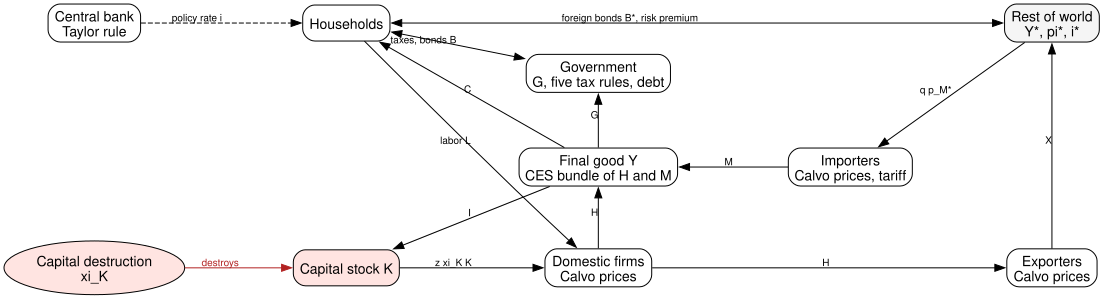

In [12]:
DESTRUCTION_COLOR = "firebrick"

flows = graphviz.Digraph(engine="neato",
                         graph_attr={"splines": "true", "fontname": "Helvetica"},
                         node_attr={"shape": "box",
                                    "style": "rounded,filled",
                                    "fillcolor": "white",
                                    "fontname": "Helvetica"},
                         edge_attr={"fontname": "Helvetica", "fontsize": "10"})

for name, (label, (x, y), style) in {"central_bank": ("Central bank\nTaylor rule", (0.0, 3.9), {}),
                                     "household": ("Households", (3.5, 3.9), {}),
                                     "government": ("Government\nG, five tax rules, debt", (7.0, 3.2), {}),
                                     "world": ("Rest of world\nY*, pi*, i*", (13.3, 3.9), {"fillcolor": "whitesmoke"}),
                                     "bundler": ("Final good Y\nCES bundle of H and M", (7.0, 1.9), {}),
                                     "importer": ("Importers\nCalvo prices, tariff", (10.5, 1.9), {}),
                                     "disaster": ("Capital destruction\nxi_K",
                                                  (0.0, 0.5),
                                                  {"shape": "ellipse", "fillcolor": "mistyrose"}),
                                     "capital": ("Capital stock K", (3.5, 0.5), {"fillcolor": "mistyrose"}),
                                     "firm": ("Domestic firms\nCalvo prices", (7.0, 0.5), {}),
                                     "exporter": ("Exporters\nCalvo prices", (13.3, 0.5), {})}.items():
    flows.node(name, label, pos=f"{x},{y}!", **style)

for tail, head, label, style in [("central_bank", "household", "policy rate i", {"style": "dashed"}),
                                 ("household", "government", "taxes, bonds B", {"dir": "both"}),
                                 ("household", "world", "foreign bonds B*, risk premium", {"dir": "both"}),
                                 ("household", "firm", "labor L", {}),
                                 ("disaster",
                                  "capital",
                                  "destroys",
                                  {"color": DESTRUCTION_COLOR, "fontcolor": DESTRUCTION_COLOR}),
                                 ("capital", "firm", "z xi_K K", {}),
                                 ("firm", "bundler", "H", {}),
                                 ("firm", "exporter", "H", {}),
                                 ("exporter", "world", "X", {}),
                                 ("world", "importer", "q p_M*", {}),
                                 ("importer", "bundler", "M", {}),
                                 ("bundler", "household", "C", {}),
                                 ("bundler", "government", "G", {}),
                                 ("bundler", "capital", "I", {})]:
    flows.edge(tail, head, label=label, **style)

flows

### Capital destruction

A disaster destroys a fraction $1 - \xi_{K,t}$ of the installed capital stock. The shock is i.i.d., so the loss happens once and is permanent in the level of $K$ until investment rebuilds it. The destroyed capital also stops earning rent, and households choose how hard to run what remains through utilization $z_t$ at cost $\Psi(z_t)$ per unit of effective capital.

$$\begin{aligned}
K_t &= (1 - \delta)\,\xi_{K,t} K_{t-1} + I_t \left[1 - \frac{\gamma_I}{2}\left(\frac{\xi_{I,t} I_t}{I_{t-1}} - 1\right)^2\right] \\
\log \xi_{K,t} &= \varepsilon_{\xi_K,t} \\
H_t &= A_t \left(z_t\, \xi_{K,t} K_{t-1}\right)^{\alpha} L_t^{1-\alpha} \\
\Psi(z_t) &= \psi_{z,1}(z_t - 1) + \frac{\psi_z}{2}(z_t - 1)^2
\end{aligned}$$

### Households

Consumption has external habit $\phi_H$ and labor disutility has curvature $\chi$, the inverse Frisch elasticity. Consumption is taxed, investment is not.

$$\begin{aligned}
u_t &= \frac{(C_t - \phi_H C_{t-1})^{1-\sigma}}{1-\sigma} - \Theta\, \nu_{w,t} \frac{L_t^{1+\chi}}{1+\chi} \\
(1 + \tau_C) C_t + I_t + B_t + q_t B^*_t + \Psi(z_t)\,\xi_{K,t} K_{t-1} &= (1 - \tau_K) r_t z_t \xi_{K,t} K_{t-1} + (1 - \tau_{L,t}) w_t L_t + \frac{1 + i_{t-1}}{\pi_t} B_{t-1} \\
&\quad + q_t \frac{(1 + i^*_{t-1})\Phi_{B,t-1}}{\pi^*_t} B^*_{t-1} + \Pi_{H,t} + \Pi_{X,t} + \Pi_{M,t} - T_t
\end{aligned}$$

### Open economy

The final good bundles domestic output and imports with elasticity $\psi_Y$. Foreign demand for exports depends on their price relative to the real exchange rate $q_t$. Foreign borrowing carries a premium that rises with net foreign debt, which pins down the steady-state net foreign asset position.

$$\begin{aligned}
Y_t &= \left[\alpha_Y^{1/\psi_Y} H_{H,t}^{(\psi_Y - 1)/\psi_Y} + (1 - \alpha_Y)^{1/\psi_Y} M_t^{(\psi_Y - 1)/\psi_Y}\right]^{\psi_Y/(\psi_Y - 1)} \\
X_t &= (1 - \alpha^*_Y)\left(\frac{p_{X,t}}{q_t}\right)^{-\psi^*_Y} Y^*_t \\
\Phi_{B,t} &= \exp\left[-\psi_B\left(\frac{q_t B^*_t}{Y_t} - \phi_B\right)\right] \\
\mathrm{GDP}_t &= Y_t + p_{X,t} X_t - q_t p^*_{M,t} \nu_{M,t} M_t
\end{aligned}$$

### Prices under trend inflation

Domestic producers, importers, exporters and unions each reset prices with probability $1 - \theta$ and otherwise index to past inflation with weight $\gamma$. The central bank targets gross inflation $\bar\pi$, which is 4.7% a year here. Away from zero inflation, non-resetting firms fall further behind each quarter, and partial indexation keeps the model determinate at India's target. The domestic price index and the policy rule are

$$\begin{aligned}
1 &= \theta_H \left(\frac{\pi_{H,t}}{\pi_{H,t-1}^{\gamma_H}}\right)^{\psi_H - 1} + (1 - \theta_H)\, \tilde p_{H,t}^{\,1 - \psi_H} \\
\log(1 + i_t) &= \rho_i \log(1 + i_{t-1}) + (1 - \rho_i)\left[\log(1 + \bar i) + \phi_\pi \log\frac{\pi_t}{\bar\pi} + \phi_y \log\frac{Y_t}{\bar Y} + \phi_q \log\frac{q_t}{\bar q}\right] + \varepsilon_{i,t}
\end{aligned}$$

Domestic prices and wages carry persistent markup shocks. Importers and exporters carry i.i.d. markup shocks added to their reset-price conditions, $\tilde p_{M,t} = \frac{\psi_M}{\psi_M - 1} \frac{z_{1,M,t}}{z_{2,M,t}} + \varepsilon_{\xi_M,t}$ and the same for exports, following the gEcon implementation of Smets and Wouters (2003) by Klima, Podemski, Retkiewicz-Wijtiwiak and Sowinska (2015).

### Fiscal policy

The consumption, capital income and export tax rates are constant. The labor tax responds to output and the import tariff follows an AR(1), and both take estimated shocks. The lump-sum tax $T_t$ alone responds to debt, so debt is stabilized without moving any distortionary rate, and $\phi_{\text{debt}}$ sets how fast it returns to target. Government spending is an AR(1) in logs.

$$
\begin{aligned}
\tau_{L,t} &= \rho_{\tau_L} \tau_{L,t-1} + (1 - \rho_{\tau_L})\left[\bar\tau_L + \phi_{\tau_L}\left(\frac{Y_t}{\bar Y} - 1\right)\right] + \varepsilon_{\tau_L,t} \\
\tau_{M,t} &= \rho_{\tau_M} \tau_{M,t-1} + (1 - \rho_{\tau_M})\bar\tau_M + \varepsilon_{\tau_M,t} \\
T_t &= \bar T + \phi_{\text{debt}}\left(B_{t-1} - b^{\text{target}} Y_{t-1}\right) \\
B_t &= \frac{1 + i_{t-1}}{\pi_t} B_{t-1} + G_t - \tau_C C_t - \tau_K r_t z_t \xi_{K,t} K_{t-1} - \tau_{L,t} w_t L_t - \tau_{M,t} q_t p^*_{M,t} \nu_{M,t} M_t - \tau_X p_{X,t} X_t - T_t
\end{aligned}
$$

## 4. Impulse responses at the India calibration

Quantities are percent deviations from steady state, and inflation and the policy rate are annualized percentage-point deviations, over ten years. The capital destruction shock is $-0.10$ to the log of surviving capital, a loss of 9.5% of the stock, called 10% throughout. The policy-rate shock is 100 basis points at an annual rate.

In [13]:
IRF_QUARTERS = 40
SHOCK_SIZES = {"epsilon_xi_K": -0.10,
               "epsilon_A": -0.01,
               "epsilon_i": 0.01 / QUARTERS_PER_YEAR,
               "epsilon_G": 0.05,
               "epsilon_p_M_star": 0.10,
               "epsilon_q": 0.05,
               "epsilon_Y_star": -0.01}

india_steady_state = model.steady_state(verbose=False,
                                        progressbar=False,
                                        **india_parameters)
india_irf = ge.impulse_response_function(model,
                                         simulation_length=IRF_QUARTERS,
                                         shock_size=SHOCK_SIZES,
                                         verbose=False,
                                         **india_parameters)["deviation"].reset_coords(drop=True)

In [14]:
VARIABLE_LABELS = {"GDP": "GDP (%)",
                   "C": "consumption (%)",
                   "I": "investment (%)",
                   "K": "capital stock (%)",
                   "L": "hours (%)",
                   "z": "utilization (%)",
                   "w": "real wage (%)",
                   "pi": "inflation (pp, annual)",
                   "i": "policy rate (pp, annual)",
                   "X": "exports (%)",
                   "M": "imports (%)",
                   "B": "government debt (%)"}
SHOCK_LABELS = {"epsilon_xi_K": "10% capital destruction",
                "epsilon_A": "1% fall in productivity",
                "epsilon_i": "100 bp policy rate rise",
                "epsilon_G": "5% rise in government spending",
                "epsilon_p_M_star": "10% rise in world import prices",
                "epsilon_q": "5% real depreciation",
                "epsilon_Y_star": "1% fall in foreign output"}


def to_display_units(irf, variable, policy_rate_ss):
    """Percent deviation for quantities, annualized percentage points for inflation and the policy rate."""
    response = irf.sel(variable=variable)
    if variable == "pi":
        return 100 * QUARTERS_PER_YEAR * response
    if variable == "i":
        return 100 * QUARTERS_PER_YEAR * policy_rate_ss * np.expm1(response)
    return 100 * response


def plot_responses(irf, shocks, variables, policy_rate_ss, n_cols=4):
    n_rows = int(np.ceil(len(variables) / n_cols))
    fig, axes = plt.subplots(nrows=n_rows,
                             ncols=n_cols,
                             figsize=(3.5 * n_cols, 2.4 * n_rows),
                             sharex=True,
                             layout="constrained")
    colors = plt.colormaps["tab10"].colors

    for ax, variable in zip(axes.flat, variables, strict=True):
        for shock, color in zip(shocks, colors, strict=False):
            response = to_display_units(irf=irf.sel(shock=shock),
                                        variable=variable,
                                        policy_rate_ss=policy_rate_ss)
            response.plot.line(x="time",
                               ax=ax,
                               color=color,
                               label=SHOCK_LABELS[shock])
        ax.axhline(y=0, color="0.3", lw=0.8)
        ax.set_title(VARIABLE_LABELS[variable], loc="left")
        ax.set(xlabel="", ylabel="")
    for ax in axes[-1]:
        ax.set_xlabel("quarters")

    if len(shocks) > 1:
        handles, labels = axes.flat[0].get_legend_handles_labels()
        fig.legend(handles=handles,
                   labels=labels,
                   loc="lower center",
                   bbox_to_anchor=(0.5, -0.06),
                   ncol=len(labels),
                   frameon=False)
    return fig

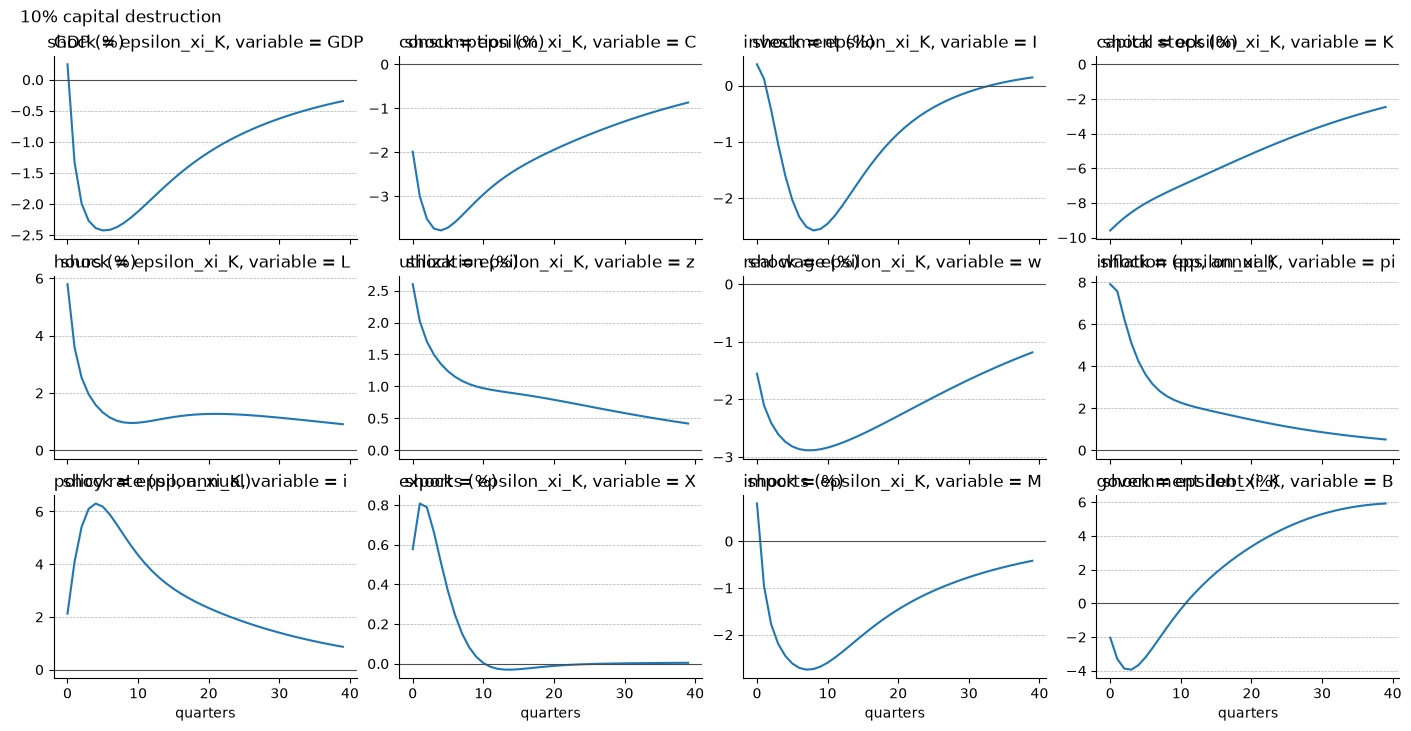

In [15]:
fig = plot_responses(irf=india_irf,
                     shocks=["epsilon_xi_K"],
                     variables=list(VARIABLE_LABELS),
                     policy_rate_ss=india_steady_state["i_ss"])
fig.suptitle(SHOCK_LABELS["epsilon_xi_K"], x=0.01, ha="left");

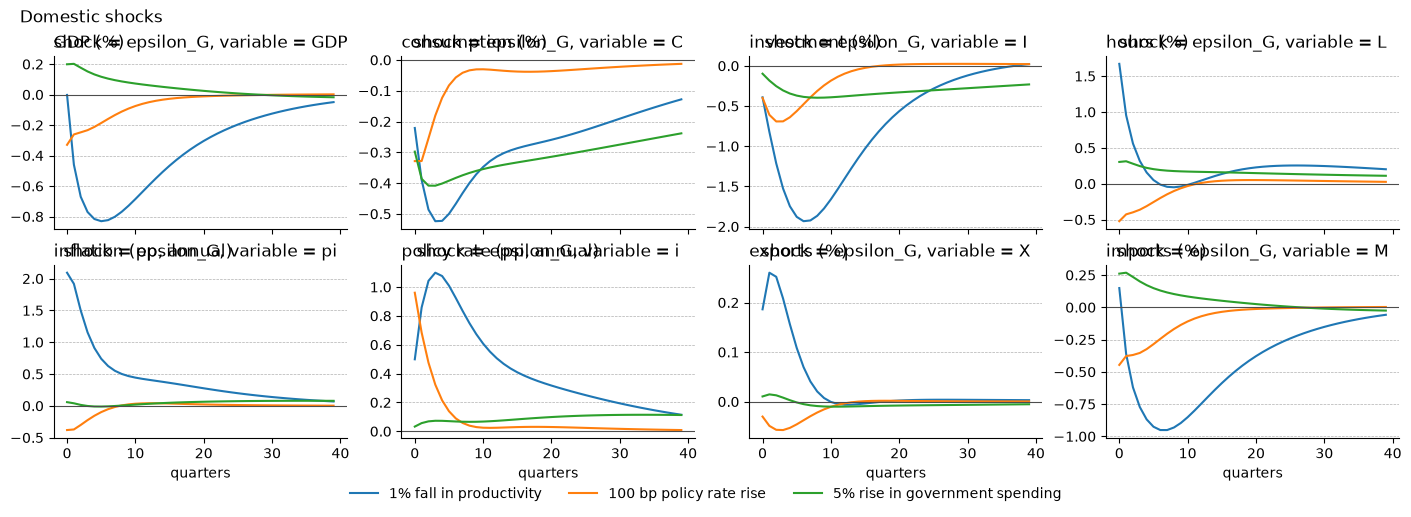

In [16]:
COMPARISON_VARIABLES = ["GDP", "C", "I", "L", "pi", "i", "X", "M"]

fig = plot_responses(irf=india_irf,
                     shocks=["epsilon_A", "epsilon_i", "epsilon_G"],
                     variables=COMPARISON_VARIABLES,
                     policy_rate_ss=india_steady_state["i_ss"])
fig.suptitle("Domestic shocks", x=0.01, ha="left");

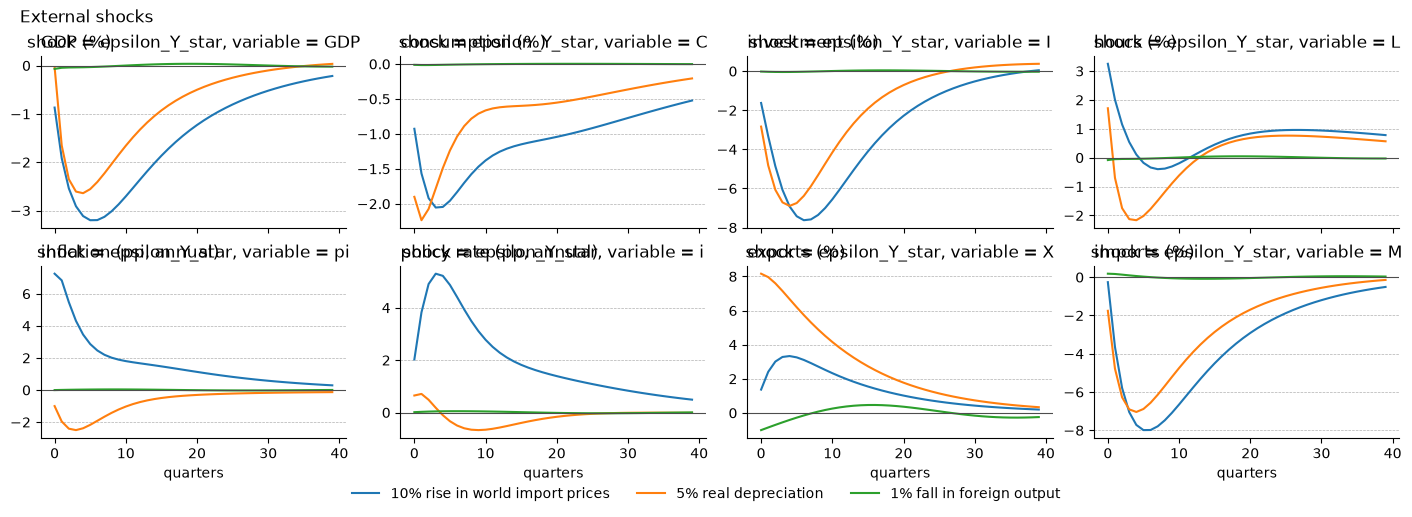

In [17]:
fig = plot_responses(irf=india_irf,
                     shocks=["epsilon_p_M_star", "epsilon_q", "epsilon_Y_star"],
                     variables=COMPARISON_VARIABLES,
                     policy_rate_ss=india_steady_state["i_ss"])
fig.suptitle("External shocks", x=0.01, ha="left");

Whether GDP falls on impact after capital destruction depends mostly on two parameters. Habit makes households smooth consumption by working more, and a low utilization cost lets them run the surviving capital harder. The contour marks where the impact response of GDP changes sign. The two papers' estimates are converted to CatDSGE's utilization parameter with $\psi_z = (a''/a')\,\psi_{z,1}$.

In [18]:
def impact_response(variable, shock_name, **updates):
    _, impact_matrix = model.solve_model(verbose=False,
                                         return_matrices=True,
                                         **{**india_parameters, **updates})
    return ge.matrix_to_dataframe(impact_matrix, model).loc[variable, shock_name] * SHOCK_SIZES[shock_name]


phi_H_grid = np.linspace(0.0, 0.9, 19)
psi_z_grid = np.geomspace(0.01, 10.0, 19)
impact_gdp = xr.DataArray([[impact_response(variable="GDP", shock_name="epsilon_xi_K", phi_H=phi_H, psi_z=psi_z)
                            for phi_H in phi_H_grid]
                           for psi_z in psi_z_grid],
                          dims=["psi_z", "phi_H"],
                          coords={"psi_z": psi_z_grid, "phi_H": phi_H_grid})

In [19]:
india_model_parameters = model.parameters(**india_parameters)
habit_estimates = literature[literature["parameter"] == "phi_H"].set_index("source")["value"]

# Sharma and Behera report a''/a' directly. Sachdeva and Ahmad report psi, with a''/a' = psi / (1 - psi).
literature_points = pd.DataFrame({"phi_H": habit_estimates,
                                  "psi_z": pd.Series({SOURCES[0]: 0.58, SOURCES[1]: 0.78 / (1 - 0.78)})
                                           * india_model_parameters["psi_z_1"]})

In [20]:
def plot_impact_heatmap(impact):
    fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
    mesh = ax.pcolormesh(phi_H_grid,
                         psi_z_grid,
                         100 * impact.values,
                         cmap="RdBu",
                         norm=TwoSlopeNorm(vcenter=0.0),
                         shading="auto")
    contour = ax.contour(phi_H_grid,
                         psi_z_grid,
                         impact.values,
                         levels=[0.0],
                         colors="k",
                         linewidths=1.5)
    ax.clabel(contour, fmt={0.0: "GDP = 0"})

    for source, color in SOURCE_COLORS.items():
        ax.scatter(x=literature_points.loc[source, "phi_H"],
                   y=literature_points.loc[source, "psi_z"],
                   s=90,
                   color=color,
                   edgecolor="k",
                   zorder=10,
                   label=source)

    ax.set(yscale="log",
           xlim=(phi_H_grid[0], phi_H_grid[-1]),
           ylim=(psi_z_grid[0], psi_z_grid[-1]),
           xlabel=r"habit persistence $\phi_H$",
           ylabel=r"utilization cost curvature $\psi_z$")
    ax.grid(visible=False)

    colorbar = fig.colorbar(mesh, ax=ax, label="GDP at impact (%)")
    colorbar.ax.set_yscale("linear")
    return fig, ax


def add_bottom_legend(fig, n_cols):
    fig.legend(loc="lower center",
               bbox_to_anchor=(0.5, -0.08),
               ncol=n_cols,
               frameon=False)

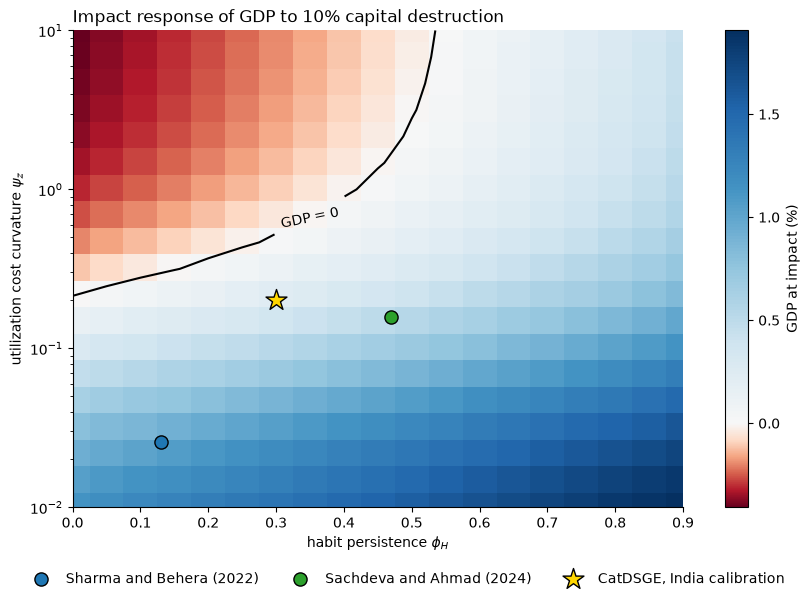

In [21]:
fig, ax = plot_impact_heatmap(impact_gdp)
ax.scatter(x=india_model_parameters["phi_H"],
           y=india_model_parameters["psi_z"],
           marker="*",
           s=250,
           color="gold",
           edgecolor="k",
           zorder=10,
           label="CatDSGE, India calibration")
ax.set_title("Impact response of GDP to 10% capital destruction", loc="left")
add_bottom_legend(fig, n_cols=3)

## 5. Fit to Indian data

The log-linearized model is fit over 2012Q1 to 2024Q4 to quarterly growth of GDP, consumption, investment, exports and imports, CPI inflation, and real depreciation of the rupee. Four foreign series pin down the rest-of-world block, all of them US or world aggregates: the US 3-month rate for the foreign interest rate, US CPI inflation for foreign inflation, quarterly growth of US real GDP for foreign output, and real growth of the broad commodity price index for the world import price. The lockdown quarters 2020Q1 to 2021Q4 are treated as missing.

Capital destruction is a disaster outside the economy's normal dynamics, so the estimation model has no capital destruction shock. Section 9 adds it back to the estimated model to study a disaster.

In [22]:
statespace = ge.statespace_from_gcn(GCN_DIR / "catdsge_v4_estimation.gcn",
                                    not_loglin_variables=["B_star", "T_lump", "u_C"])

In [23]:
GROWTH_OBSERVABLES = {"gdp_growth": ("gdp", "GDP"),
                      "consumption_growth": ("consumption", "C"),
                      "investment_growth": ("investment", "I"),
                      "export_growth": ("exports", "X"),
                      "import_growth": ("imports", "M")}
# Observables whose measured log level carries i.i.d. noise, which enters their growth rate as u[] - u[-1].
LEVEL_NOISE_STATES = {"consumption_growth": "u_C"}
OPEN_ECONOMY_OBSERVATION_EQUATIONS = {"real_exchange_rate_growth": "log(q[]) - log(q[-1])",
                                      "foreign_rate": "log(1 + i_star[]) - log(1 + i_star[ss])",
                                      "foreign_inflation": "log(pi_star[])",
                                      "foreign_output_growth": "log(Y_star[]) - log(Y_star[-1])",
                                      "world_import_price_growth": "log(p_M_star[]) - log(p_M_star[-1])"}
TAX_REVENUE = ("(tau_C * C[] + tau_K * r[] * z[] * K[-1] + tau_L[] * w[] * L[]"
               " + tau_M[] * q[] * p_M_star[] * nu_M[] * M[] + tau_X * p_X[] * X[])")
STEADY_STATE_TAX_REVENUE = TAX_REVENUE.replace("[-1]", "[ss]").replace("[]", "[ss]")
FISCAL_OBSERVATION_EQUATIONS = {"debt_ratio": f"log(B[]) - log({QUARTERS_PER_YEAR} * GDP[])",
                                "tax_revenue_ratio": f"log({TAX_REVENUE}) - log(GDP[])"
                                                     f" - (log({STEADY_STATE_TAX_REVENUE}) - log(GDP[ss]))"}
ANNUAL_OBSERVABLES = [*FISCAL_OBSERVATION_EQUATIONS]
OBSERVED_STATES = [*GROWTH_OBSERVABLES, "pi", *OPEN_ECONOMY_OBSERVATION_EQUATIONS, *ANNUAL_OBSERVABLES]
MOMENT_STATES = [name for name in OBSERVED_STATES if name not in ANNUAL_OBSERVABLES]
TEMPORAL_AGGREGATION = {"tax_revenue_ratio": "mean"}


def growth_observation_equation(name, variable):
    equation = f"log({variable}[]) - log({variable}[-1])"
    if name in LEVEL_NOISE_STATES:
        noise = LEVEL_NOISE_STATES[name]
        equation += f" + {noise}[] - {noise}[-1]"
    return equation


statespace.configure(observed_states=OBSERVED_STATES,
                     measurement_error=OBSERVED_STATES,
                     full_shock_covariance=True,
                     ss_obs_intercept=["pi"],
                     observation_equations={**{name: growth_observation_equation(name, variable)
                                               for name, (_, variable) in GROWTH_OBSERVABLES.items()},
                                            **OPEN_ECONOMY_OBSERVATION_EQUATIONS,
                                            **FISCAL_OBSERVATION_EQUATIONS},
                     temporal_aggregation=TEMPORAL_AGGREGATION,
                     aggregation_period=QUARTERS_PER_YEAR,
                     solver="scan_cycle_reduction",
                     mode="JAX",
                     verbose=False)

real_effective_exchange_rate = panel["real_effective_exchange_rate"]
world_inflation = np.log(panel["world_price_level"]).diff()

# The World Bank series covers central government tax revenue only, so its level sits far below the model's and
# only deviations are observed. Its FY2022 reading, 6.9% against 10 to 12% in every earlier year, is a break in
# the series.
log_tax_revenue_ratio = np.log(panel["tax_revenue_gdp"]).loc[:"2022Q4"]

# A rise in the BIS index is a real appreciation of the rupee, the opposite direction to the model's q.
observed = pd.DataFrame({**{name: np.log(panel[column]).diff() for name, (column, _) in GROWTH_OBSERVABLES.items()},
                         "pi": np.log(panel["cpi"]).diff(),
                         "real_exchange_rate_growth": -np.log(real_effective_exchange_rate).diff(),
                         "foreign_rate": np.log1p(panel["world_rate_3m"] / 100) / QUARTERS_PER_YEAR,
                         "foreign_inflation": world_inflation,
                         "foreign_output_growth": np.log(panel["world_output"]).diff(),
                         "world_import_price_growth": np.log(panel["commodity_all"]).diff() - world_inflation,
                         "debt_ratio": np.log(panel["government_debt"]),
                         "tax_revenue_ratio": log_tax_revenue_ratio}).loc["2012Q1":"2024Q4"]
observed.loc["2020Q1":"2021Q4"] = np.nan
# National accounts exports jump 20% in 2012Q3 and fall 21% in 2012Q4, while customs goods exports in dollars fall
# 3% and rise 2%, so both quarters are treated as missing.
observed.loc["2012Q3":"2012Q4", "export_growth"] = np.nan
demeaned = [*GROWTH_OBSERVABLES, *OPEN_ECONOMY_OBSERVATION_EQUATIONS, "tax_revenue_ratio"]
observed[demeaned] -= observed[demeaned].mean()

(100 * observed).describe().T[["count", "mean", "std"]]

,count,mean,std
gdp_growth,44.00,-0.00,0.79
consumption_growth,44.00,-0.00,1.78
investment_growth,44.00,-0.00,2.26
export_growth,42.00,0.00,3.56
import_growth,44.00,0.00,5.07
pi,44.00,1.42,0.79
real_exchange_rate_growth,44.00,-0.00,2.15
foreign_rate,44.00,0.00,0.46
foreign_inflation,44.00,-0.00,0.51
foreign_output_growth,44.00,-0.00,0.36


The real exchange rate is the BIS broad real effective exchange rate of the rupee, against 64 economies, averaged to quarters. A rise in the index is a real appreciation of the rupee, the opposite direction to the model's $q_t$, so the observable is minus its log change.

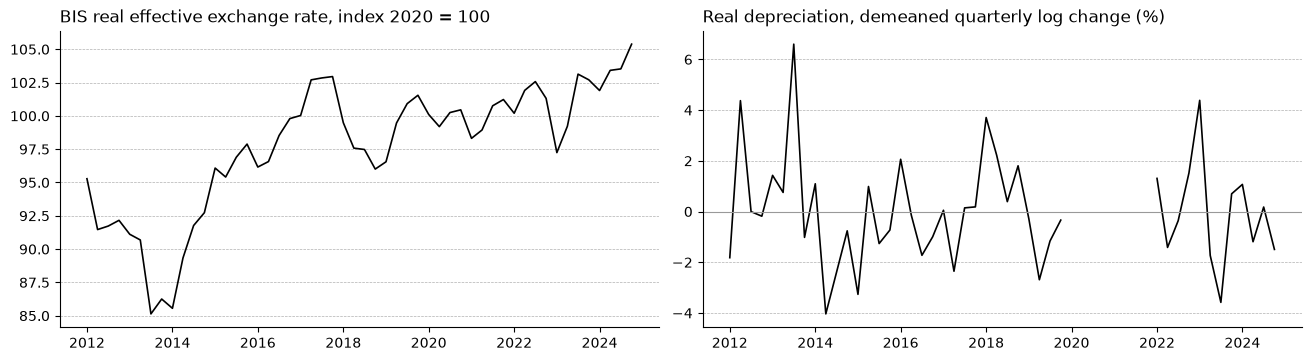

In [24]:
window_dates = observed.index.to_timestamp()
fig, axes = plt.subplots(ncols=2,
                         figsize=(13, 3.5),
                         layout="constrained")
axes[0].plot(window_dates,
             real_effective_exchange_rate.loc["2012Q1":"2024Q4"],
             color="k",
             lw=1.2)
axes[0].set_title("BIS real effective exchange rate, index 2020 = 100", loc="left")
axes[1].plot(window_dates,
             100 * observed["real_exchange_rate_growth"],
             color="k",
             lw=1.2)
axes[1].axhline(0.0, color="0.6", lw=0.8)
axes[1].set_title("Real depreciation, demeaned quarterly log change (%)", loc="left");

### Priors

Structural priors are centered on the estimates of section 2. The wage Calvo parameter $\theta_w$ is sampled through the log of its Phillips-curve slope $\kappa_w = (1 - \theta_w)(1 - \beta\theta_w)/\theta_w$, which avoids the funnel near $\theta_w = 1$ where the slope goes to zero. The prior on $\log \kappa_w$ matches a Beta prior on $\theta_w$ with mean 0.75 and standard deviation 0.05, a 95% interval of 0.64 to 0.84.

The 16 estimated shocks have a full covariance. Their correlations have an LKJ prior with $\eta = 4$, and each standard deviation has an inverse gamma prior with shape 3 and its mode at a typical quarterly size for that shock. The LKJ factor is sampled in units of those modes, so its entries are of order one.

Each observable's measurement error variance is a share $s_j$ of a reference variance $v_j$. For growth and inflation rates $v_j$ is the sample variance of the series. For the four series observed in levels (the foreign rate, foreign output, and the debt and tax ratios) it is the variance of their period-to-period changes, which is the scale the shocks move them on. The shares are pooled on the logit scale within two groups $g(j)$: the Indian series, centered on a share of 5%, and the four foreign series, centered on 2%, since those come from the statistical systems of large economies. The prior puts 94% of each share between 2% and 11% for Indian series and between 1% and 4% for foreign ones.

$$
\begin{aligned}
\sigma_{e,j} &= \sqrt{s_j v_j} \\
\operatorname{logit} s_j &= \mu_{g(j)} + \tau z_j, \quad z_j \sim N(0, 1) \\
\mu_{\text{domestic}} &\sim N(\operatorname{logit} 0.05, \; 0.3^2), \quad \mu_{\text{foreign}} \sim N(\operatorname{logit} 0.02, \; 0.3^2) \\
\tau &\sim N^+(0, 0.3^2)
\end{aligned}
$$

In [25]:
STRUCTURAL_PRIORS = {"phi_H": (pm.Beta, 0.30, 0.15),
                     "chi": (pm.Gamma, 2.0, 1.0),
                     "psi_z": (pm.Gamma, 0.20, 0.15),
                     "gamma_I": (pm.Gamma, 5.0, 2.0),
                     "theta_H": (pm.Beta, 0.63, 0.10),
                     "gamma_H": (pm.Beta, 0.20, 0.10),
                     "phi_pi": (pm.Gamma, 1.5, 0.25),
                     "phi_y": (pm.Gamma, 0.125, 0.05),
                     "rho_i": (pm.Beta, 0.85, 0.05),
                     "phi_debt": (pm.Gamma, 0.083, 0.039)}
WAGE_SLOPE_PRIOR = {"mu": -2.51, "sigma": 0.47}

# Units are those the shock enters its equation in: log deviations for quantities and prices, quarterly rates for
# the two policy rates, levels for the two tax rates, and shares of the reset price for the two trade markups. The
# world import price mode matches the 6.5% sd of its quarterly growth, which is 1.08 shock sds under its AR(1) with
# persistence 0.7.
SHOCK_SCALE_MODES = {"epsilon_A": 0.007,
                     "epsilon_beta": 0.003,
                     "epsilon_xi_I": 0.010,
                     "epsilon_xi_H": 0.010,
                     "epsilon_xi_w": 0.010,
                     "epsilon_q": 0.010,
                     "epsilon_p_M_star": 0.060,
                     "epsilon_Y_star": 0.005,
                     "epsilon_pi_star": 0.003,
                     "epsilon_i_star": 0.001,
                     "epsilon_i": 0.0015,
                     "epsilon_G": 0.015,
                     "epsilon_tau_L": 0.0015,
                     "epsilon_tau_M": 0.0015,
                     "epsilon_xi_M": 0.010,
                     "epsilon_xi_X": 0.010,
                     "epsilon_xi_XD": 0.020}
SHOCK_SCALE_ALPHA = 3.0
SHOCK_CORRELATION_ETA = 4.0

FOREIGN_OBSERVABLES = ["foreign_rate", "foreign_inflation", "foreign_output_growth", "world_import_price_growth"]
# Observed in levels, so their error shares are scaled by the variance of their period-to-period changes.
LEVEL_OBSERVABLES = ["foreign_rate", "debt_ratio", "tax_revenue_ratio"]
TYPICAL_ERROR_SHARES = {"domestic": 0.05, "foreign": 0.02}
ERROR_SHARE_LOGIT_SD = 0.3
ERROR_SHARE_SPREAD_PRIOR = {"sigma": 0.3}

In [26]:
estimated_shocks = list(statespace.shock_names)
noise_shock_observables = {f"epsilon_{state}": name for name, state in LEVEL_NOISE_STATES.items()}
structural_shocks = [shock for shock in estimated_shocks if shock not in noise_shock_observables]
shock_scale_modes = np.array([SHOCK_SCALE_MODES[name] for name in structural_shocks])
discount_factor = india_model_parameters["beta"]

fit_data = observed.set_axis(observed.index.to_timestamp())
observable_names = list(statespace.coords["observed_state"])
# The noise sd prior's scale is the noise that would explain all of the observable's variance, var(growth) / 2.
noise_sd_scales = {shock: fit_data[name].std() / np.sqrt(2) for shock, name in noise_shock_observables.items()}
# Structural shocks first, then noise shocks, mapped back to the state space's shock order.
shock_order = np.array([[*structural_shocks, *noise_shock_observables].index(shock) for shock in estimated_shocks])


def error_scale(name):
    """Sd of an observable, or of its changes for one observed in levels, over the periods it is observed."""
    series = fit_data[name].dropna() if name in ANNUAL_OBSERVABLES else fit_data[name]
    return series.diff().std() if name in LEVEL_OBSERVABLES else series.std()


observable_sd = np.array([error_scale(name) for name in observable_names])

error_groups = list(TYPICAL_ERROR_SHARES)
error_group_index = np.array([error_groups.index("foreign" if name in FOREIGN_OBSERVABLES else "domestic")
                              for name in observable_names])
typical_error_logits = np.array([np.log(share / (1 - share)) for share in TYPICAL_ERROR_SHARES.values()])

estimated_parameters = {*STRUCTURAL_PRIORS, "theta_w"}
fixed_parameters = {name: india_model_parameters[name]
                    for name in statespace.param_names
                    if not name.startswith("error_") and name != "state_cov" and name not in estimated_parameters}

with pm.Model(coords=statespace.coords | {"error_group": error_groups}) as fit_model:
    for name, (distribution, mean, sd) in STRUCTURAL_PRIORS.items():
        distribution(name, mu=mean, sigma=sd)
    for name in statespace.param_names:
        if name in fixed_parameters:
            pm.Data(name, fixed_parameters[name])

    log_wage_slope = pm.Normal("log_wage_slope", **WAGE_SLOPE_PRIOR)
    slope_sum = 1 + discount_factor + pm.math.exp(log_wage_slope)
    pm.Deterministic("theta_w", (slope_sum - pm.math.sqrt(slope_sum**2 - 4 * discount_factor)) / (2 * discount_factor))

    standardized_cholesky, shock_correlation, standardized_sigmas = pm.LKJCholeskyCov(
        "shock_cov",
        n=len(structural_shocks),
        eta=SHOCK_CORRELATION_ETA,
        sd_dist=pm.InverseGamma.dist(alpha=SHOCK_SCALE_ALPHA, beta=SHOCK_SCALE_ALPHA + 1),
        compute_corr=True)
    shock_cholesky = shock_scale_modes[:, None] * standardized_cholesky
    shock_sigmas = shock_scale_modes * standardized_sigmas
    for index, shock in enumerate(structural_shocks):
        pm.Deterministic(f"sigma_{shock}", shock_sigmas[index])
    noise_sigmas = pt.stack([pm.HalfNormal(f"sigma_{shock}", sigma=noise_sd_scales[shock])
                             for shock in noise_shock_observables])

    block_cov = pt.linalg.block_diag(pm.math.dot(shock_cholesky, shock_cholesky.T), pt.diag(noise_sigmas**2))
    pm.Deterministic("state_cov",
                     block_cov[shock_order][:, shock_order],
                     dims=statespace.param_dims["state_cov"])

    error_share_logit_mean = pm.Normal("error_share_logit_mean",
                                       mu=typical_error_logits,
                                       sigma=ERROR_SHARE_LOGIT_SD,
                                       dims="error_group")
    error_share_spread = pm.HalfNormal("error_share_spread", **ERROR_SHARE_SPREAD_PRIOR)
    error_share_offset = pm.Normal("error_share_offset", dims="observed_state")
    error_share_logit = error_share_logit_mean[error_group_index] + error_share_spread * error_share_offset
    error_share = pm.Deterministic("error_share",
                                   pm.math.sigmoid(error_share_logit),
                                   dims="observed_state")
    for index, name in enumerate(observable_names):
        pm.Deterministic(f"error_sigma_{name}", pt.sqrt(error_share[index]) * observable_sd[index])

    statespace.build_statespace_graph(data=fit_data)

### Posterior mode

The sampler starts from the posterior mode, found with L-BFGS-B on JAX-compiled gradients.

In [27]:
with fit_model:
    map_result = pmx.find_MAP(method="L-BFGS-B",
                              gradient_backend="jax",
                              compile_kwargs={"mode": "JAX"},
                              random_seed=20261014)

map_estimate = map_result.posterior.to_dataset().squeeze(["chain", "draw"], drop=True)
optimizer_result = map_result["optimizer_result"]
pd.Series({"converged": bool(optimizer_result["success"]),
           "message": str(optimizer_result["message"].values),
           "iterations": int(optimizer_result["nit"]),
           "log posterior": -float(optimizer_result["fun"]),
           "max |gradient|": float(np.abs(optimizer_result["jac"]).max())},
          name="L-BFGS-B").to_frame()

Output()

,L-BFGS-B
converged,True
message,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
iterations,96
log posterior,1507.29
max |gradient|,0.02


### NUTS from the MAP

Eight chains start from the MAP plus Gaussian noise with standard deviation 0.1 in the unconstrained space, and run 500 tuning and 250 posterior draws each with nutpie's normalizing-flow adaptation. The transform is refit every 16 tuning draws: the first four refits are diagonal, and every refit after draw 64 trains a flow of 4 coupling layers with SiLU activations on the leapfrog points of the recent trajectories. `03_catdsge_flow_adaptation.ipynb` compares this sampler against a low-rank mass matrix. The trace is saved after sampling and reloaded in the next cells, so everything from section 6 on can be rerun from the saved trace without sampling again.

In [92]:
map_initial_point = {variable.name: map_estimate[variable.name].values for variable in fit_model.free_RVs}
map_nutpie_model = ntp.compile_pymc_model(fit_model,
                                          backend="jax",
                                          gradient_backend="jax",
                                          freeze_model=True,
                                          initial_points=map_initial_point,
                                          jitter_rvs=set())
map_flat = map_nutpie_model._make_initial_points(0)


def jittered_map_point(seed):
    return map_flat + 0.1 * np.random.default_rng(seed).normal(size=map_flat.shape)


# nutpie's own jitter is fixed at U(-1, 1), so the initial-point function is replaced on the frozen dataclass.
jittered_nutpie_model = dataclasses.replace(map_nutpie_model, _make_initial_points=jittered_map_point)

In [93]:
FLOW_ADAPTER_SETTINGS = {"num_diag_windows": 4,
                         "num_layers": 4,
                         "activation": jax.nn.silu,
                         "window_size": 3000,
                         "initial_skip": 500,
                         "max_epochs": 50,
                         "max_patience": 5}

flow_nutpie_model = jittered_nutpie_model.with_transform_adapt(**FLOW_ADAPTER_SETTINGS)
map_init_idata = ntp.sample(flow_nutpie_model,
                            chains=8,
                            cores=8,
                            tune=500,
                            draws=250,
                            adaptation="flow",
                            window_switch_freq=16,
                            train_on_orbit=True,
                            seed=20261014,
                            progress_bar=True)

Progress,Draws,Divergences,Step Size,Gradients/Draw
,750,0,0.38,15
,750,4,0.32,15
,750,0,0.39,15
,750,6,0.36,15
,750,12,0.32,15
,750,0,0.38,15
,750,2,0.37,15
,750,0,0.41,15


In [94]:
map_init_idata.to_netcdf(fit_dir / "catdsge_flow_us_output_idata.nc")

In [28]:
with xr.open_datatree(fit_dir / "catdsge_flow_us_output_idata.nc") as saved_trace:
    map_init_idata = saved_trace.load()

## 6. Sampling checks

Divergences per chain and the parameters with the largest $\hat R$, then the energy distribution of the Hamiltonian transitions.

In [29]:
map_init_diagnostics = az.summary(map_init_idata, kind="diagnostics")
map_init_divergences = map_init_idata.sample_stats["diverging"].sum("draw").to_series()

display(map_init_divergences.rename("post-warmup divergences").to_frame().T)
map_init_diagnostics.sort_values("r_hat", ascending=False).head(15)

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:90: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarning: invalid value encountered in scalar divide
  varsd = varvar / evar / 4
/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/arviz_stats/base/diagnostics.py:313: RuntimeWarn

chain,0,1,2,3,4,5,6,7
post-warmup divergences,0,4,0,6,12,0,2,0


,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
shock_cov[75],2746,1030,1.02,0.0047,0.0073
"shock_cov_corr[8, 2]",2066,1285,1.01,0.0038,0.0051
"shock_cov_corr[2, 8]",2066,1285,1.01,0.0038,0.0051
error_share_offset[import_growth],4336,1667,1.01,0.0072,0.011
shock_cov[97],3202,1584,1.01,0.016,0.024
"shock_cov_corr[4, 1]",2745,1129,1.01,0.004,0.006
"shock_cov_corr[1, 4]",2745,1129,1.01,0.004,0.006
"state_cov[epsilon_Y_star, epsilon_q]",2340,1201,1.01,1.1e-07,1.5e-07
"state_cov[epsilon_q, epsilon_Y_star]",2340,1201,1.01,1.1e-07,1.5e-07
shock_cov[39],4227,1428,1.01,0.0031,0.0065


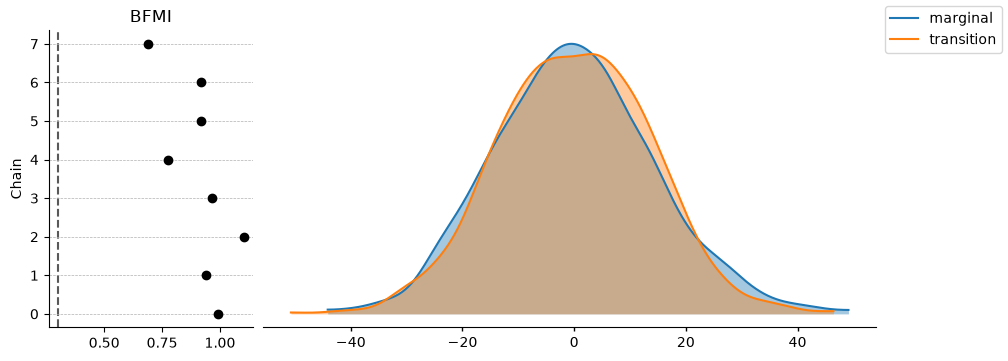

In [30]:
az.plot_energy(map_init_idata,
               figure_kwargs={"figsize": (10, 3.5)});

## 7. Posterior

Posterior summaries of the structural parameters next to the MAP and the published estimates, then each marginal posterior against its prior.

In [31]:
ESTIMATED_STRUCTURAL = [*STRUCTURAL_PRIORS, "theta_w"]

published_values = literature.pivot(index="parameter", columns="source", values="value")
prior_means = pd.Series({**{name: mean for name, (_, mean, _) in STRUCTURAL_PRIORS.items()}, "theta_w": 0.75})
map_values = pd.Series({name: float(map_estimate[name]) for name in ESTIMATED_STRUCTURAL})

posterior_summary = az.summary(map_init_idata,
                               var_names=ESTIMATED_STRUCTURAL,
                               kind="stats")
posterior_summary.insert(loc=0,
                         column="prior mean",
                         value=prior_means)
posterior_summary.insert(loc=1,
                         column="MAP",
                         value=map_values)
posterior_summary.join(published_values).style.format("{:.3f}", na_rep="")

,prior mean,MAP,mean,sd,eti89_lb,eti89_ub,Sachdeva and Ahmad (2024),Sharma and Behera (2022)
phi_H,0.300,0.112,0.168,0.096,0.043,0.348,0.470,0.130
chi,2.000,1.587,1.665,0.821,0.572,3.155,1.010,2.700
psi_z,0.200,0.048,0.244,0.153,0.061,0.527,,
gamma_I,5.000,3.626,5.690,1.912,3.039,9.093,,
theta_H,0.630,0.686,0.708,0.075,0.578,0.815,0.750,0.630
gamma_H,0.200,0.171,0.229,0.109,0.070,0.422,0.100,0.200
phi_pi,1.500,1.467,1.715,0.232,1.357,2.097,1.440,1.550
phi_y,0.125,0.076,0.086,0.035,0.038,0.150,-0.010,0.680
rho_i,0.850,0.923,0.864,0.047,0.780,0.932,0.920,0.810
phi_debt,0.083,0.042,0.061,0.023,0.029,0.101,,


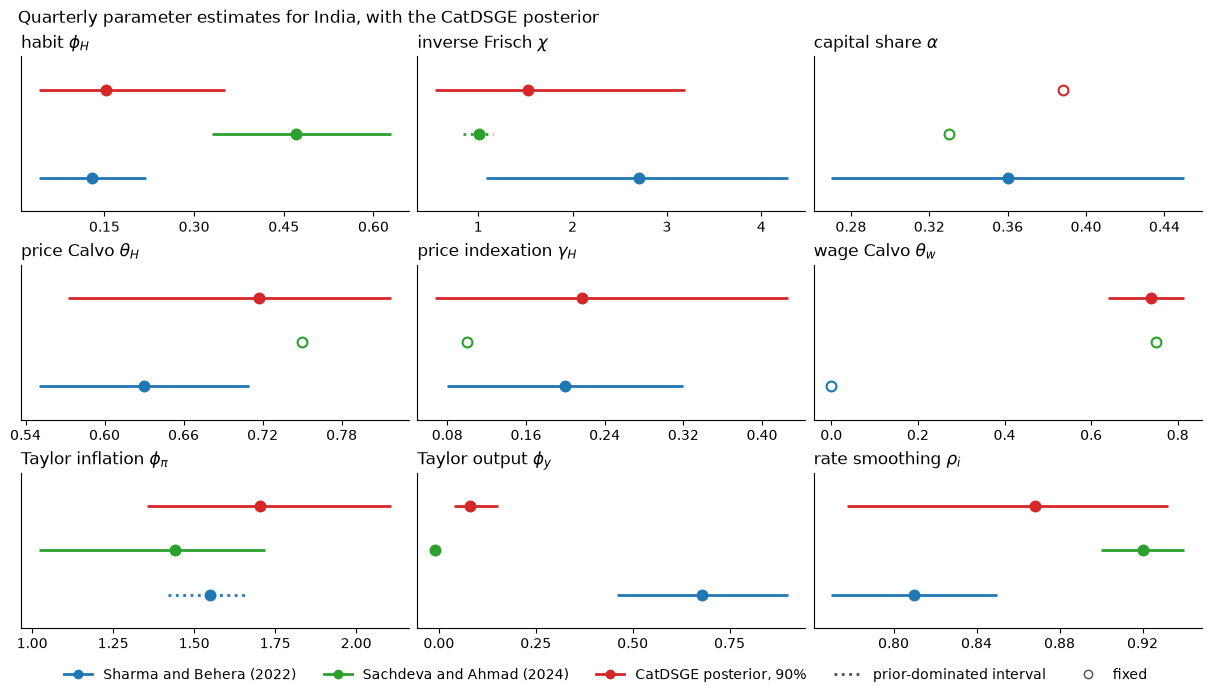

In [32]:
posterior_quantiles = map_init_idata.posterior.to_dataset()[ESTIMATED_STRUCTURAL].quantile([0.05, 0.5, 0.95],
                                                                                           dim=["chain", "draw"])

fig, axes = plt.subplots(nrows=3,
                         ncols=3,
                         figsize=(12, 6.5),
                         layout="constrained")
for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items(), strict=True):
    estimates = literature[literature["parameter"] == parameter]
    for y_position, row in enumerate(estimates.itertuples()):
        plot_estimate(ax=ax, row=row, y_position=y_position)

    catdsge_position = len(estimates)
    if parameter in ESTIMATED_STRUCTURAL:
        quantiles = posterior_quantiles[parameter]
        ax.hlines(y=catdsge_position,
                  xmin=float(quantiles.sel(quantile=0.05)),
                  xmax=float(quantiles.sel(quantile=0.95)),
                  color=CATDSGE_COLOR,
                  lw=2.0)
        ax.scatter(x=float(quantiles.sel(quantile=0.5)),
                   y=catdsge_position,
                   s=50,
                   color=CATDSGE_COLOR,
                   edgecolor=CATDSGE_COLOR,
                   linewidth=1.5,
                   zorder=3)
    else:
        ax.scatter(x=india_parameters[parameter],
                   y=catdsge_position,
                   s=50,
                   color="white",
                   edgecolor=CATDSGE_COLOR,
                   linewidth=1.5,
                   zorder=3)

    ax.set_title(label, loc="left")
    ax.set(yticks=[], ylim=(-0.75, 2.75))
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.grid(visible=False, axis="y")

source_handles = [plt.Line2D([], [], color=color, marker="o", lw=2.0, label=source)
                  for source, color in SOURCE_COLORS.items()]
catdsge_handle = plt.Line2D([], [], color=CATDSGE_COLOR, marker="o", lw=2.0, label="CatDSGE posterior, 90%")
marker_handles = [plt.Line2D([], [], color="0.3", ls=":", lw=2.0, label="prior-dominated interval"),
                  plt.Line2D([],
                             [],
                             color="0.3",
                             marker="o",
                             markerfacecolor="white",
                             lw=0.0,
                             label="fixed")]
legend_handles = source_handles + [catdsge_handle] + marker_handles
fig.legend(handles=legend_handles,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(legend_handles),
           frameon=False)
fig.suptitle("Quarterly parameter estimates for India, with the CatDSGE posterior", x=0.01, ha="left");

In [33]:
SHOCK_SIGMA_NAMES = [f"sigma_{shock}" for shock in estimated_shocks]

# theta_w has no named prior of its own. Its prior is the Beta that WAGE_SLOPE_PRIOR was matched to.
preliz_priors = {name: getattr(pz, distribution.__name__)(mu=mean, sigma=sd)
                 for name, (distribution, mean, sd) in STRUCTURAL_PRIORS.items()}
preliz_priors |= {"theta_w": pz.Beta(mu=0.75, sigma=0.05)}
preliz_priors |= {f"sigma_{shock}": pz.InverseGamma(alpha=SHOCK_SCALE_ALPHA, beta=(SHOCK_SCALE_ALPHA + 1) * mode)
                  for shock, mode in SHOCK_SCALE_MODES.items()}
preliz_priors |= {f"sigma_{shock}": pz.HalfNormal(sigma=scale) for shock, scale in noise_sd_scales.items()}

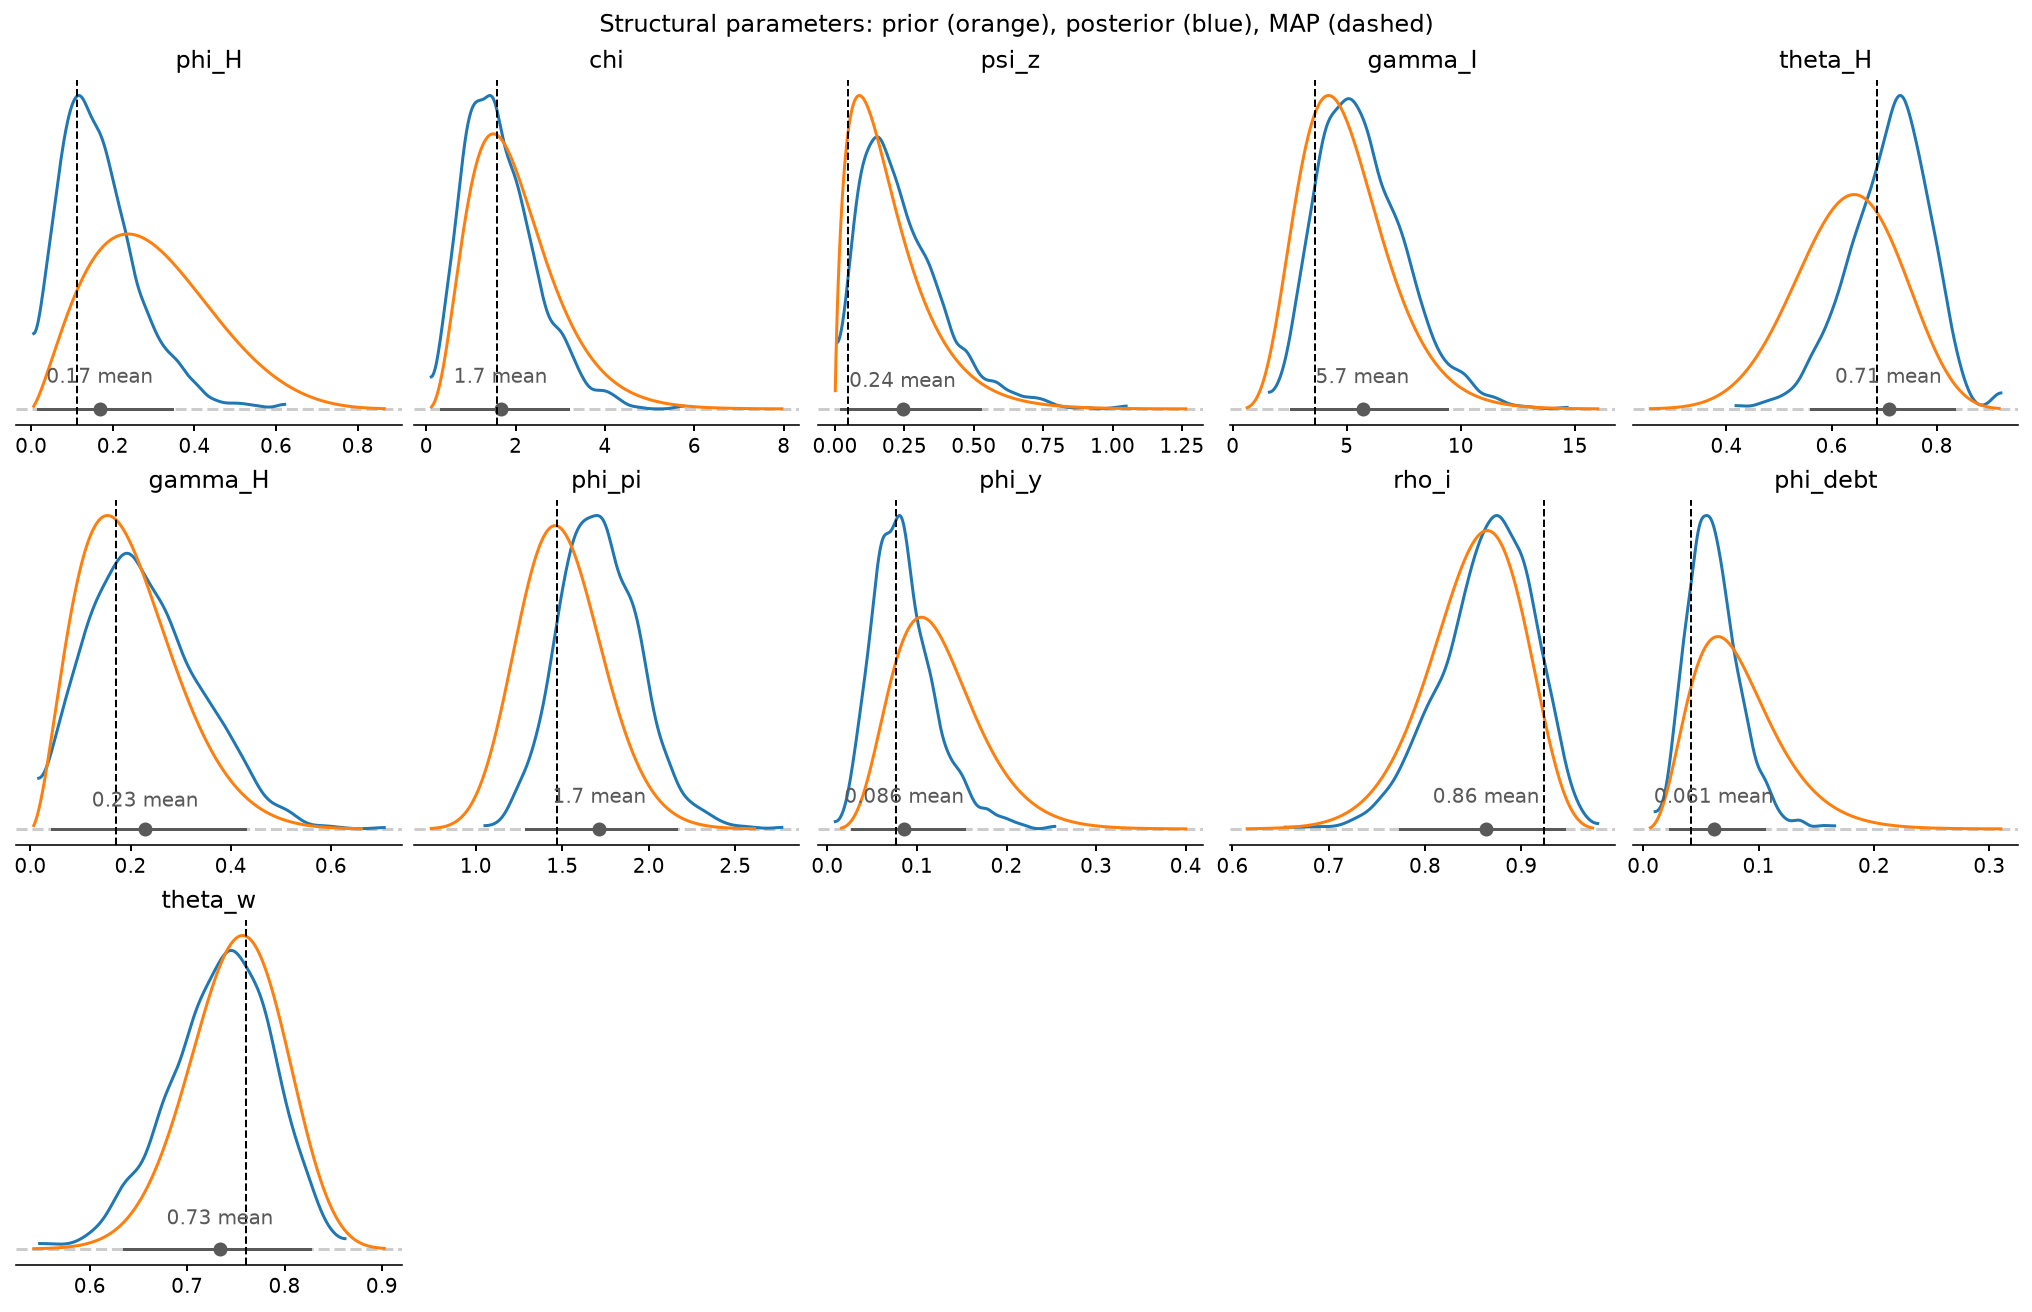

In [34]:
fig = plot_posterior_with_prior(map_init_idata,
                                var_names=ESTIMATED_STRUCTURAL,
                                prior_dict=preliz_priors,
                                true_values=map_estimate)
fig.suptitle("Structural parameters: prior (orange), posterior (blue), MAP (dashed)");

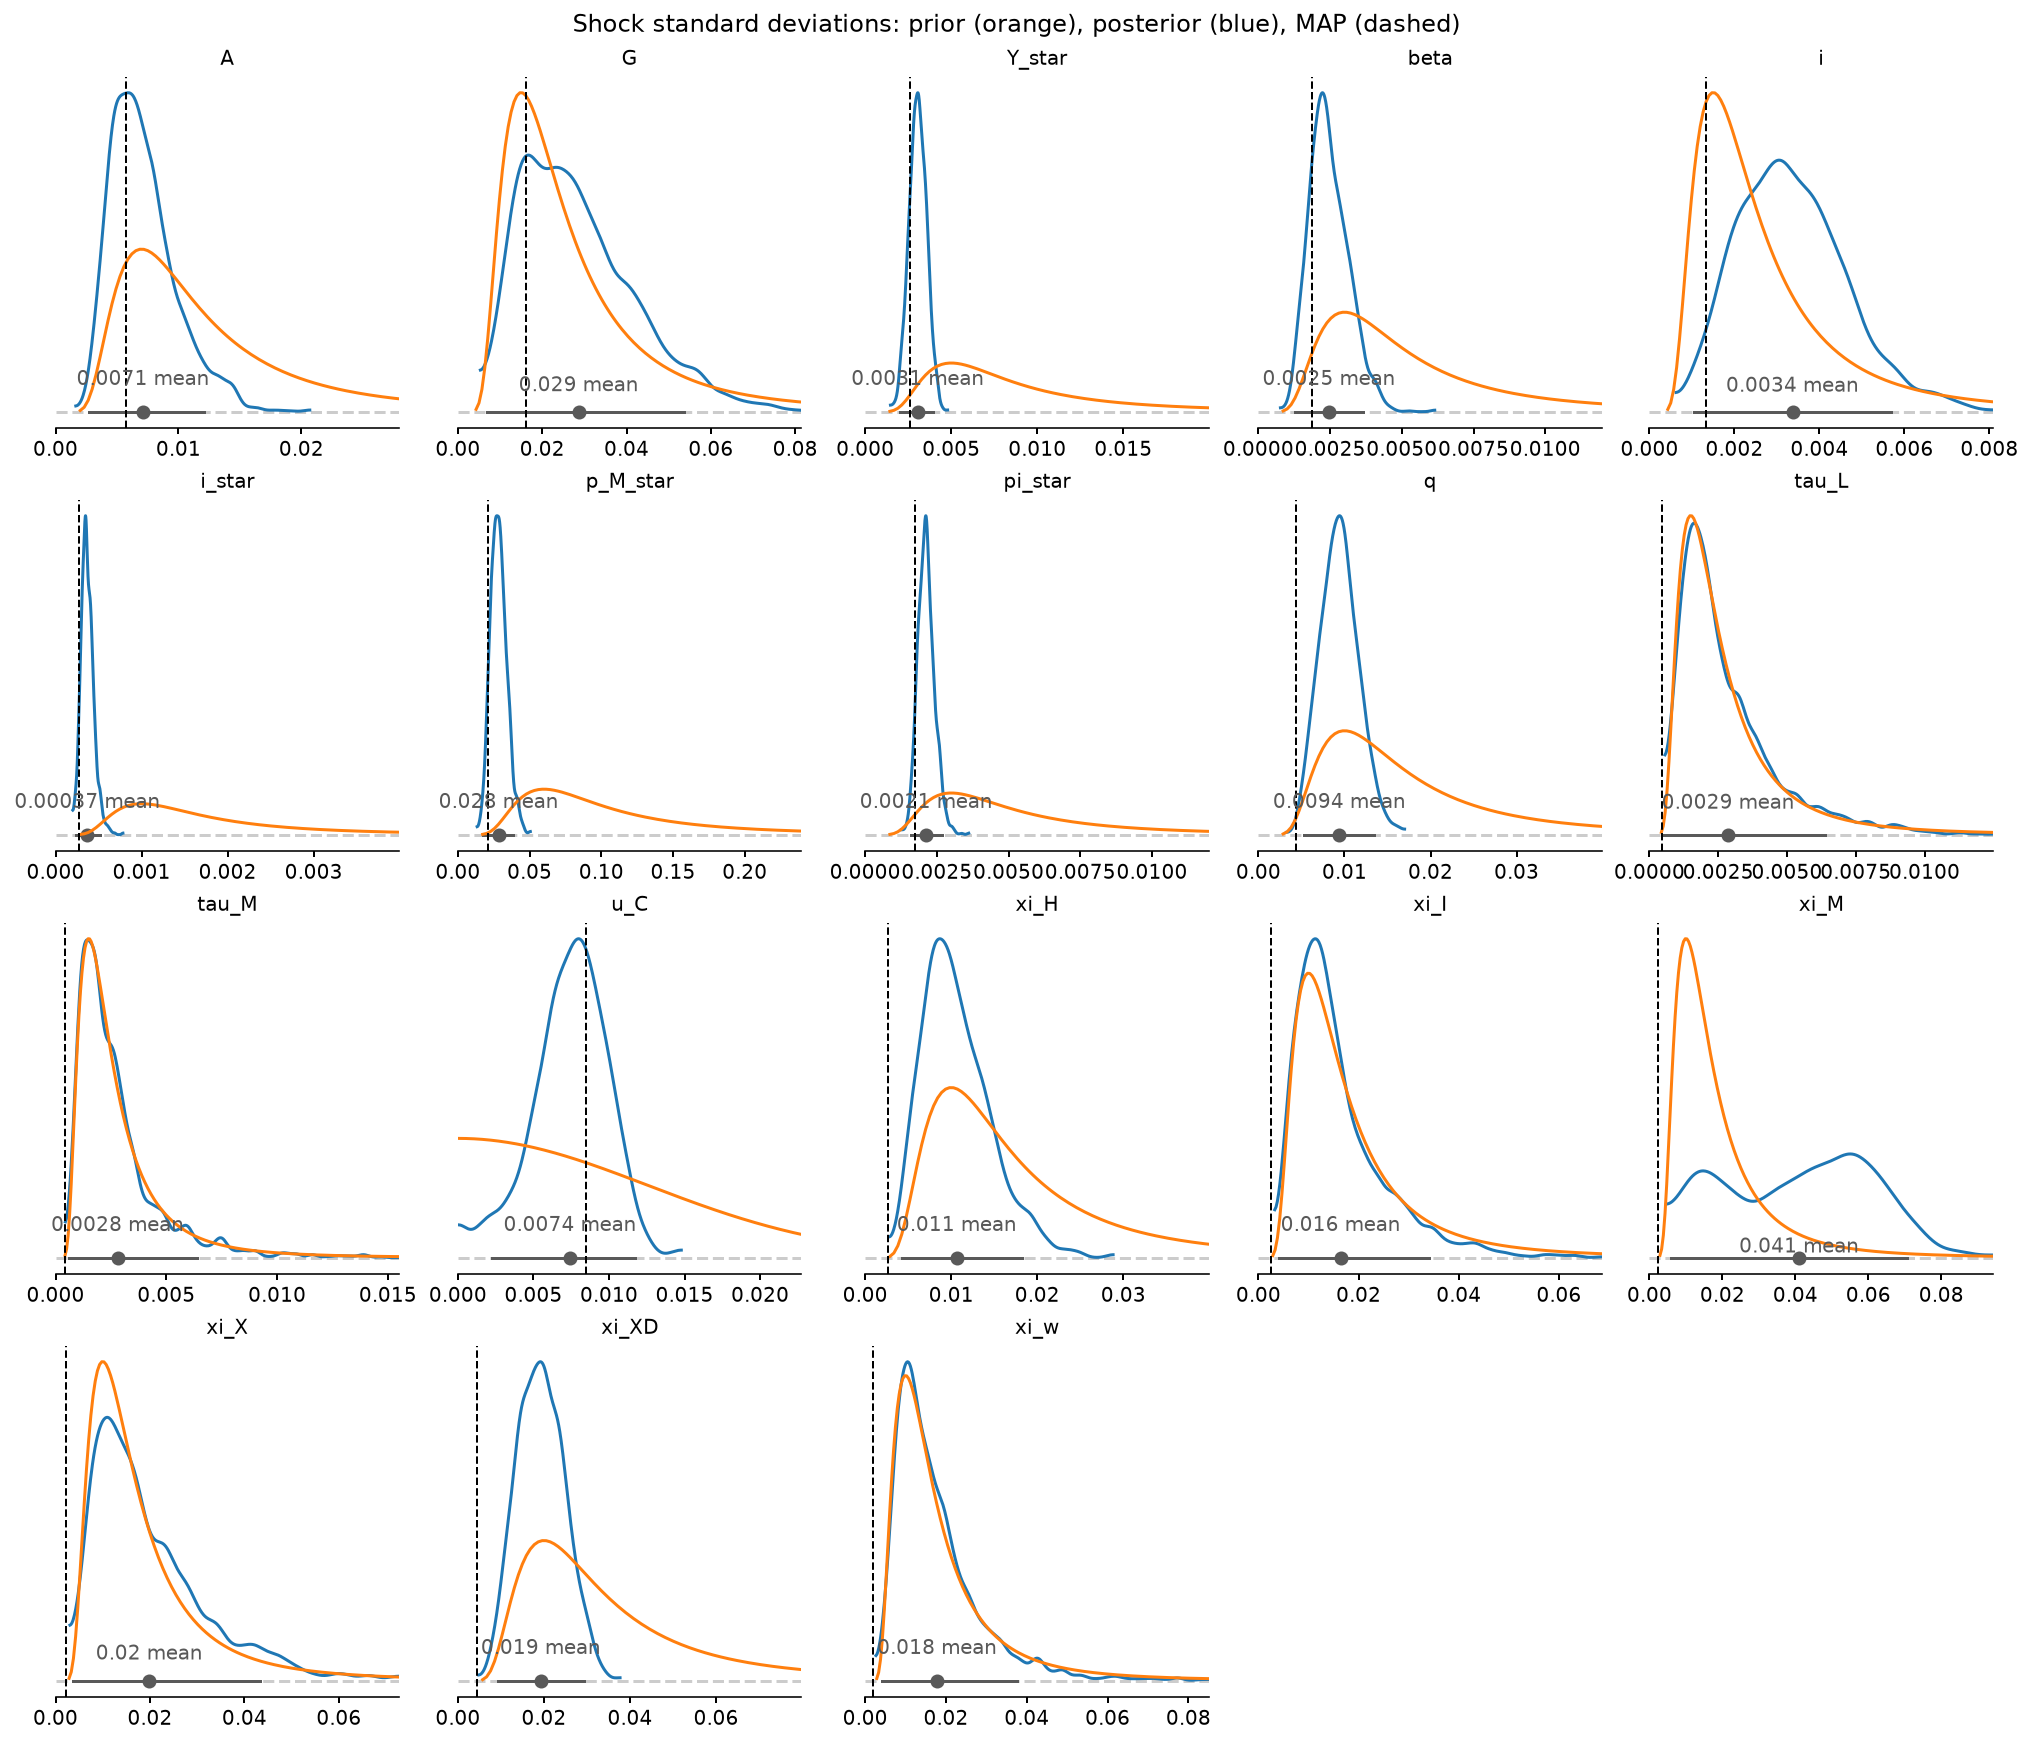

In [35]:
fig = plot_posterior_with_prior(map_init_idata,
                                var_names=SHOCK_SIGMA_NAMES,
                                prior_dict=preliz_priors,
                                true_values=map_estimate,
                                n_cols=5)

posterior_upper = map_init_idata.posterior.to_dataset()[SHOCK_SIGMA_NAMES].quantile(0.995)
for axis in fig.axes:
    name = axis.get_title()
    if name not in SHOCK_SIGMA_NAMES:
        continue
    upper = max(float(posterior_upper[name]), preliz_priors[name].ppf(0.9), float(map_estimate[name]))
    axis.set_xlim(0, 1.1 * upper)
    axis.set_title(name.removeprefix("sigma_epsilon_"), fontsize=10)

fig.suptitle("Shock standard deviations: prior (orange), posterior (blue), MAP (dashed)");

Sampling: [error_share_logit_mean, error_share_offset, error_share_spread]


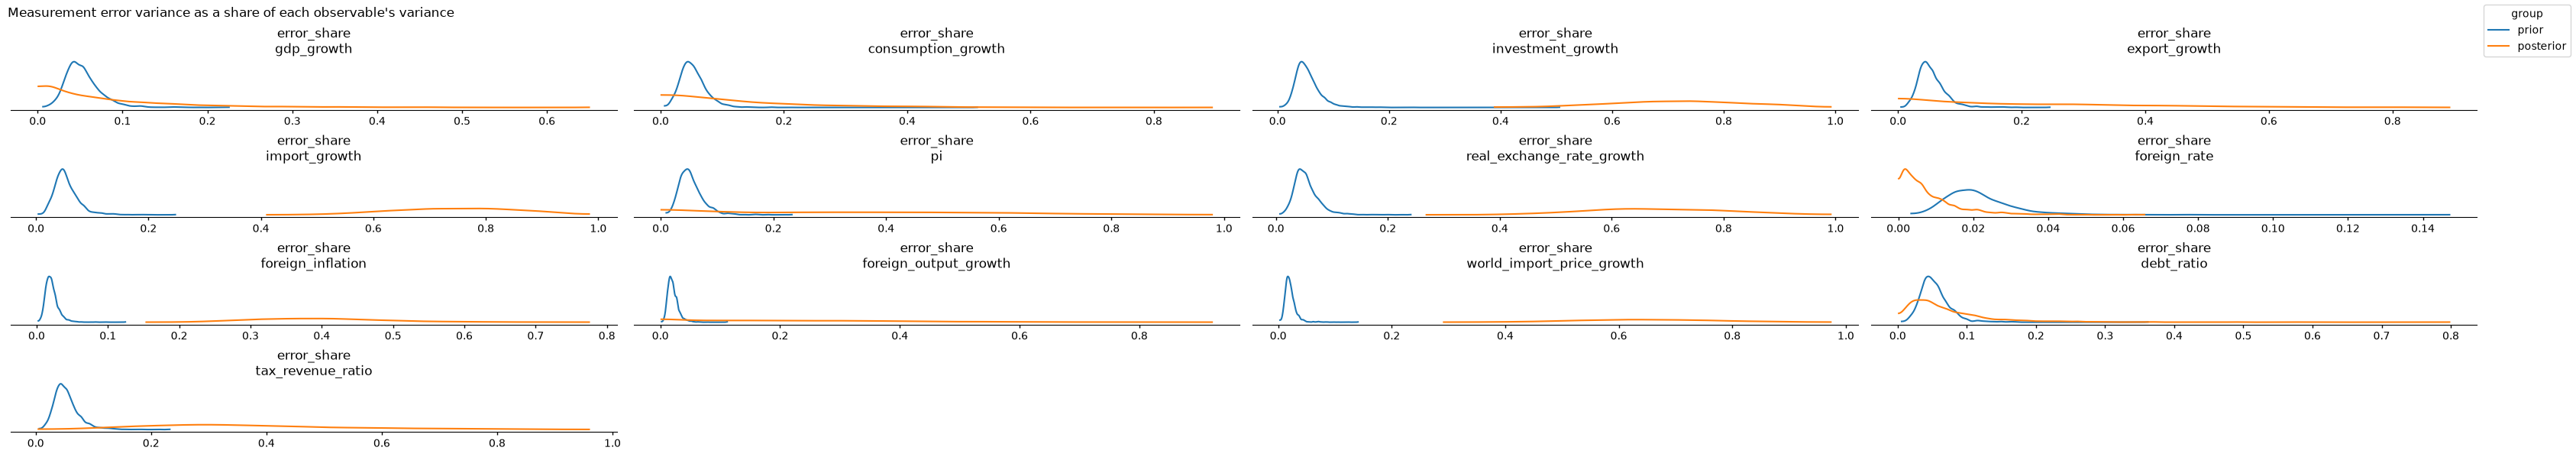

In [36]:
with fit_model:
    error_share_prior = pm.sample_prior_predictive(draws=2000,
                                                   var_names=["error_share"],
                                                   random_seed=20261014)

error_share_trees = xr.DataTree.from_dict({"prior": error_share_prior["prior"].to_dataset(),
                                           "posterior": map_init_idata["posterior"].to_dataset()[["error_share"]]})
plot_collection = az.plot_prior_posterior(error_share_trees, var_names=["error_share"])
plot_collection.viz["figure"].item().suptitle("Measurement error variance as a share of each observable's variance",
                                              x=0.0,
                                              ha="left");

## 8. DSGE checks

Properties of the solved model across all posterior draws: stability of the linear solution, the autocorrelations and correlations it implies for the observables, and the steady-state great ratios.

In [37]:
posterior_draws = map_init_idata.posterior.to_dataset()
observed_data = xr.Dataset({"obs": (("time", "observed_state"), fit_data.to_numpy())},
                           coords={"time": fit_data.index.rename("time"),
                                   "observed_state": fit_data.columns})


def statespace_trace(posterior, parameter_values):
    held_fixed = xr.Dataset({name: xr.full_like(posterior["phi_H"], value)
                             for name, value in parameter_values.items()})
    return xr.DataTree.from_dict({"posterior": xr.merge([posterior, held_fixed]),
                                  "observed_data": observed_data,
                                  "constant_data": xr.Dataset()})


statespace_idata = statespace_trace(posterior=posterior_draws,
                                    parameter_values=fixed_parameters)

In [38]:
def draw_parameters(draws, chain, draw):
    structural = {name: float(draws[name].sel(chain=chain, draw=draw)) for name in ESTIMATED_STRUCTURAL}
    return {**india_parameters, **structural}


def iterate_draws(draws):
    chain_draw_pairs = list(product(draws["chain"].values, draws["draw"].values))
    return tqdm(chain_draw_pairs, desc="posterior draws")


def plot_posterior_density(ax, values, data_value):
    values = np.asarray(values)
    median = np.median(values)
    if np.ptp(values) <= 1e-9 * max(1.0, abs(median)):
        ax.axvline(median,
                   color=PALETTE["primary"],
                   lw=2.0)
        half_width = max(abs(data_value - median), 0.01 * abs(median))
        center = (data_value + median) / 2
        ax.set_xlim(center - 1.5 * half_width, center + 1.5 * half_width)
    else:
        density = az.kde(xr.DataArray(values, dims=["sample"]), dim="sample")
        ax.fill_between(density.sel(plot_axis="x"),
                        density.sel(plot_axis="y"),
                        color=PALETTE["primary"],
                        alpha=0.3,
                        linewidth=0)
        ax.plot(density.sel(plot_axis="x"),
                density.sel(plot_axis="y"),
                color=PALETTE["primary"],
                lw=1.5)
    ax.axvline(data_value,
               color="k",
               ls="--",
               lw=1.5)
    ax.set(yticks=[])
    ax.grid(visible=False, axis="y")

### Solver convergence

Cycle reduction inside the likelihood stops after 50 iterations whether or not it has converged. The deterministic norm is the residual of the matrix quadratic at the returned solution.

In [39]:
solver_trace = posterior_draws[["n_cycle_steps", "deterministic_norm"]].to_dataframe()
solver_trace["unsolved"] = solver_trace["deterministic_norm"] > 1e-6
solver_trace["diverging"] = map_init_idata.sample_stats["diverging"].to_series()

display(solver_trace[["n_cycle_steps", "deterministic_norm"]].describe(percentiles=[0.5, 0.99]).T.style.format("{:.3g}"))
pd.crosstab(index=solver_trace["unsolved"],
            columns=solver_trace["diverging"],
            margins=True)

,count,mean,std,min,50%,99%,max
n_cycle_steps,2e+03,10,0.185,10,10,11,12
deterministic_norm,2e+03,0.019,0.267,1.76e-13,1.98e-11,4.2e-07,4.79


diverging,False,True,All
unsolved,,,
False,1970,12,1982
True,6,12,18
All,1976,24,2000


### Stability

Generalized eigenvalues of the linearized system at each posterior draw. Stable roots lie inside the unit circle.

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

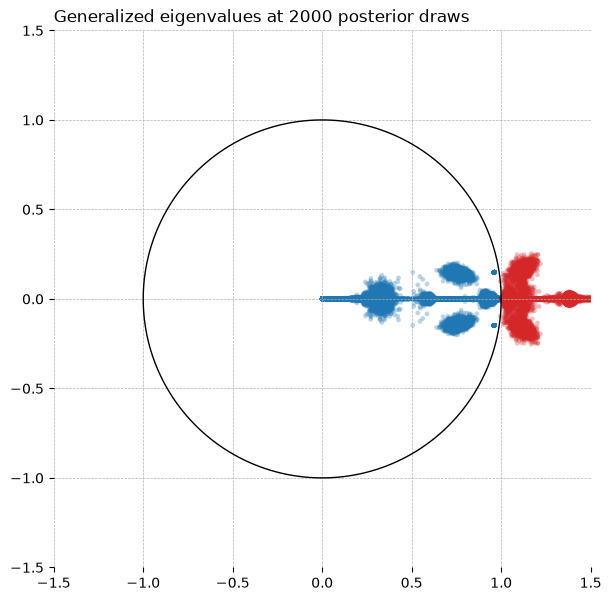

In [40]:
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
for chain, draw in iterate_draws(posterior_draws):
    plot_eigenvalues(model,
                     fig=fig,
                     plot_circle=(chain == 0 and draw == 0),
                     linearize_model_kwargs={"verbose": False},
                     **draw_parameters(posterior_draws, chain=chain, draw=draw))

for collection in ax.collections:
    collection.set(alpha=0.3,
                   sizes=[12],
                   linewidths=0)

n_posterior_draws = posterior_draws.sizes["chain"] * posterior_draws.sizes["draw"]
ax.set(xlim=(-1.5, 1.5),
       ylim=(-1.5, 1.5))
ax.set_title("")
ax.set_title(f"Generalized eigenvalues at {n_posterior_draws} posterior draws", loc="left");

### Moments of the observables

Each posterior draw simulates the observables over 2012Q1 to 2024Q4 from the stationary distribution, with measurement error, and the lockdown quarters are dropped as in the data. The simulated sample moments of the nine quarterly observables are compared against the same moments of the data, so the intervals include the sampling variability of a 44-quarter sample. Draws whose solution did not converge are excluded.

In [41]:
ACF_LAGS = 8

posterior_predictive = statespace.sample_unconditional_posterior(statespace_idata,
                                                                use_data_time_dim=True,
                                                                random_seed=20261014)
solved = ~solver_trace["unsolved"].to_xarray()
simulated = (posterior_predictive["posterior_observed"]
             .where(solved)
             .stack(sample=["chain", "draw"])
             .dropna("sample", how="all")
             .drop_vars(["sample", "chain", "draw"])
             .sel(observed_state=MOMENT_STATES)
             .rename(observed_state="variable"))
missing_in_data = xr.DataArray(fit_data.isna().all(axis=1).to_numpy(),
                               dims=["time"],
                               coords={"time": simulated["time"]})
simulated = simulated.where(~missing_in_data)
data = xr.DataArray(fit_data[MOMENT_STATES].to_numpy(),
                    dims=["time", "variable"],
                    coords={"time": simulated["time"], "variable": MOMENT_STATES})


def lagged_correlation(values, lag):
    """Correlation of each variable at t with each variable_aux at t - lag, over quarters where both are observed."""
    return xr.corr(values,
                   values.shift(time=lag).rename(variable="variable_aux"),
                   dim="time")


def sample_moments(values):
    autocorrelation = xr.concat([lagged_correlation(values, lag) for lag in range(ACF_LAGS)], dim="lag")
    return xr.Dataset({"std": values.std("time", ddof=1),
                       "acf": autocorrelation.transpose(..., "lag", "variable", "variable_aux")},
                      coords={"lag": np.arange(ACF_LAGS)})


predictive_moments = sample_moments(simulated)
data_moments = sample_moments(data)
pd.Series({"posterior draws": solver_trace.shape[0],
           "simulated (solved draws)": predictive_moments.sizes["sample"],
           "quarters per simulation": simulated.sizes["time"],
           "observed quarters per simulation": int(simulated.isel(sample=0, variable=0).notnull().sum())},
          name="count").to_frame()

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/pytensor/link/jax/linker.py:50: UserWarning: The RandomType SharedVariables [RNG(Generator(PCG64))] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [posterior_combined]


Output()

,count
posterior draws,2000
simulated (solved draws),1982
quarters per simulation,52
observed quarters per simulation,44


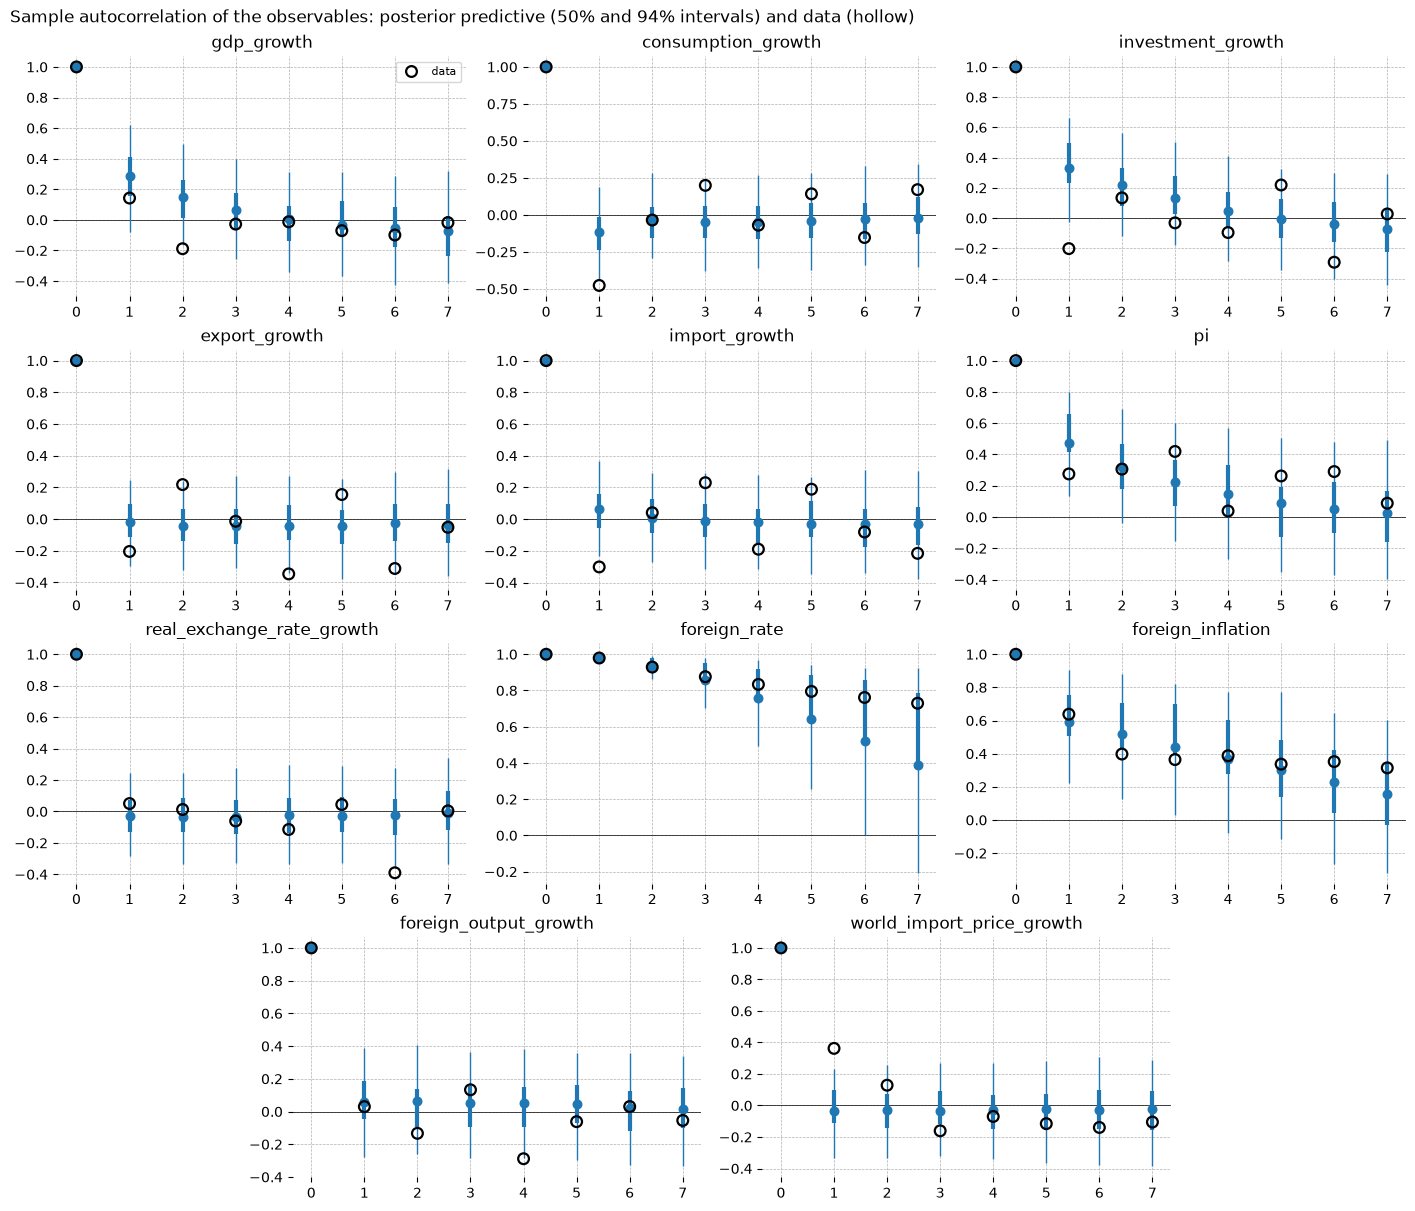

In [42]:
data_autocorrelation = data_moments["acf"].sel(variable_aux=data_moments["variable"]).drop_vars("variable_aux")

fig = plot_acf(predictive_moments["acf"].rename(sample="draw").expand_dims(chain=[0]),
               reference=data_autocorrelation,
               figsize=(14, 12),
               n_cols=3)
fig.suptitle("Sample autocorrelation of the observables: posterior predictive (50% and 94% intervals) and data (hollow)",
             x=0.0,
             ha="left");

The diagonal shows posterior predictive densities of each observable's sample standard deviation, and the dashed line marks the data. Below the diagonal, each panel shows the posterior predictive median (dot) with 50% (thick) and 94% (thin) intervals for one sample correlation, and the hollow marker is the data.

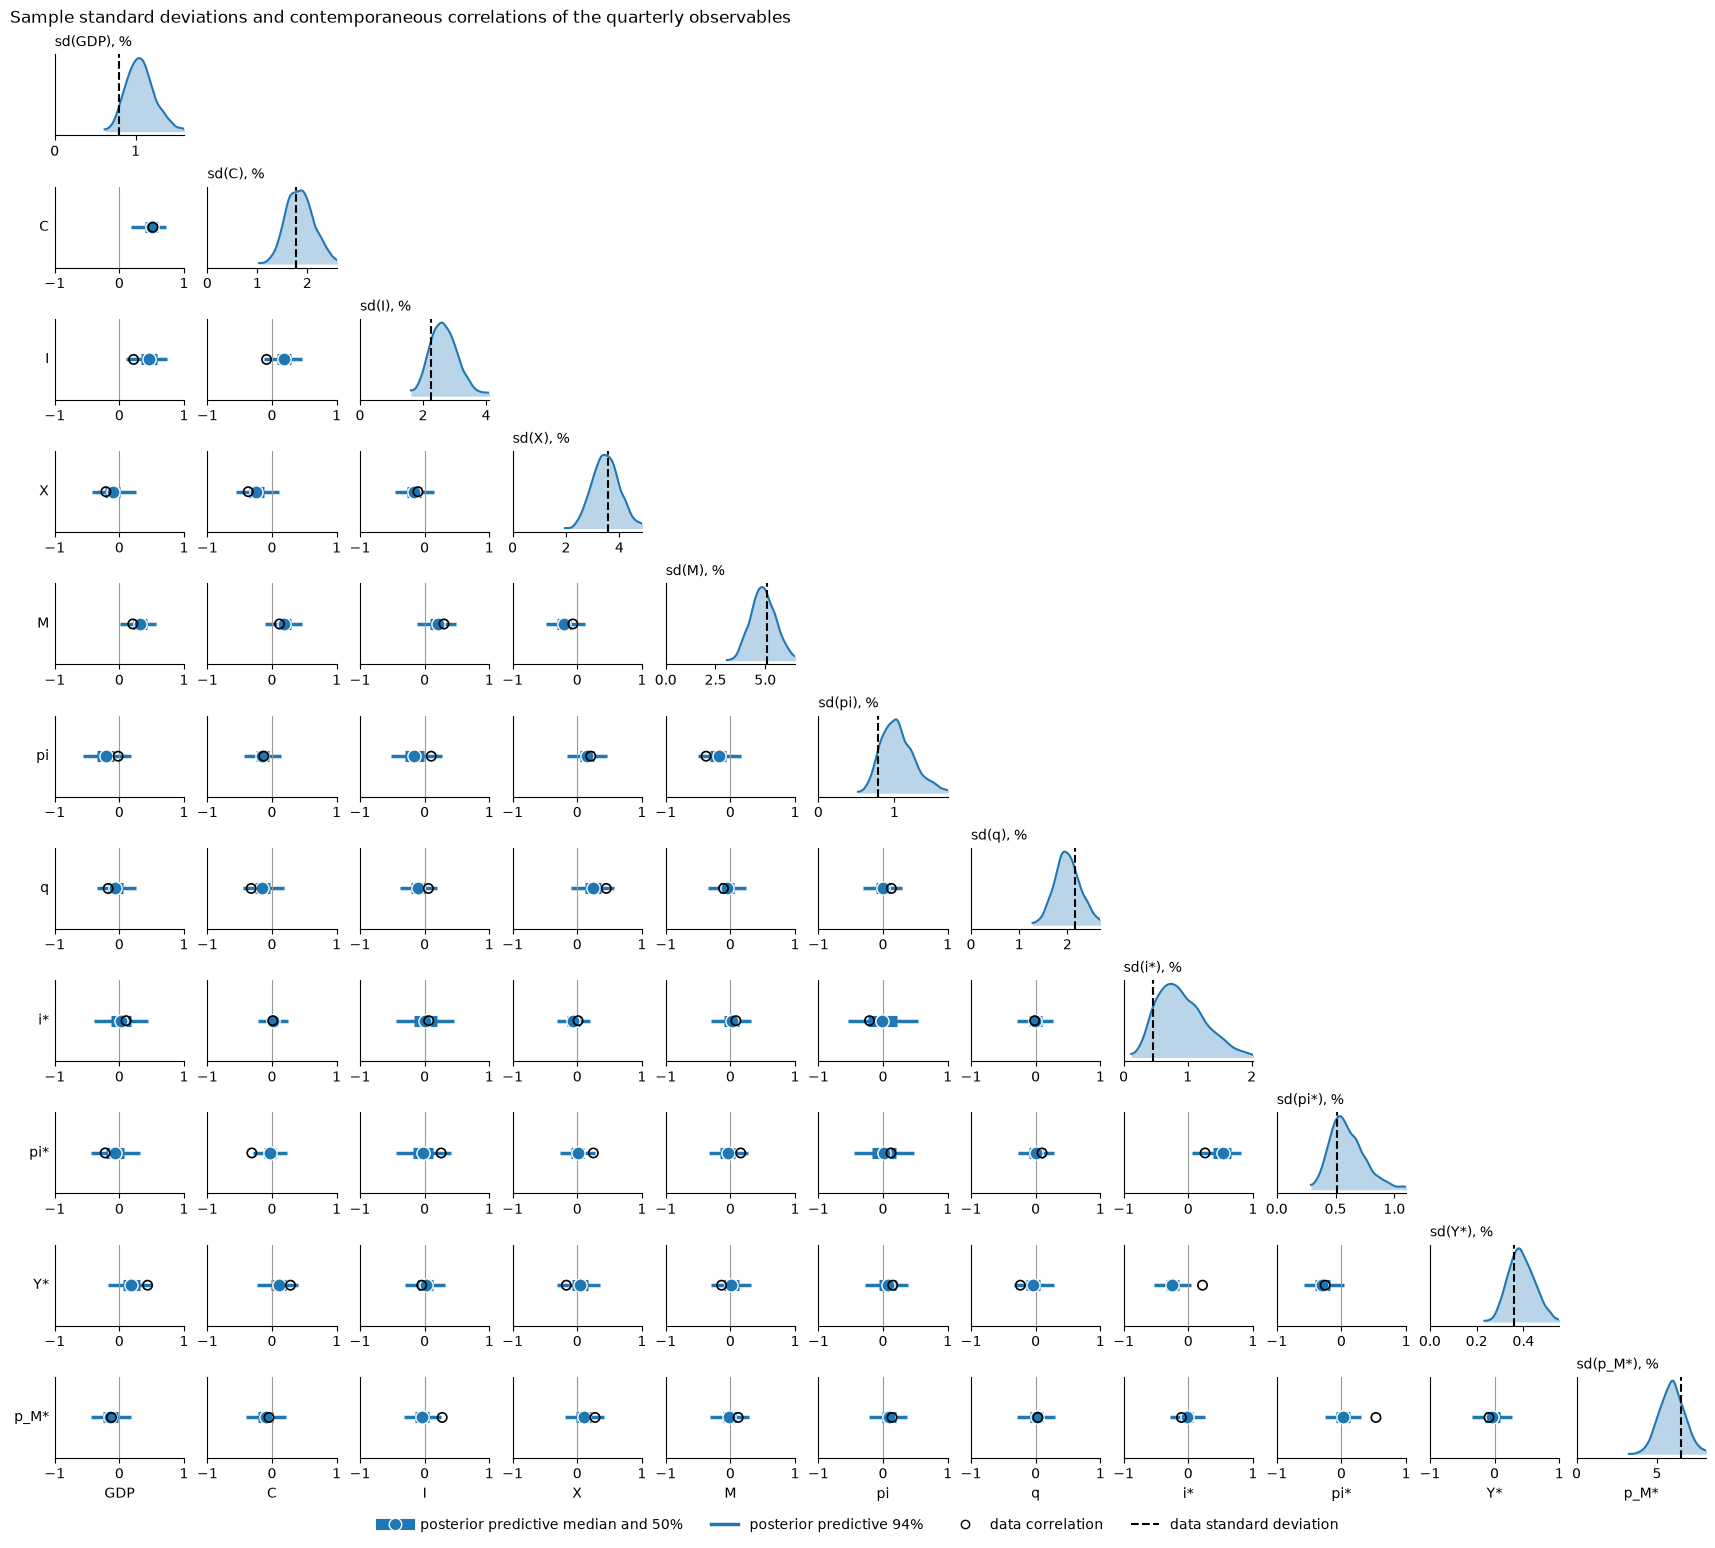

In [43]:
OBSERVABLE_SHORT_NAMES = {**{name: variable for name, (_, variable) in GROWTH_OBSERVABLES.items()},
                          "pi": "pi",
                          "real_exchange_rate_growth": "q",
                          "foreign_rate": "i*",
                          "foreign_inflation": "pi*",
                          "foreign_output_growth": "Y*",
                          "world_import_price_growth": "p_M*"}
OUTER_INTERVAL_WIDTH = 2.5
INNER_INTERVAL_WIDTH = 8.0

predictive_std_percent = 100 * predictive_moments["std"]
data_std_percent = 100 * data_moments["std"].to_series()
correlation_quantiles = predictive_moments["acf"].sel(lag=0).quantile([0.03, 0.25, 0.5, 0.75, 0.97], dim="sample")
data_correlation = data_moments["acf"].sel(lag=0).to_pandas()


def plot_correlation_interval(ax, row_name, column_name):
    interval = correlation_quantiles.sel(variable=row_name, variable_aux=column_name)
    ax.hlines(y=0,
              xmin=float(interval.sel(quantile=0.03)),
              xmax=float(interval.sel(quantile=0.97)),
              color=PALETTE["primary"],
              lw=OUTER_INTERVAL_WIDTH)
    ax.hlines(y=0,
              xmin=float(interval.sel(quantile=0.25)),
              xmax=float(interval.sel(quantile=0.75)),
              color=PALETTE["primary"],
              lw=INNER_INTERVAL_WIDTH)
    ax.scatter(x=float(interval.sel(quantile=0.5)),
               y=0,
               color=PALETTE["primary"],
               edgecolors="white",
               s=90,
               linewidths=1.0,
               zorder=3)
    ax.scatter(x=data_correlation.loc[row_name, column_name],
               y=0,
               facecolors="none",
               edgecolors="k",
               s=45,
               linewidths=1.2,
               zorder=4)
    ax.axvline(0.0, color="0.6", lw=0.8)
    ax.set(xlim=(-1, 1),
           ylim=(-1, 1),
           yticks=[])
    ax.grid(visible=False, axis="y")


def plot_std_density(ax, name):
    std = predictive_std_percent.sel(variable=name)
    plot_posterior_density(ax=ax,
                           values=std,
                           data_value=data_std_percent[name])
    upper = max(float(std.quantile(0.99)), 1.2 * data_std_percent[name])
    ax.set_xlim(0, upper)
    ax.set_title(f"sd({OBSERVABLE_SHORT_NAMES[name]}), %", loc="left", fontsize=10)


n_observables = len(MOMENT_STATES)
fig, axes = plt.subplots(nrows=n_observables,
                         ncols=n_observables,
                         figsize=(17, 15),
                         layout="constrained")
for row, row_name in enumerate(MOMENT_STATES):
    for column, column_name in enumerate(MOMENT_STATES):
        ax = axes[row, column]
        if column > row:
            ax.set_axis_off()
            continue
        if column == row:
            plot_std_density(ax=ax, name=row_name)
        else:
            plot_correlation_interval(ax=ax,
                                      row_name=row_name,
                                      column_name=column_name)
        if column == 0 and row > 0:
            ax.set_ylabel(OBSERVABLE_SHORT_NAMES[row_name], rotation=0, ha="right", va="center")
        if row == n_observables - 1:
            ax.set_xlabel(OBSERVABLE_SHORT_NAMES[column_name])

legend_handles = [plt.Line2D([],
                             [],
                             color=PALETTE["primary"],
                             marker="o",
                             markersize=9,
                             markeredgecolor="white",
                             lw=INNER_INTERVAL_WIDTH,
                             label="posterior predictive median and 50%"),
                  plt.Line2D([], [], color=PALETTE["primary"], lw=OUTER_INTERVAL_WIDTH, label="posterior predictive 94%"),
                  plt.Line2D([], [], color="k", marker="o", markerfacecolor="none", lw=0.0, label="data correlation"),
                  plt.Line2D([], [], color="k", ls="--", lw=1.5, label="data standard deviation")]
fig.legend(handles=legend_handles,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(legend_handles),
           frameon=False)
fig.suptitle("Sample standard deviations and contemporaneous correlations of the quarterly observables",
             x=0.0,
             ha="left");

### Great ratios across the posterior

Posterior densities of the steady-state expenditure and income shares, with the 2012 to 2024 averages from section 1 dashed. Only the estimated parameters move across draws. A vertical line in place of a density marks a ratio those parameters do not affect.

In [44]:
posterior_ratios = pd.DataFrame([model_ratios(**draw_parameters(posterior_draws, chain=chain, draw=draw))
                                 for chain, draw in iterate_draws(posterior_draws)])

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

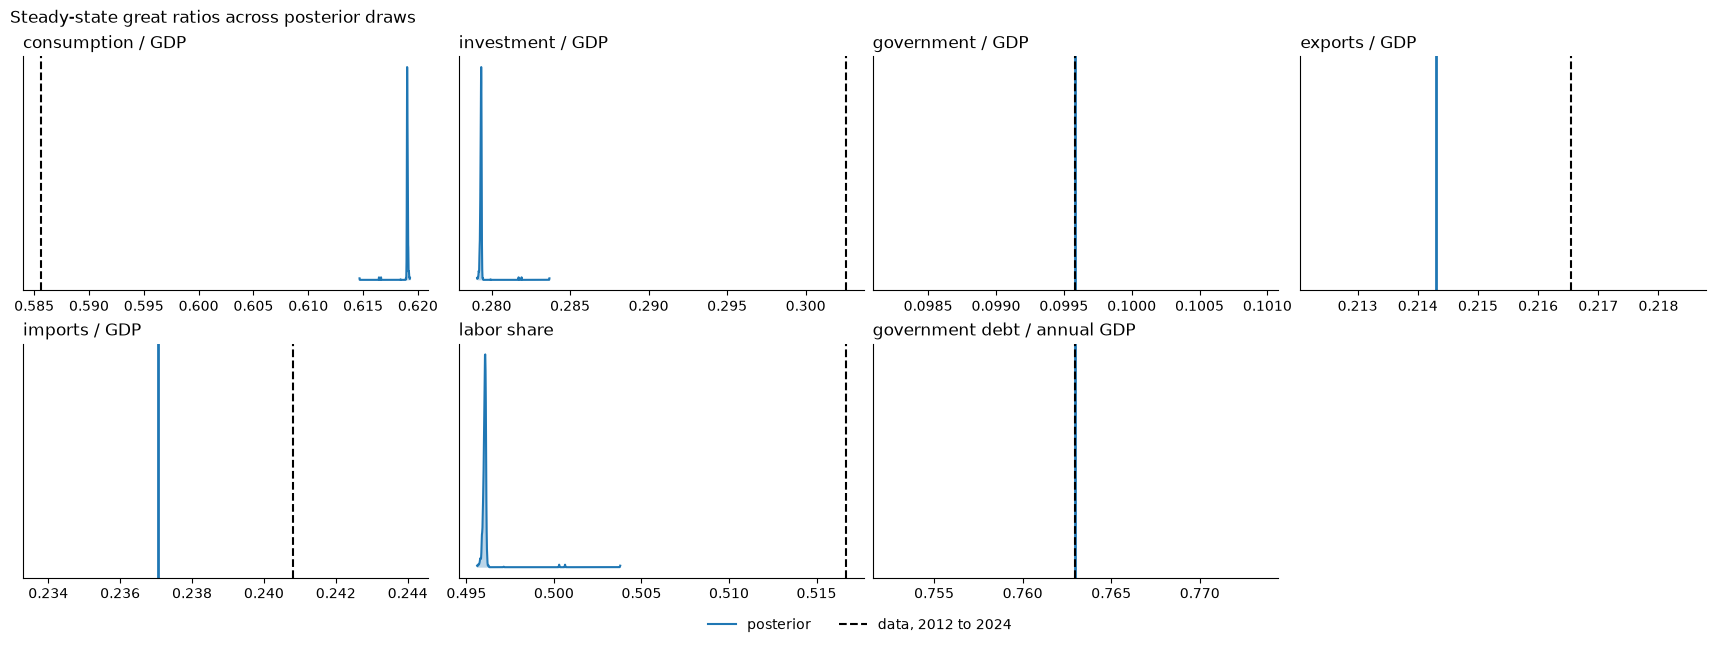

In [45]:
fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(17, 6),
                         layout="constrained")
for ax, ratio in zip(axes.flat, posterior_ratios.columns):
    plot_posterior_density(ax=ax,
                           values=posterior_ratios[ratio],
                           data_value=comparable_targets[ratio])
    ax.set_title(ratio, loc="left")
axes.flat[-1].set_axis_off()

legend_handles = [plt.Line2D([], [], color=PALETTE["primary"], lw=1.5, label="posterior"),
                  plt.Line2D([], [], color="k", ls="--", lw=1.5, label="data, 2012 to 2024")]
fig.legend(handles=legend_handles,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(legend_handles),
           frameon=False)
fig.suptitle("Steady-state great ratios across posterior draws", x=0.0, ha="left");

### Smoothed states and shocks

The Kalman smoother's estimates of the observables, the unobserved states and the structural shocks over the sample, given all of the data, with bands across posterior draws. A smoothed observable is the model's signal $d + Z x_t$ without measurement error, so its gap to the data is the measurement error. The shocks are backed out of the transition equation from each draw's smoothed state means and divided by their estimated standard deviations. A well-specified model gives shock series centered on zero, mostly inside two standard deviations and without persistent runs.

In [46]:
filter_idata = xr.DataTree.from_dict({"posterior": statespace_idata["posterior"].to_dataset(),
                                      "observed_data": observed_data,
                                      "constant_data": xr.Dataset({"data": observed_data["obs"]})})
conditional_posterior = statespace.sample_conditional_posterior(filter_idata, random_seed=20261014)
smoothed_states = statespace.sample_filter_outputs(filter_idata,
                                                   filter_output_names="smoothed_states",
                                                   random_seed=20261014)["posterior_predictive"]["smoothed_states"]
statespace_matrices = statespace.sample_statespace_matrices(filter_idata,
                                                            matrix_names=["c", "d", "T", "Z", "R"],
                                                            random_seed=20261014)["posterior_predictive"]
transition = statespace_matrices["T"]

lagged_states = smoothed_states.shift(time=1).rename(state="state_aux")
transition_residual = smoothed_states - statespace_matrices["c"] - xr.dot(transition, lagged_states, dim="state_aux")
selection_inverse = xr.apply_ufunc(np.linalg.pinv,
                                   statespace_matrices["R"],
                                   input_core_dims=[["state", "shock"]],
                                   output_core_dims=[["shock", "state"]])
shock_sd = xr.concat([posterior_draws[f"sigma_{shock}"] for shock in estimated_shocks],
                     dim=pd.Index(estimated_shocks, name="shock"))
standardized_shocks = (xr.dot(selection_inverse, transition_residual, dim="state") / shock_sd).isel(time=slice(1, None))

/Users/jessegrabowski/mambaforge/envs/climate-risk/lib/python3.12/site-packages/pytensor/link/jax/linker.py:50: UserWarning: The RandomType SharedVariables [RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64)), RNG(Generator(PCG64))] will not be used in the compiled JAX graph. Instead a copy will be used.
  warnings.warn(
Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

Sampling: []


Output()

Sampling: []


Output()

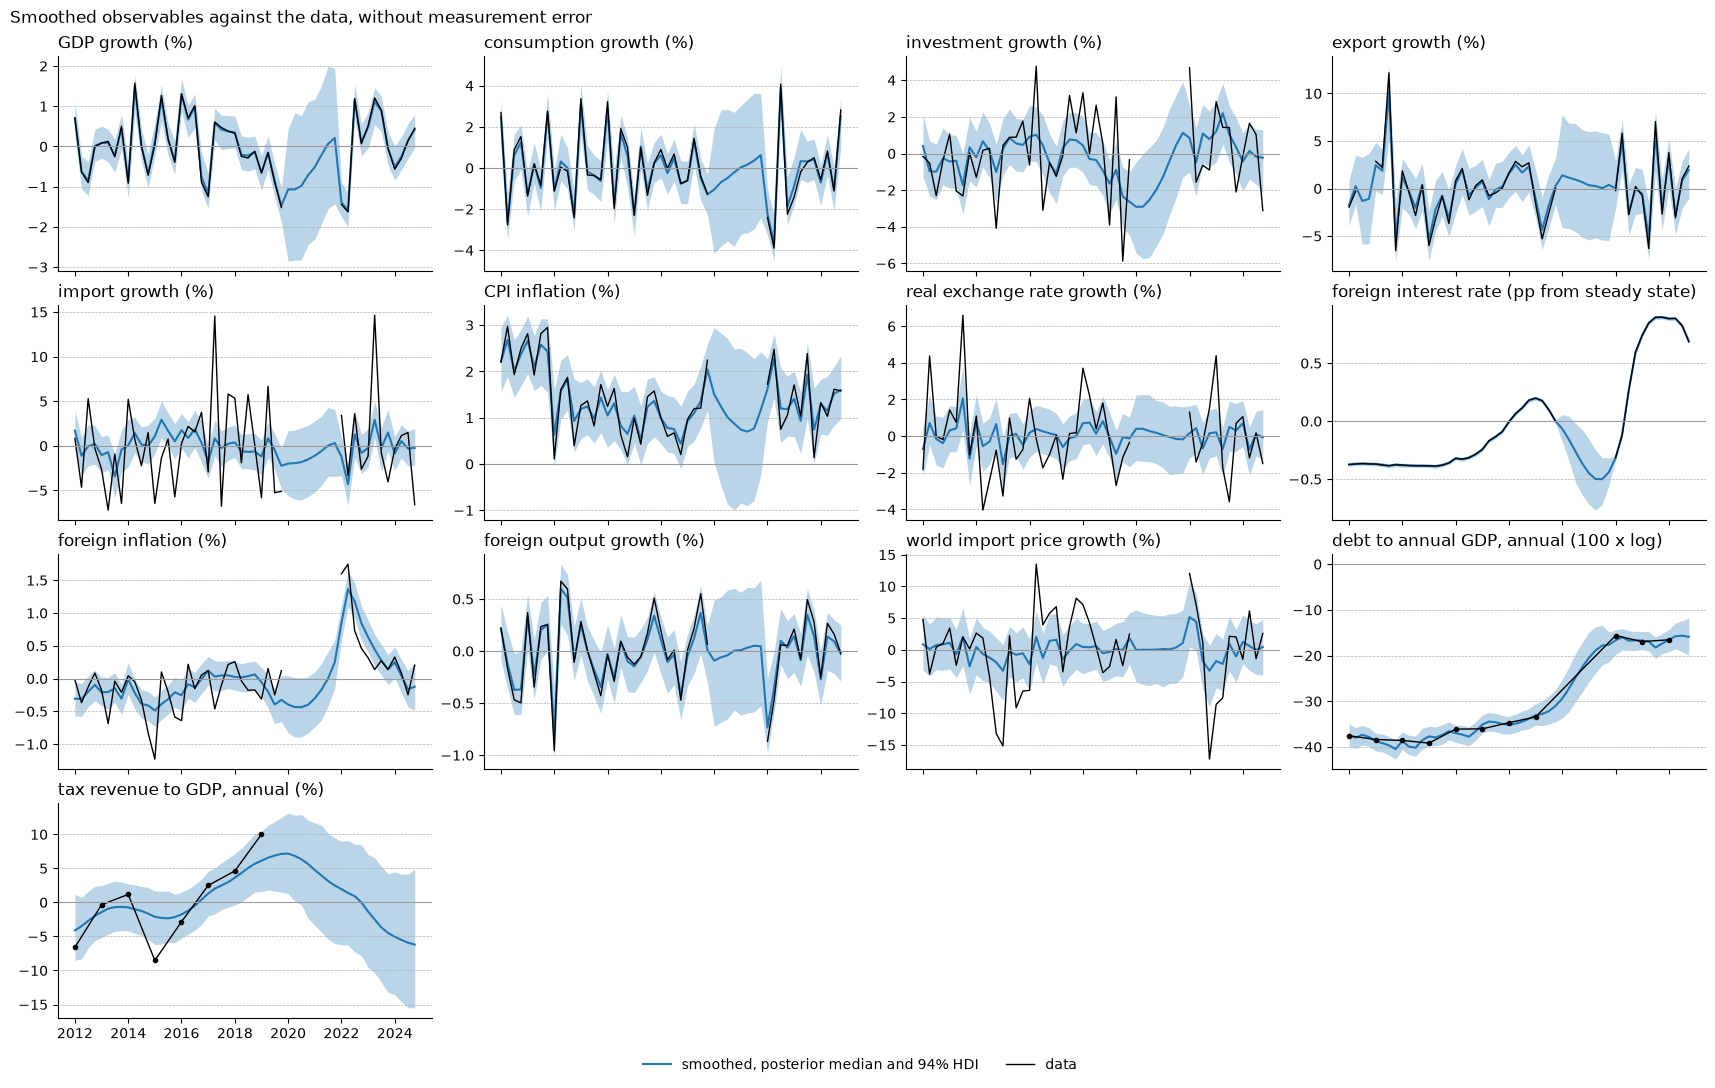

In [47]:
OBSERVABLE_TITLES = {"gdp_growth": "GDP growth (%)",
                     "consumption_growth": "consumption growth (%)",
                     "investment_growth": "investment growth (%)",
                     "export_growth": "export growth (%)",
                     "import_growth": "import growth (%)",
                     "pi": "CPI inflation (%)",
                     "real_exchange_rate_growth": "real exchange rate growth (%)",
                     "foreign_rate": "foreign interest rate (pp from steady state)",
                     "foreign_inflation": "foreign inflation (%)",
                     "foreign_output_growth": "foreign output growth (%)",
                     "world_import_price_growth": "world import price growth (%)",
                     "debt_ratio": "debt to annual GDP, annual (100 x log)",
                     "tax_revenue_ratio": "tax revenue to GDP, annual (%)"}
SMOOTHED_LABEL = "smoothed, posterior median and 94% HDI"


def median_and_hdi(path):
    draws = path.stack(sample=("chain", "draw")).drop_vars(["sample", "chain", "draw"]).dropna("sample", how="any")
    return draws.median("sample"), az.hdi(draws, prob=0.94, dim=["sample"])


def plot_smoothed_panels(paths, titles, data=None, reference_levels=(0.0,), n_cols=4):
    """One panel per entry of `titles`, each a smoothed path over time with the data drawn on top if given."""
    n_rows = int(np.ceil(len(titles) / n_cols))
    fig, axes = plt.subplots(nrows=n_rows,
                             ncols=n_cols,
                             figsize=(17, 2.6 * n_rows),
                             sharex=True,
                             layout="constrained")
    dates = paths["time"].to_numpy()
    for ax, (name, title) in zip(axes.flat, titles.items()):
        median, interval = median_and_hdi(paths.sel(variable=name))
        ax.fill_between(dates,
                        interval.sel(ci_bound="lower"),
                        interval.sel(ci_bound="upper"),
                        color=PALETTE["primary"],
                        alpha=0.3,
                        linewidth=0)
        ax.plot(dates,
                median,
                color=PALETTE["primary"],
                lw=1.5,
                label=SMOOTHED_LABEL)
        if data is not None:
            series = data[name].dropna() if name in ANNUAL_OBSERVABLES else data[name]
            ax.plot(series.index,
                    series,
                    color="k",
                    lw=1.0,
                    marker="o" if name in ANNUAL_OBSERVABLES else None,
                    markersize=3,
                    label="data")
        for level in reference_levels:
            ax.axhline(level, color="0.6", lw=0.8, ls="-" if level == 0 else ":")
        ax.set_title(title, loc="left")
    for ax in axes.flat[len(titles):]:
        ax.set_axis_off()

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles=handles,
               labels=labels,
               loc="upper center",
               bbox_to_anchor=(0.5, 0.0),
               ncol=len(labels),
               frameon=False)
    return fig, axes


smoothed_signal = statespace_matrices["d"] + xr.dot(statespace_matrices["Z"],
                                                    conditional_posterior["smoothed_posterior"],
                                                    dim="state")
smoothed_observed = 100 * smoothed_signal.sel(observed_state=list(OBSERVABLE_TITLES)).rename(observed_state="variable")
fig, axes = plot_smoothed_panels(paths=smoothed_observed,
                                 titles=OBSERVABLE_TITLES,
                                 data=100 * fit_data)
fig.suptitle("Smoothed observables against the data, without measurement error", x=0.0, ha="left");

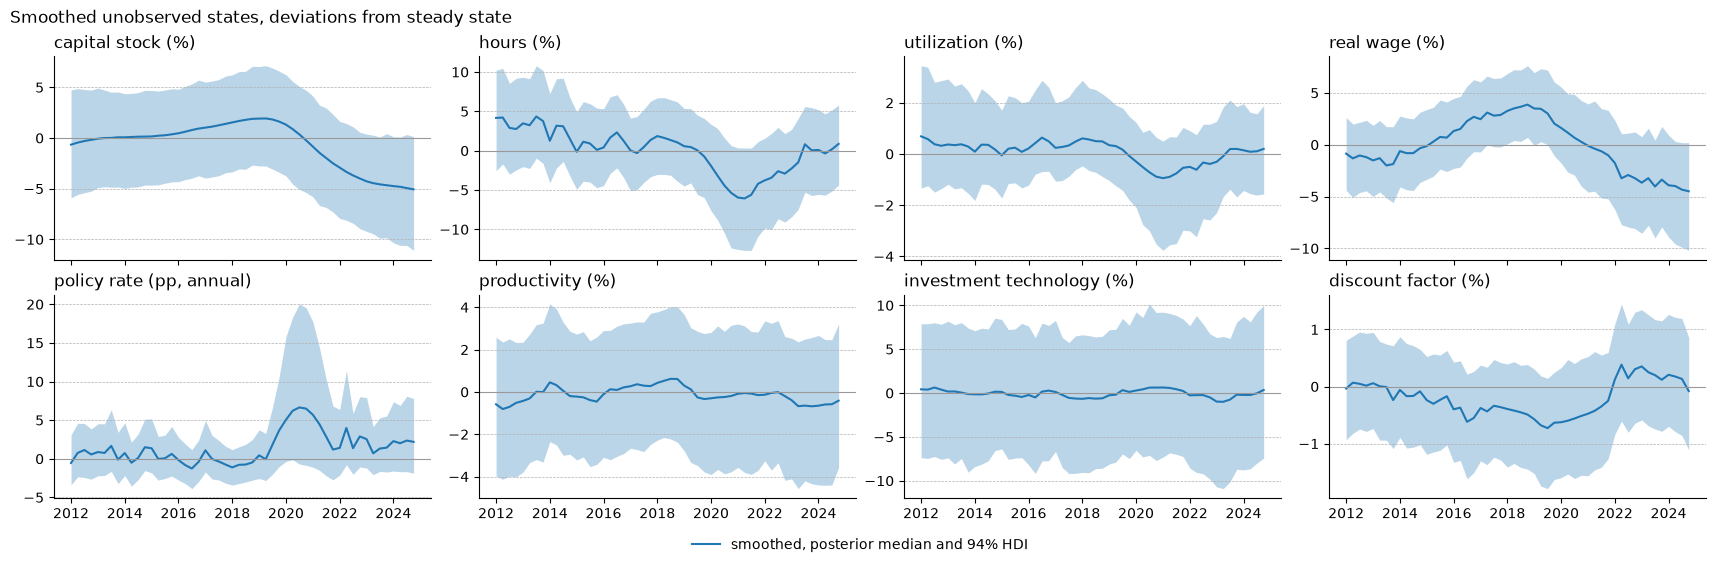

In [48]:
HIDDEN_STATE_TITLES = {name: VARIABLE_LABELS[name] for name in ["K", "L", "z", "w", "i"]} | {
    "A": "productivity (%)",
    "xi_I": "investment technology (%)",
    "beta": "discount factor (%)"}

smoothed_latent = conditional_posterior["smoothed_posterior"].rename(state="variable")
smoothed_hidden = xr.concat([to_display_units(irf=smoothed_latent,
                                              variable=name,
                                              policy_rate_ss=india_steady_state["i_ss"])
                             for name in HIDDEN_STATE_TITLES],
                            dim=pd.Index(list(HIDDEN_STATE_TITLES), name="variable"))
fig, axes = plot_smoothed_panels(paths=smoothed_hidden,
                                 titles=HIDDEN_STATE_TITLES)
fig.suptitle("Smoothed unobserved states, deviations from steady state", x=0.0, ha="left");

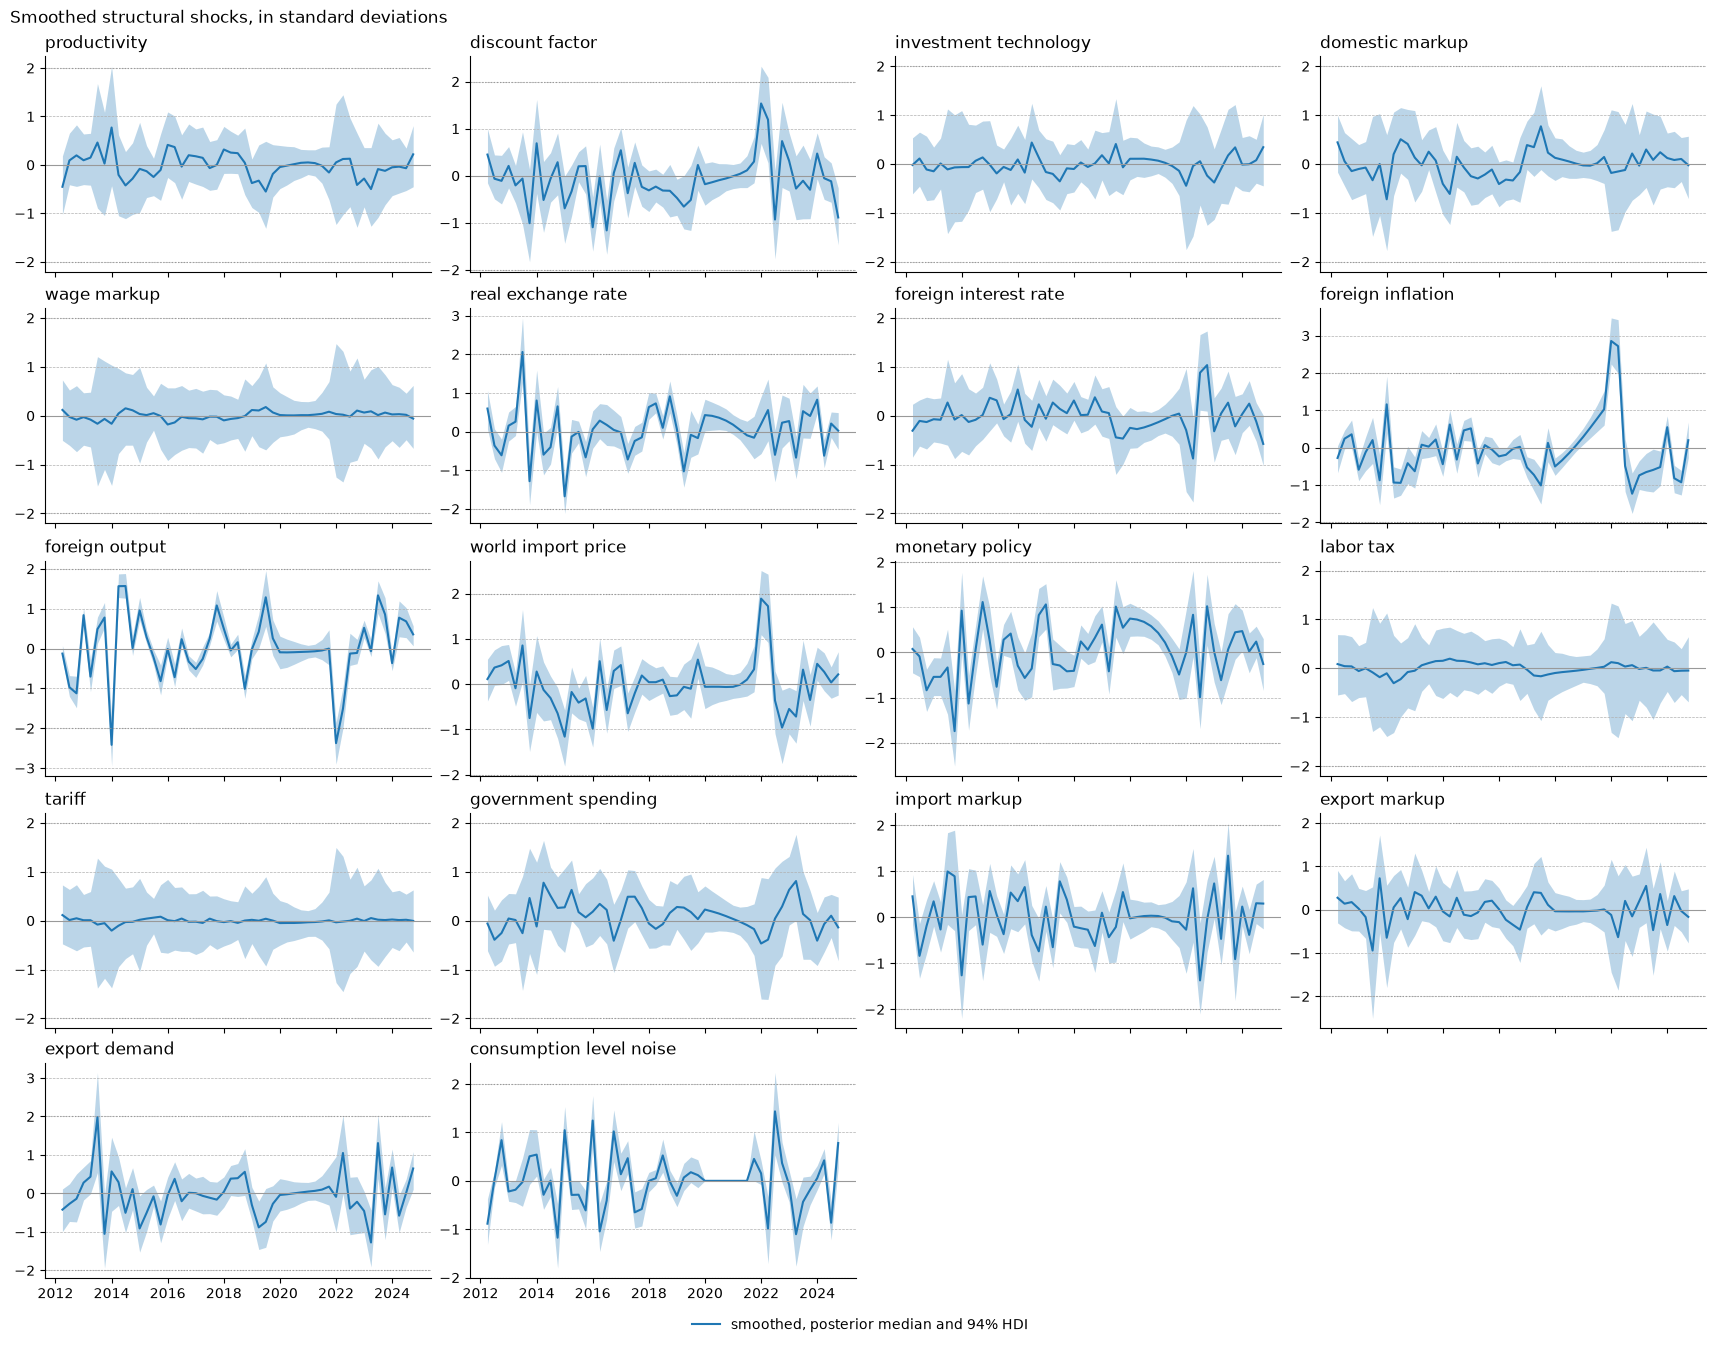

In [49]:
SHOCK_TITLES = {"epsilon_A": "productivity",
                "epsilon_beta": "discount factor",
                "epsilon_xi_I": "investment technology",
                "epsilon_xi_H": "domestic markup",
                "epsilon_xi_w": "wage markup",
                "epsilon_q": "real exchange rate",
                "epsilon_i_star": "foreign interest rate",
                "epsilon_pi_star": "foreign inflation",
                "epsilon_Y_star": "foreign output",
                "epsilon_p_M_star": "world import price",
                "epsilon_i": "monetary policy",
                "epsilon_tau_L": "labor tax",
                "epsilon_tau_M": "tariff",
                "epsilon_G": "government spending",
                "epsilon_xi_M": "import markup",
                "epsilon_xi_X": "export markup",
                "epsilon_xi_XD": "export demand",
                "epsilon_u_C": "consumption level noise"}

fig, axes = plot_smoothed_panels(paths=standardized_shocks.rename(shock="variable"),
                                 titles=SHOCK_TITLES,
                                 reference_levels=(-2.0, 0.0, 2.0))
fig.suptitle("Smoothed structural shocks, in standard deviations", x=0.0, ha="left");

## 9. Economics of capital destruction under the posterior

The estimated model, with capital destruction added back: how the impact on GDP varies across the posterior, the impulse responses, a counterfactual disaster in 2015Q1, and its welfare cost at first order and in the nonlinear model.

The simulation model is the estimation model plus the capital destruction block. Its shock covariance is the estimated one, with the disaster added as an uncorrelated shock whose standard deviation is the 10% destruction of section 4.

In [50]:
DISASTER_SHOCK = "epsilon_xi_K"

simulation_statespace = ge.statespace_from_gcn(GCN_DIR / "catdsge_v4.gcn",
                                               not_loglin_variables=["B_star", "T_lump", "U", "U_C"])
simulation_statespace.configure(observed_states=OBSERVED_STATES,
                                measurement_error=OBSERVED_STATES,
                                full_shock_covariance=True,
                                ss_obs_intercept=["pi"],
                                observation_equations={**{name: f"log({variable}[]) - log({variable}[-1])"
                                                          for name, (_, variable) in GROWTH_OBSERVABLES.items()},
                                                       **OPEN_ECONOMY_OBSERVATION_EQUATIONS,
                                                       **FISCAL_OBSERVATION_EQUATIONS},
                                temporal_aggregation=TEMPORAL_AGGREGATION,
                                aggregation_period=QUARTERS_PER_YEAR,
                                solver="scan_cycle_reduction",
                                mode="JAX",
                                verbose=False)

simulation_shocks = list(simulation_statespace.shock_names)
shock_embedding = np.array([[float(shock == estimated) for estimated in estimated_shocks]
                            for shock in simulation_shocks])
disaster_variance = np.diag([SHOCK_SIZES[DISASTER_SHOCK] ** 2 * float(shock == DISASTER_SHOCK)
                             for shock in simulation_shocks])
estimated_cov = posterior_draws["state_cov"].transpose("chain", "draw", "shock", "shock_aux").to_numpy()
simulation_cov = xr.DataArray(shock_embedding @ estimated_cov @ shock_embedding.T + disaster_variance,
                              dims=["chain", "draw", "shock", "shock_aux"],
                              coords={"chain": posterior_draws["chain"],
                                      "draw": posterior_draws["draw"],
                                      "shock": simulation_shocks,
                                      "shock_aux": simulation_shocks})

simulation_fixed_parameters = {name: india_model_parameters[name]
                               for name in simulation_statespace.param_names
                               if not name.startswith("error_") and name != "state_cov"
                               and name not in estimated_parameters}
analysis_idata = statespace_trace(posterior=posterior_draws.drop_vars(["state_cov", "shock", "shock_aux"])
                                  .assign(state_cov=simulation_cov),
                                  parameter_values=simulation_fixed_parameters)

### Capital destruction across the posterior

Dashed contours enclose 50%, 80% and 95% of the posterior draws of $(\phi_H, \psi_z)$.

In [51]:
POSTERIOR_MASS_LEVELS = [0.95, 0.8, 0.5]
DENSITY_GRID_POINTS = 200

posterior_habit_utilization = map_init_idata.posterior.to_dataset()[["phi_H", "psi_z"]].to_dataframe()
posterior_kde = gaussian_kde(np.vstack([posterior_habit_utilization["phi_H"],
                                        np.log(posterior_habit_utilization["psi_z"])]))

density_phi_H, density_psi_z = np.meshgrid(np.linspace(phi_H_grid[0], phi_H_grid[-1], DENSITY_GRID_POINTS),
                                           np.geomspace(psi_z_grid[0], psi_z_grid[-1], DENSITY_GRID_POINTS))
posterior_density = posterior_kde(np.vstack([density_phi_H.ravel(), np.log(density_psi_z.ravel())]))
posterior_density = posterior_density.reshape(density_phi_H.shape)
density_at_draws = posterior_kde(posterior_kde.dataset)
density_levels = np.quantile(density_at_draws, q=[1 - mass for mass in POSTERIOR_MASS_LEVELS])


def add_posterior_contours(ax):
    posterior_contour = ax.contour(density_phi_H,
                                   density_psi_z,
                                   posterior_density,
                                   levels=density_levels,
                                   colors="k",
                                   linestyles="--",
                                   linewidths=1.0,
                                   zorder=5)
    mass_labels = [f"{mass:.0%}" for mass in POSTERIOR_MASS_LEVELS]
    ax.clabel(posterior_contour,
              fmt=dict(zip(posterior_contour.levels, mass_labels, strict=True)),
              fontsize=8)
    ax.plot([], [], color="k", ls="--", lw=1.0, label="posterior mass")

In [52]:
posterior_mean_parameters = {name: float(map_init_idata.posterior[name].mean())
                             for name in ESTIMATED_STRUCTURAL
                             if name not in ("phi_H", "psi_z")}

impact_gdp_posterior = xr.DataArray([[impact_response(variable="GDP",
                                                      shock_name="epsilon_xi_K",
                                                      phi_H=phi_H,
                                                      psi_z=psi_z,
                                                      **posterior_mean_parameters)
                                      for phi_H in phi_H_grid]
                                     for psi_z in tqdm(psi_z_grid, desc="psi_z rows")],
                                    dims=["psi_z", "phi_H"],
                                    coords={"psi_z": psi_z_grid, "phi_H": phi_H_grid})

psi_z rows:   0%|          | 0/19 [00:00<?, ?it/s]

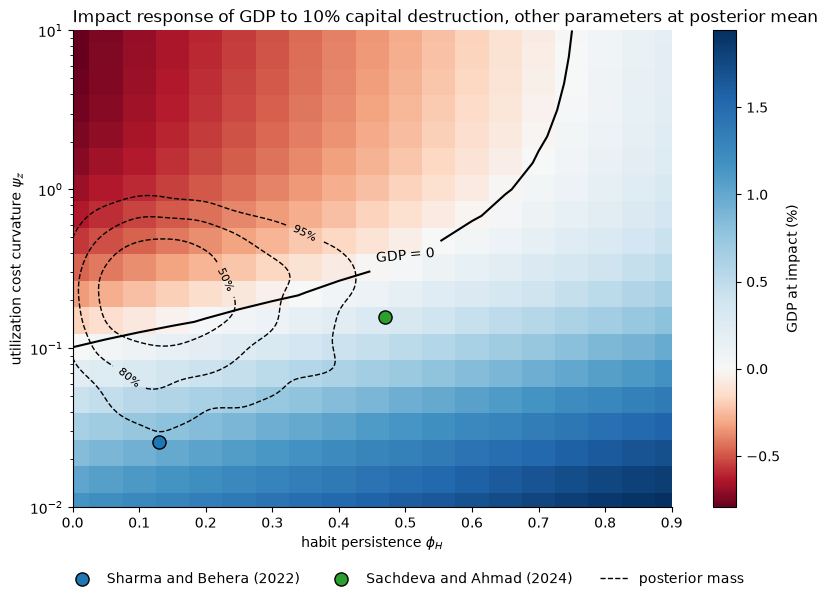

In [53]:
fig, ax = plot_impact_heatmap(impact_gdp_posterior)
add_posterior_contours(ax)
ax.set_title("Impact response of GDP to 10% capital destruction, other parameters at posterior mean", loc="left")
add_bottom_legend(fig, n_cols=3)

### Posterior impulse responses

The grid applies each estimated shock alone at one posterior standard deviation. The estimated shocks are correlated, so they are orthogonalized by a Cholesky factorization of each draw's covariance, with the foreign block first: world shocks may move Indian shocks within the quarter, and Indian shocks may not move world ones. The second figure is the 10% capital destruction of section 4, applied to the estimated model. Bands are 94% intervals over posterior draws.

In [54]:
FOREIGN_SHOCKS = ["epsilon_i_star", "epsilon_pi_star", "epsilon_Y_star", "epsilon_p_M_star"]

posterior_irfs = simulation_statespace.impulse_response_function(analysis_idata,
                                                                 n_steps=IRF_QUARTERS,
                                                                 orthogonalize_shocks=True,
                                                                 shock_order=[*FOREIGN_SHOCKS, ...],
                                                                 random_seed=20261014)["irf"]

Sampling: []


Output()

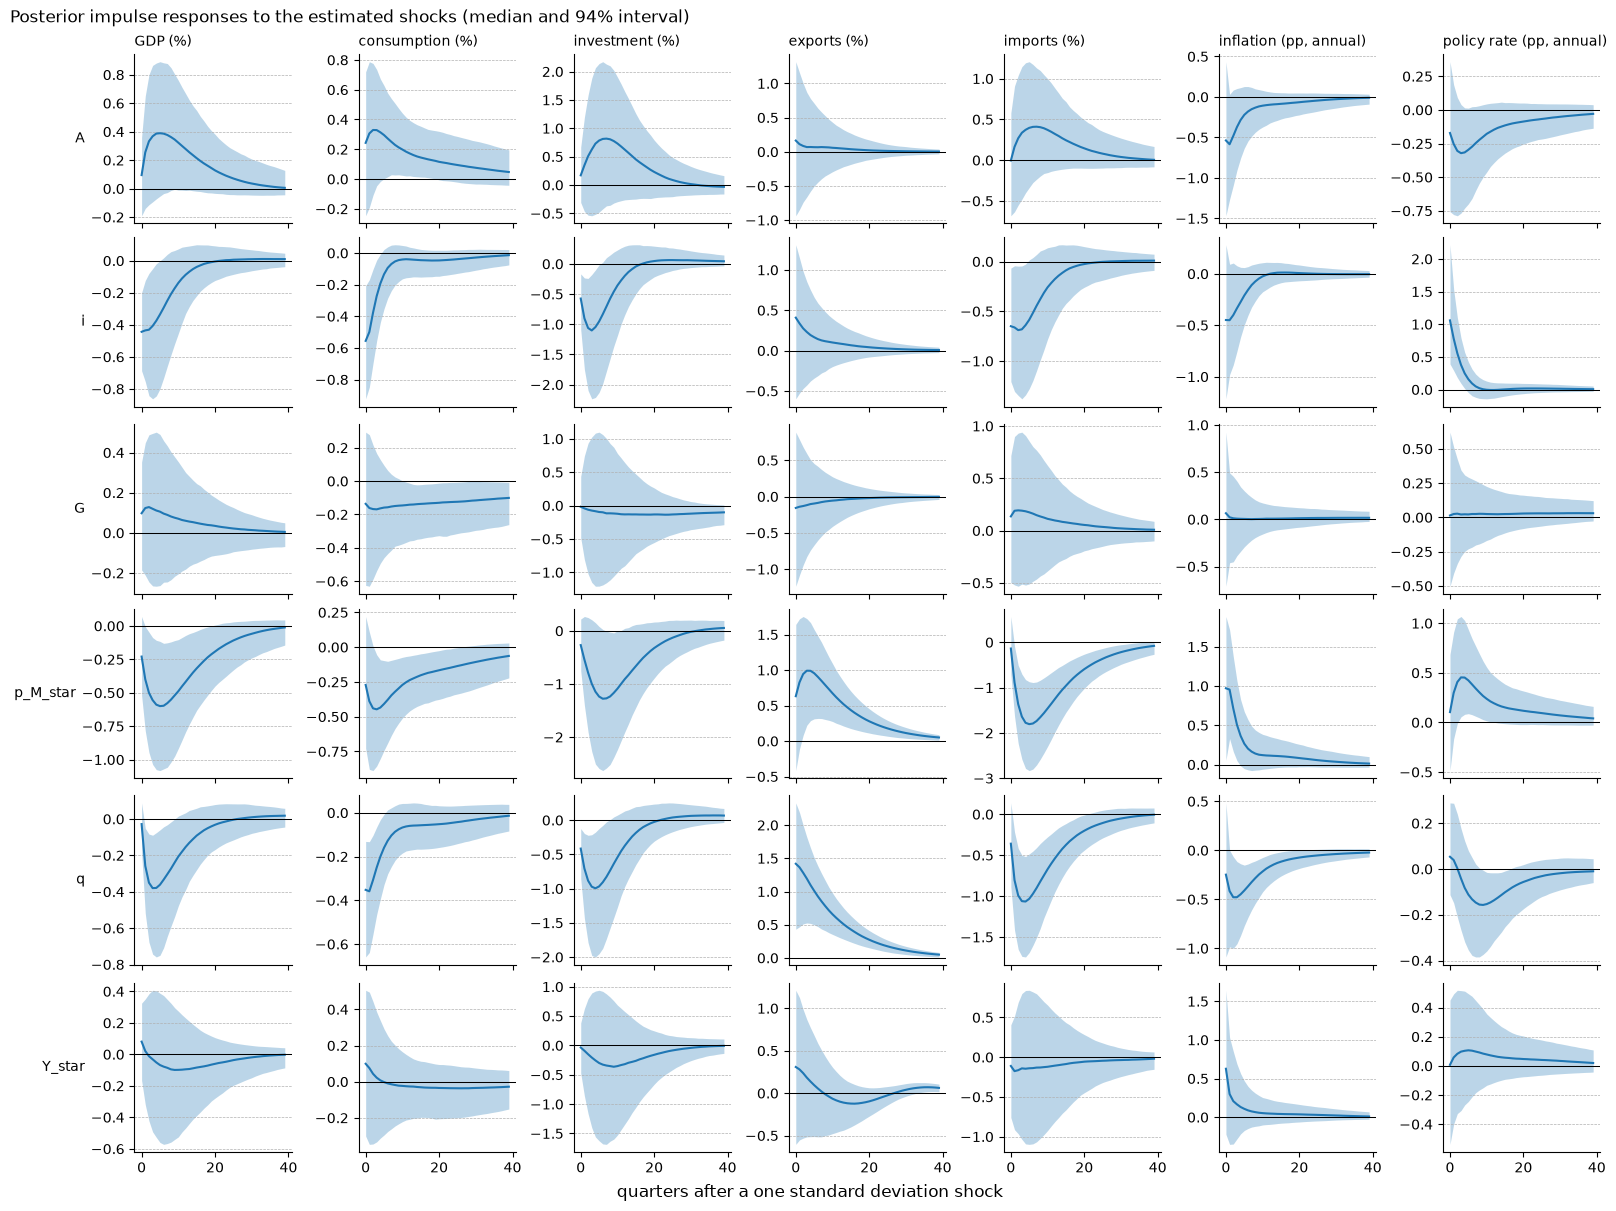

In [55]:
IRF_VARIABLES = ["GDP", "C", "I", "X", "M", "pi", "i"]
IRF_SHOCKS = [shock_name for shock_name in SHOCK_SIZES if shock_name != "epsilon_xi_K"]
IRF_QUANTILES = [0.03, 0.5, 0.97]

selected_irfs = posterior_irfs.sel(structural_shock=IRF_SHOCKS, state=IRF_VARIABLES).rename(state="variable")
display_irfs = xr.concat([to_display_units(irf=selected_irfs,
                                           variable=variable,
                                           policy_rate_ss=india_steady_state["i_ss"])
                          for variable in IRF_VARIABLES],
                         dim="variable")
irf_quantiles = display_irfs.quantile(IRF_QUANTILES, dim=["chain", "draw"])

fig, axes = plt.subplots(nrows=len(IRF_SHOCKS),
                         ncols=len(IRF_VARIABLES),
                         figsize=(16, 2 * len(IRF_SHOCKS)),
                         sharex=True,
                         layout="constrained")
for row, shock_name in enumerate(IRF_SHOCKS):
    for column, variable in enumerate(IRF_VARIABLES):
        ax = axes[row, column]
        response = irf_quantiles.sel(structural_shock=shock_name, variable=variable)
        ax.fill_between(response["time"],
                        response.sel(quantile=IRF_QUANTILES[0]),
                        response.sel(quantile=IRF_QUANTILES[-1]),
                        color=PALETTE["primary"],
                        alpha=0.3,
                        linewidth=0)
        ax.plot(response["time"],
                response.sel(quantile=0.5),
                color=PALETTE["primary"],
                lw=1.5)
        ax.axhline(0.0, color="k", lw=0.75)
        if row == 0:
            ax.set_title(VARIABLE_LABELS[variable], loc="left", fontsize=10)
        if column == 0:
            ax.set_ylabel(shock_name.removeprefix("epsilon_"),
                          rotation=0,
                          ha="right",
                          va="center")

fig.supxlabel("quarters after a one standard deviation shock")
fig.suptitle("Posterior impulse responses to the estimated shocks (median and 94% interval)",
             x=0.0,
             ha="left");

In [56]:
CAPITAL_DESTRUCTION_VARIABLES = ["GDP", "C", "I", "K", "L", "z", "X", "M"]

capital_destruction_trajectory = np.zeros((IRF_QUARTERS, len(simulation_shocks)))
capital_destruction_trajectory[0, simulation_shocks.index(DISASTER_SHOCK)] = SHOCK_SIZES[DISASTER_SHOCK]

capital_destruction_irf = simulation_statespace.impulse_response_function(analysis_idata,
                                                                          shock_trajectory=capital_destruction_trajectory,
                                                                          random_seed=20261014)["irf"]
selected_capital_destruction_irf = capital_destruction_irf.sel(state=CAPITAL_DESTRUCTION_VARIABLES)
capital_destruction_quantiles = 100 * selected_capital_destruction_irf.quantile(IRF_QUANTILES, dim=["chain", "draw"])

Sampling: []


Output()

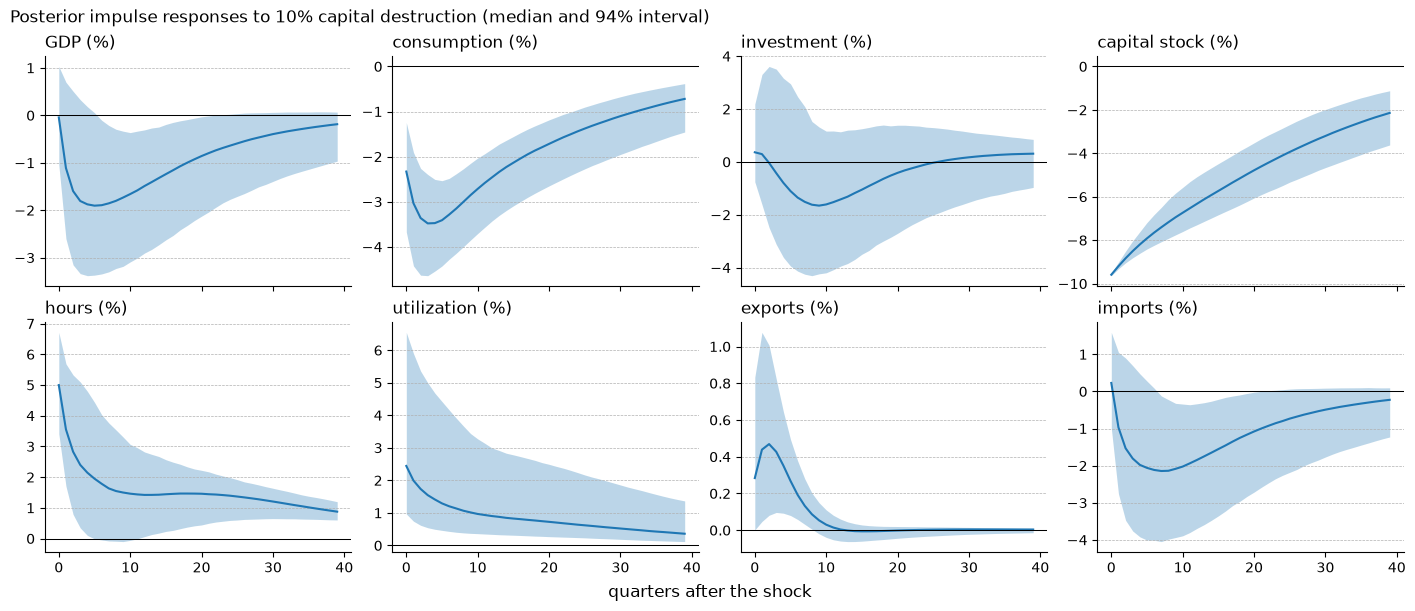

In [57]:
fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(14, 6),
                         sharex=True,
                         layout="constrained")
for ax, variable in zip(axes.ravel(), CAPITAL_DESTRUCTION_VARIABLES, strict=True):
    response = capital_destruction_quantiles.sel(state=variable)
    ax.fill_between(response["time"],
                    response.sel(quantile=IRF_QUANTILES[0]),
                    response.sel(quantile=IRF_QUANTILES[-1]),
                    color=PALETTE["primary"],
                    alpha=0.3,
                    linewidth=0)
    ax.plot(response["time"],
            response.sel(quantile=0.5),
            color=PALETTE["primary"],
            lw=1.5)
    ax.axhline(0.0, color="k", lw=0.75)
    ax.set_title(VARIABLE_LABELS[variable], loc="left")

fig.supxlabel("quarters after the shock")
fig.suptitle("Posterior impulse responses to 10% capital destruction (median and 94% interval)",
             x=0.0,
             ha="left");

### Counterfactual: 10% capital destruction in 2015Q1

The baseline is the economy as it stood in 2014Q4, left to evolve with no further shocks: for each posterior draw, the smoothed state at 2014Q4 propagated forward through the transition matrix, then re-trended with each series' mean growth. Real series and the debt ratio start from the data, and inflation is the model's own path around its steady state. The disaster's response sits on top of that baseline, so the band reflects parameter uncertainty alone. Levels are in trillion rupees per quarter at constant prices. Debt data are the IMF World Economic Outlook's fiscal-year series, held constant across the quarters of each fiscal year.

In [58]:
SHOCK_QUARTER = pd.Period("2015Q1", freq="Q")
BASELINE_QUARTER = SHOCK_QUARTER - 1
CRORE_PER_TRILLION_RUPEES = 1e5

fit_quarters = observed.index
data_dates = fit_quarters.to_timestamp()
outside_lockdown = observed["gdp_growth"].notna().to_numpy()
destruction_irf = capital_destruction_irf.rename(state="variable")

inflation_data = 400 * np.log(panel["cpi"]).diff().loc[fit_quarters]
# The WEO reports India by fiscal year, which starts in April, so January to March belongs to the year before.
fiscal_years = [quarter.year if quarter.quarter >= 2 else quarter.year - 1 for quarter in fit_quarters]
debt_data = pd.Series(100 * government_debt.reindex(fiscal_years).to_numpy(), index=fit_quarters)

In [59]:
solved_draws = posterior_draws["deterministic_norm"] <= 1e-6

state_path = [smoothed_states.sel(time=BASELINE_QUARTER.to_timestamp()).drop_vars("time")]
for _ in range(IRF_QUARTERS):
    state_path.append(xr.dot(transition, state_path[-1].rename(state="state_aux"), dim="state_aux"))
zero_shock_states = xr.concat(state_path, dim="time").where(solved_draws)
state_change = zero_shock_states - zero_shock_states.isel(time=0)

horizon = xr.DataArray(np.arange(IRF_QUARTERS + 1), dims=["time"])
irf_from_start = destruction_irf.drop_vars("time").pad(time=(1, 0), constant_values=0.0).where(solved_draws)

zero_shock_panels = {}
for title, (column, variable) in zip(["GDP", "Consumption", "Investment", "Exports", "Imports"],
                                     GROWTH_OBSERVABLES.values(),
                                     strict=True):
    data = panel[column].loc[fit_quarters] / CRORE_PER_TRILLION_RUPEES
    mean_growth = np.log(panel[column]).diff().loc[fit_quarters][outside_lockdown].mean()
    baseline = data.loc[BASELINE_QUARTER] * np.exp(mean_growth * horizon + state_change.sel(state=variable))
    zero_shock_panels[title] = {"unit": "trillion rupees per quarter",
                                "data": data,
                                "baseline": baseline,
                                "counterfactual": baseline * np.exp(irf_from_start.sel(variable=variable))}

inflation_baseline = (100 * QUARTERS_PER_YEAR
                      * (np.log(india_parameters["pi_bar"]) + zero_shock_states.sel(state="pi")))
zero_shock_panels["CPI inflation"] = {"unit": "% a year, annualized quarterly rate",
                                      "data": inflation_data,
                                      "baseline": inflation_baseline,
                                      "counterfactual": inflation_baseline
                                      + to_display_units(irf=irf_from_start,
                                                         variable="pi",
                                                         policy_rate_ss=india_steady_state["i_ss"])}

debt_baseline = debt_data.loc[BASELINE_QUARTER] * np.exp(state_change.sel(state="B")
                                                         - state_change.sel(state="GDP"))
zero_shock_panels["Government debt"] = {"unit": "% of annual GDP",
                                        "data": debt_data,
                                        "baseline": debt_baseline,
                                        "counterfactual": debt_baseline
                                        * np.exp(irf_from_start.sel(variable="B") - irf_from_start.sel(variable="GDP"))}

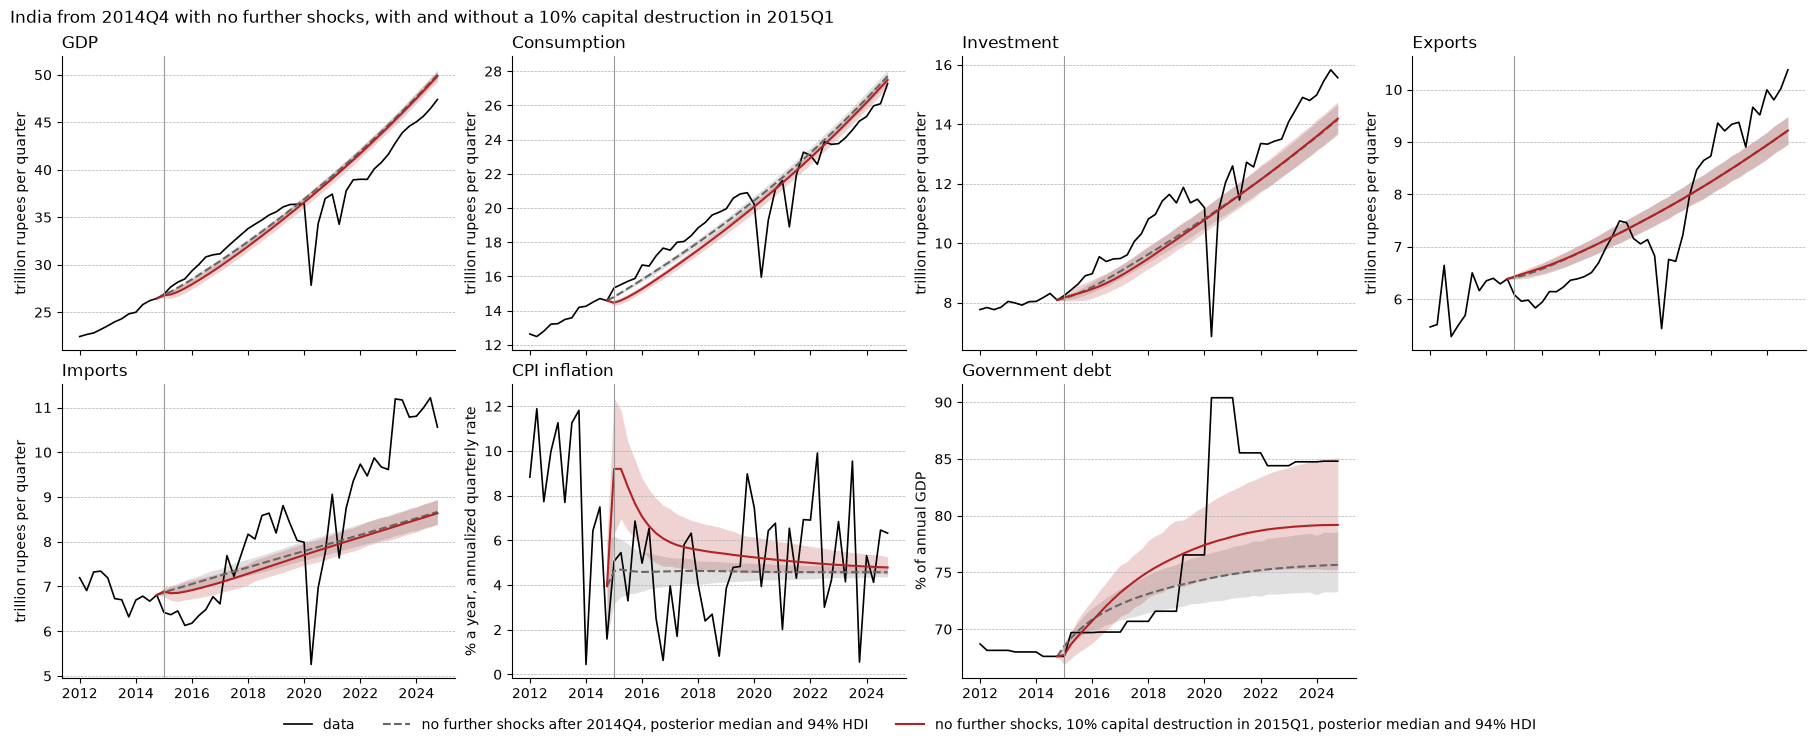

In [60]:
zero_shock_dates = pd.period_range(start=BASELINE_QUARTER, periods=IRF_QUARTERS + 1, freq="Q").to_timestamp()

fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(18, 7),
                         sharex=True,
                         layout="constrained")
for ax, (title, series) in zip(axes.flat, zero_shock_panels.items()):
    ax.plot(data_dates,
            series["data"],
            color="k",
            lw=1.2,
            label="data")
    for path, color, linestyle, label in [(series["baseline"], "0.4", "--", "no further shocks after 2014Q4"),
                                          (series["counterfactual"],
                                           DESTRUCTION_COLOR,
                                           "-",
                                           "no further shocks, 10% capital destruction in 2015Q1")]:
        median, interval = median_and_hdi(path)
        ax.fill_between(zero_shock_dates,
                        interval.sel(ci_bound="lower"),
                        interval.sel(ci_bound="upper"),
                        color=color,
                        alpha=0.2,
                        linewidth=0)
        ax.plot(zero_shock_dates,
                median,
                color=color,
                ls=linestyle,
                lw=1.5,
                label=f"{label}, posterior median and 94% HDI")
    ax.axvline(SHOCK_QUARTER.to_timestamp(), color="0.6", lw=0.8)
    ax.set_title(title, loc="left")
    ax.set_ylabel(series["unit"])
axes.flat[-1].set_axis_off()

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(labels),
           frameon=False)
fig.suptitle("India from 2014Q4 with no further shocks, with and without a 10% capital destruction in 2015Q1",
             x=0.0,
             ha="left");

Losses are the counterfactual minus the baseline, summed per posterior draw over each window, in trillion rupees and as a share of the variable's annual total in the year before the shock.

In [61]:
base_year = SHOCK_QUARTER.year - 1
last_year = (SHOCK_QUARTER + IRF_QUARTERS - 1).year
loss_windows = {f"{SHOCK_QUARTER.year} (shock year)": slice(0, 4),
                f"{SHOCK_QUARTER.year + 1} to {last_year}": slice(4, None),
                f"{SHOCK_QUARTER.year} to {last_year}": slice(None)}

zero_shock_impact_rows = {}
for title in ["GDP", "Consumption", "Investment", "Exports", "Imports"]:
    series = zero_shock_panels[title]
    loss = (series["counterfactual"] - series["baseline"]).isel(time=slice(1, None))
    base_year_total = series["data"][series["data"].index.year == base_year].sum()

    for window, quarters in loss_windows.items():
        window_loss = loss.isel(time=quarters).sum("time", skipna=False)
        zero_shock_impact_rows[(title, window)] = {
            ("trillion rupees", "mean"): float(window_loss.mean()),
            ("trillion rupees", "5%"): float(window_loss.quantile(0.05)),
            ("trillion rupees", "95%"): float(window_loss.quantile(0.95)),
            (f"% of {base_year} annual", "mean"): float(100 * window_loss.mean() / base_year_total),
            (f"% of {base_year} annual", "5%"): float(100 * window_loss.quantile(0.05) / base_year_total),
            (f"% of {base_year} annual", "95%"): float(100 * window_loss.quantile(0.95) / base_year_total)}

zero_shock_impact_table = pd.DataFrame.from_dict(zero_shock_impact_rows, orient="index")
zero_shock_impact_table.columns = pd.MultiIndex.from_tuples(zero_shock_impact_table.columns)
zero_shock_impact_table.style.format("{:.2f}")

### Welfare cost of the 2015 disaster

The welfare cost is the consumption-equivalent variation $\lambda$, the permanent percentage change in consumption that changes lifetime utility $U_t = u_t + \beta_t \mathbb{E}_t U_{t+1}$ by as much as the disaster does. Period utility is the model's own,

$$u_t = \frac{(C_t - \phi_H C_{t-1})^{1 - \sigma}}{1 - \sigma} - \Theta \, \nu_{w,t} \frac{L_t^{1 + \chi}}{1 + \chi}$$

To first order the disaster moves lifetime utility by the discounted sum of its effect on each quarter's utility, and scaling consumption by $1 + \lambda$ moves it by $\lambda (C (1 - \phi_H))^{1 - \sigma} / (1 - \beta)$:

$$\begin{aligned}
\Delta U &= (C (1 - \phi_H))^{-\sigma} (1 - \beta \phi_H) \, C \sum_{t \geq 1} \beta^{t-1} \hat{C}_t - \Theta \, \nu_w L^{1 + \chi} \sum_{t \geq 1} \beta^{t-1} \left(\hat{L}_t + \frac{\hat{\nu}_{w,t}}{1 + \chi}\right) \\
\lambda &= \frac{(1 - \beta) \, \Delta U}{(C (1 - \phi_H))^{1 - \sigma}}
\end{aligned}$$

Hats are the disaster's log deviations, and the discounted sums are $(I - \beta T)^{-1} R \, \varepsilon_{\xi_K}$ in the simulation statespace. The steady state and both matrices are the statespace's symbolic graphs, so the cost is a deterministic of the estimation model and is evaluated over the posterior with `pm.compute_deterministics`. At first order the cost does not depend on the state the economy is in when the disaster arrives, so it is the same from 2014Q4 as from the steady state.

The figure prices the cost as the one-off consumption transfer in 2015Q1 that leaves the household as well off as without the disaster, $\Delta U$ divided by the marginal utility of 2015Q1 consumption $(C (1 - \phi_H))^{-\sigma} (1 - \beta \phi_H)$. The transfer is in quarters of steady-state consumption, converted to rupees at 2014Q4 consumption. Its consumption and hours components add up to the total.

In [62]:
def bind_to_model(graphs, model):
    """Replace the statespace parameter placeholders in `graphs` with the model variables of the same name."""
    placeholders = [variable for variable in explicit_graph_inputs(graphs) if variable.name in model.named_vars]
    return graph_replace(graphs,
                         replace={variable: model[variable.name] for variable in placeholders},
                         strict=False)


simulation_states = list(simulation_statespace.state_names)
simulation_steady_state = {variable.name: value
                           for variable, value in simulation_statespace.steady_state_mapping.items()}

with fit_model.copy() as welfare_model:
    transition, selection, consumption_ss, hours_ss, wage_dispersion_ss = bind_to_model(
        graphs=[simulation_statespace.ssm["transition"],
                simulation_statespace.ssm["selection"],
                simulation_steady_state["C_ss"],
                simulation_steady_state["L_ss"],
                simulation_steady_state["nu_w_ss"]],
        model=welfare_model)
    discount = welfare_model["beta"]
    habit = welfare_model["phi_H"]
    risk_aversion = welfare_model["sigma"]
    inverse_frisch = welfare_model["chi"]

    disaster_impact = selection[:, simulation_shocks.index(DISASTER_SHOCK)] * SHOCK_SIZES[DISASTER_SHOCK]
    discounted_response = pt.linalg.solve(pt.eye(len(simulation_states)) - discount * transition,
                                          disaster_impact)
    consumption_response, hours_response, wage_dispersion_response = (
        discounted_response[simulation_states.index(name)] for name in ["C", "L", "nu_w"])

    habit_adjusted_consumption = consumption_ss * (1 - habit)
    labor_disutility = welfare_model["Theta"] * wage_dispersion_ss * hours_ss ** (1 + inverse_frisch)
    marginal_utility_of_consumption = habit_adjusted_consumption ** -risk_aversion * (1 - discount * habit)
    consumption_value = marginal_utility_of_consumption * consumption_ss * consumption_response
    hours_value = -labor_disutility * (hours_response + wage_dispersion_response / (1 + inverse_frisch))
    value_of_permanent_consumption = habit_adjusted_consumption ** (1 - risk_aversion) / (1 - discount)
    value_of_one_quarter_of_consumption = marginal_utility_of_consumption * consumption_ss

    for suffix, value in [("_consumption", consumption_value),
                          ("_hours", hours_value),
                          ("", consumption_value + hours_value)]:
        pm.Deterministic(f"welfare_cost{suffix}", value / value_of_permanent_consumption)
        pm.Deterministic(f"compensating_transfer{suffix}", value / value_of_one_quarter_of_consumption)

In [63]:
WELFARE_COMPONENTS = {"": "total",
                      "_consumption": "consumption",
                      "_hours": "hours and wage dispersion"}

welfare_costs = pm.compute_deterministics(posterior_draws,
                                          model=welfare_model,
                                          var_names=[f"{measure}{suffix}"
                                                     for measure in ["welfare_cost", "compensating_transfer"]
                                                     for suffix in WELFARE_COMPONENTS]).where(solved_draws)

Output()

In [64]:
WELFARE_INTERVAL_PROBABILITY = 0.98


def plot_clipped_densities(samples, colors, xlabel, title, mean_labels="curve"):
    """Overlay the density of each variable in `samples` over its HDI, with each posterior mean marked and labeled.

    Parameters
    ----------
    samples : Dataset
        One variable per density, with a ``sample`` dimension.
    colors : list of str
        One color per variable.
    xlabel, title : str
        Axis label and figure title.
    mean_labels : {"curve", "legend"}, optional
        Label each mean above the curves, or in the legend entries when the means sit too close together to label
        apart. Default "curve".
    """
    if mean_labels == "legend":
        samples = samples.rename({name: f"{name}, mean {float(samples[name].mean()):.3g}" for name in samples})

    intervals = az.hdi(samples, prob=WELFARE_INTERVAL_PROBABILITY, dim=["sample"])
    densities = az.kde(samples, dim="sample")
    grid = densities.sel(plot_axis="x")
    inside_interval = (grid >= intervals.sel(ci_bound="lower")) & (grid <= intervals.sel(ci_bound="upper"))
    clipped = xr.Dataset({name: density.where(inside_interval[name]).assign_attrs(kind="kde")
                          for name, density in densities.items()})

    plot = az.plot_dist(samples,
                        sample_dims=["sample"],
                        kind="kde",
                        ci_kind="hdi",
                        ci_prob=WELFARE_INTERVAL_PROBABILITY,
                        point_estimate="mean",
                        cols=[],
                        aes={"color": ["__variable__"]},
                        aes_by_visuals={"point_estimate": ["color"]},
                        color=colors,
                        stats={"dist": clipped},
                        visuals={"face": True,
                                 "credible_interval": False,
                                 "point_estimate_text": False,
                                 "title": False},
                        figure_kwargs={"figsize": (9, 4)})
    plot.add_legend("__variable__",
                    title=f"{WELFARE_INTERVAL_PROBABILITY:.0%} HDI",
                    loc="upper center",
                    bbox_to_anchor=(0.5, 0.0),
                    ncol=len(samples.data_vars),
                    frameon=False)

    ax = plt.gcf().axes[0]
    if mean_labels == "curve":
        density_x = clipped.to_array("component").sel(plot_axis="x").to_numpy()
        density_y = clipped.to_array("component").sel(plot_axis="y").to_numpy()
        label_half_width = 0.05 * (np.nanmax(density_x) - np.nanmin(density_x))
        label_pad = 0.03 * np.nanmax(density_y)
        for name, color in zip(samples, colors, strict=True):
            mean = float(samples[name].mean())
            near_mean = np.abs(density_x - mean) <= label_half_width
            label_height = np.nanmax(np.where(near_mean, density_y, np.nan)) + label_pad
            ax.vlines(x=mean,
                      ymin=0.0,
                      ymax=label_height,
                      color=color,
                      lw=0.8,
                      ls=":")
            ax.text(mean,
                    label_height,
                    f"mean {mean:.3g}",
                    ha="center",
                    va="bottom",
                    color=color,
                    fontsize=9)
    ax.axvline(0.0, color="0.6", lw=0.8)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    return ax


def stack_solved_draws(dataset):
    return dataset.stack(sample=("chain", "draw")).dropna("sample").drop_vars(["sample", "chain", "draw"])

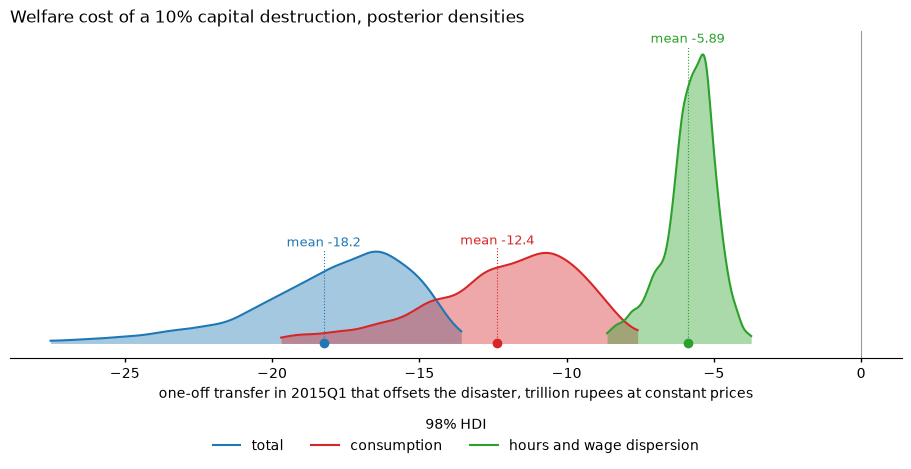

In [65]:
baseline_quarterly_consumption = zero_shock_panels["Consumption"]["data"].loc[BASELINE_QUARTER]
transfers = xr.Dataset({label: baseline_quarterly_consumption * welfare_costs[f"compensating_transfer{suffix}"]
                        for suffix, label in WELFARE_COMPONENTS.items()})

plot_clipped_densities(samples=stack_solved_draws(transfers),
                       colors=[PALETTE["primary"], PALETTE["secondary"], "tab:green"],
                       xlabel=f"one-off transfer in {SHOCK_QUARTER} that offsets the disaster, trillion rupees at "
                              "constant prices",
                       title="Welfare cost of a 10% capital destruction, posterior densities");

### Nonlinear welfare cost under perfect foresight

The same disaster, solved in the nonlinear model under perfect foresight: households are surprised by the destruction in 2015Q1 and expect no further shocks. Lifetime utility $U$ and its consumption part $U_C = (C - \phi_H C_{-1})^{1-\sigma} / (1 - \sigma) + \beta \, \mathbb{E} \, U_{C,+1}$ are model variables, so their 2015Q1 values on the baseline and disaster paths give the consumption-equivalent variation exactly:

$$
(1 + \lambda)^{1 - \sigma} = \frac{U^{d} - U^{b} + U^{b}_C}{U^{b}_C}
$$

From the steady state the baseline is the steady state itself, so each draw needs one solve there and two from its smoothed 2014Q4 state. The gap between the two starting points is the state dependence the first-order cost cannot have, and the gap between either and the first-order cost is the nonlinearity. The shock is the same as in the first-order cost. Every posterior draw is solved, in parallel worker processes.

Draws on which Newton's method fails are left out of the comparison below, which uses only the draws every method solves. The solver's homotopy fallback is off. On this posterior it recovers almost none of the failed draws and multiplies the runtime.

In [66]:
PERFECT_FORESIGHT_QUARTERS = 400
WELFARE_WORKERS = 10

disaster_shocks = {DISASTER_SHOCK: np.r_[SHOCK_SIZES[DISASTER_SHOCK], np.zeros(PERFECT_FORESIGHT_QUARTERS - 1)]}
posterior_draw_shape = (posterior_draws.sizes["chain"], posterior_draws.sizes["draw"])
chain_draw_pairs = list(product(posterior_draws["chain"].values, posterior_draws["draw"].values))

# The estimation model also smooths measurement-noise states, which the simulation model does not have.
simulation_variables = {variable.base_name for variable in model.variables}
smoothed_start_levels = statespace.deviations_to_levels(smoothed_states.sel(time=BASELINE_QUARTER.to_timestamp()),
                                                        statespace_idata)
smoothed_start_levels = smoothed_start_levels.sel(state=[state for state in smoothed_start_levels["state"].values
                                                         if state in simulation_variables])


def parameters_and_steady_state(chain, draw):
    parameters = draw_parameters(posterior_draws, chain=chain, draw=draw)
    steady_state = model.steady_state(verbose=False,
                                      progressbar=False,
                                      **parameters)
    return parameters, steady_state


def solve_path(parameters, steady_state, initial_conditions=None, shocks=None):
    """The perfect-foresight path in levels, or None when the solver fails."""
    trajectory, result = ge.solve_perfect_foresight(model,
                                                    simulation_length=PERFECT_FORESIGHT_QUARTERS,
                                                    x0=dict(steady_state),
                                                    initial_conditions=initial_conditions,
                                                    shocks=shocks,
                                                    steady_state_kwargs=parameters,
                                                    sparse_root_kwargs={"progressbar": False},
                                                    max_homotopy_solves=0)
    return trajectory if result.success else None


def lifetime_utility_in_2015q1(parameters, steady_state, initial_conditions=None, shocks=None):
    """Lifetime utility and its consumption part in the first quarter of the perfect-foresight path."""
    trajectory = solve_path(parameters=parameters,
                            steady_state=steady_state,
                            initial_conditions=initial_conditions,
                            shocks=shocks)
    if trajectory is None:
        return np.nan, np.nan
    return trajectory["U"].iloc[0], trajectory["U_C"].iloc[0]


def consumption_equivalent(baseline, disaster, risk_aversion):
    (baseline_utility, baseline_consumption_utility), (disaster_utility, _) = baseline, disaster
    ratio = (disaster_utility - baseline_utility + baseline_consumption_utility) / baseline_consumption_utility
    return ratio ** (1 / (1 - risk_aversion)) - 1


def map_over_posterior_draws(function):
    """Apply `function` to every (chain, draw) pair in worker processes forked from this kernel."""
    with warnings.catch_warnings():
        # The workers run only the compiled model residuals and scipy, never JAX, so forking after JAX has started
        # its threads is safe here.
        warnings.filterwarnings("ignore", message=r"os\.fork\(\) was called")
        with ProcessPoolExecutor(max_workers=WELFARE_WORKERS,
                                 mp_context=multiprocessing.get_context("fork")) as pool:
            try:
                return list(tqdm(pool.map(function, chain_draw_pairs),
                                 total=len(chain_draw_pairs),
                                 desc="posterior draws"))
            except KeyboardInterrupt:
                # Queued draws are dropped so an interrupt waits only for the draws already running.
                pool.shutdown(wait=False, cancel_futures=True)
                raise

In [67]:
risk_aversion = float(india_model_parameters["sigma"])


def nonlinear_welfare_costs_for_draw(chain_draw):
    """Consumption-equivalent cost of the disaster for one draw, from the steady state and from 2014Q4."""
    chain, draw = chain_draw
    parameters, steady_state = parameters_and_steady_state(chain=chain, draw=draw)
    start = smoothed_start_levels.sel(chain=chain, draw=draw).reset_coords(drop=True)

    disaster_from_steady_state = lifetime_utility_in_2015q1(parameters=parameters,
                                                            steady_state=steady_state,
                                                            shocks=disaster_shocks)
    baseline_from_start = lifetime_utility_in_2015q1(parameters=parameters,
                                                     steady_state=steady_state,
                                                     initial_conditions=start)
    disaster_from_start = lifetime_utility_in_2015q1(parameters=parameters,
                                                     steady_state=steady_state,
                                                     initial_conditions=start,
                                                     shocks=disaster_shocks)
    return (consumption_equivalent(baseline=(steady_state["U_ss"], steady_state["U_C_ss"]),
                                   disaster=disaster_from_steady_state,
                                   risk_aversion=risk_aversion),
            consumption_equivalent(baseline=baseline_from_start,
                                   disaster=disaster_from_start,
                                   risk_aversion=risk_aversion))


costs = map_over_posterior_draws(nonlinear_welfare_costs_for_draw)
nonlinear_welfare_costs = xr.Dataset({name: (("chain", "draw"), np.reshape([cost[column] for cost in costs],
                                                                           posterior_draw_shape))
                                      for column, name in enumerate(["from the steady state", "from 2014Q4"])},
                                     coords={"chain": posterior_draws["chain"], "draw": posterior_draws["draw"]})
nonlinear_welfare_costs = nonlinear_welfare_costs.where(solved_draws)

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

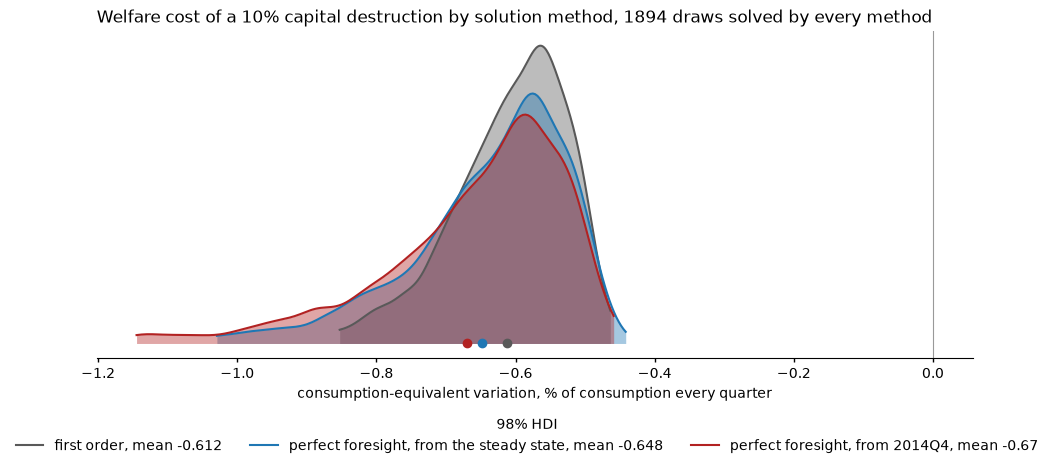

In [68]:
welfare_cost_comparison = 100 * xr.Dataset({"first order": welfare_costs["welfare_cost"],
                                           **{f"perfect foresight, {name}": cost
                                              for name, cost in nonlinear_welfare_costs.items()}})
comparison_samples = stack_solved_draws(welfare_cost_comparison)

plot_clipped_densities(samples=comparison_samples,
                       colors=["0.35", PALETTE["primary"], DESTRUCTION_COLOR],
                       xlabel="consumption-equivalent variation, % of consumption every quarter",
                       title=f"Welfare cost of a 10% capital destruction by solution method, "
                             f"{comparison_samples.sizes['sample']} draws solved by every method",
                       mean_labels="legend");

### Perfect-foresight paths against first order

The disaster from the steady state, so the first-order paths are the posterior impulse responses above, on the same thinned draws. Draws the perfect-foresight solver fails on are dropped from both.

In [69]:
def disaster_response_from_steady_state(chain_draw):
    """Percent deviations from steady state of the disaster's perfect-foresight path for one draw."""
    chain, draw = chain_draw
    parameters, steady_state = parameters_and_steady_state(chain=chain, draw=draw)
    trajectory = solve_path(parameters=parameters,
                            steady_state=steady_state,
                            shocks=disaster_shocks)
    if trajectory is None:
        return np.full((IRF_QUARTERS, len(CAPITAL_DESTRUCTION_VARIABLES)), np.nan)
    levels = trajectory[CAPITAL_DESTRUCTION_VARIABLES].iloc[:IRF_QUARTERS].to_numpy()
    steady_levels = np.array([steady_state[f"{name}_ss"] for name in CAPITAL_DESTRUCTION_VARIABLES])
    return 100 * np.log(levels / steady_levels)


responses = map_over_posterior_draws(disaster_response_from_steady_state)
perfect_foresight_response = xr.DataArray(np.reshape(responses, (*posterior_draw_shape, IRF_QUARTERS, -1)),
                                          dims=["chain", "draw", "time", "variable"],
                                          coords={"chain": posterior_draws["chain"],
                                                  "draw": posterior_draws["draw"],
                                                  "variable": CAPITAL_DESTRUCTION_VARIABLES})
perfect_foresight_solved = perfect_foresight_response.notnull().all(["time", "variable"])
first_order_response = (100 * capital_destruction_irf.sel(state=CAPITAL_DESTRUCTION_VARIABLES)
                        .rename(state="variable")
                        .drop_vars("time"))

posterior draws:   0%|          | 0/2000 [00:00<?, ?it/s]

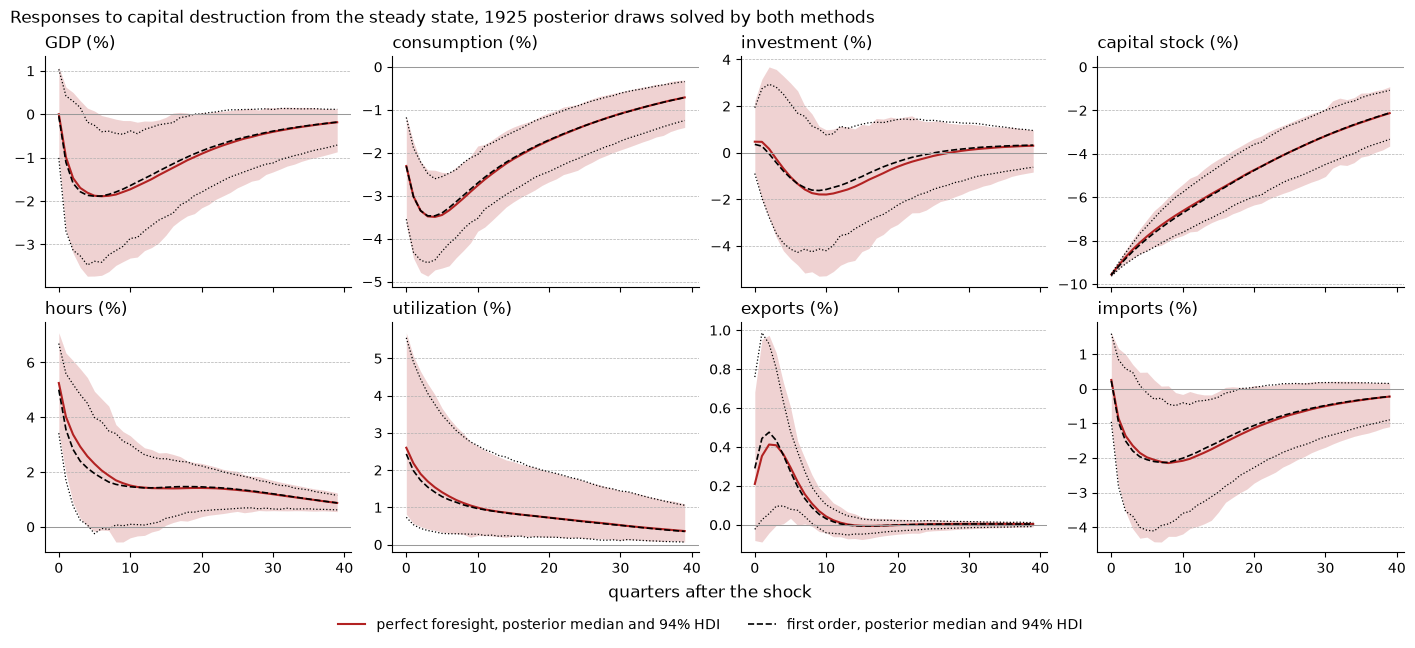

In [70]:
comparison_mask = perfect_foresight_solved & solved_draws
quarters = np.arange(IRF_QUARTERS)

fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(14, 6),
                         sharex=True,
                         layout="constrained")
for ax, variable in zip(axes.ravel(), CAPITAL_DESTRUCTION_VARIABLES, strict=True):
    nonlinear_median, nonlinear_interval = median_and_hdi(perfect_foresight_response.sel(variable=variable)
                                                          .where(comparison_mask))
    linear_median, linear_interval = median_and_hdi(first_order_response.sel(variable=variable)
                                                    .where(comparison_mask))
    ax.fill_between(quarters,
                    nonlinear_interval.sel(ci_bound="lower"),
                    nonlinear_interval.sel(ci_bound="upper"),
                    color=DESTRUCTION_COLOR,
                    alpha=0.2,
                    linewidth=0)
    ax.plot(quarters,
            nonlinear_median,
            color=DESTRUCTION_COLOR,
            lw=1.5,
            label="perfect foresight, posterior median and 94% HDI")
    ax.plot(quarters,
            linear_median,
            color="k",
            ls="--",
            lw=1.2,
            label="first order, posterior median and 94% HDI")
    for bound in ["lower", "upper"]:
        ax.plot(quarters,
                linear_interval.sel(ci_bound=bound),
                color="k",
                ls=":",
                lw=0.9)
    ax.axhline(0.0, color="0.6", lw=0.75)
    ax.set_title(VARIABLE_LABELS[variable], loc="left")

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(labels),
           frameon=False)
fig.supxlabel("quarters after the shock")
fig.suptitle(f"Responses to capital destruction from the steady state, {int(comparison_mask.sum())} posterior draws "
             "solved by both methods",
             x=0.0,
             ha="left");